# EDA OpenForensics

Для всех четырех ноутбуков и скриптов препроцессинга используется одна общая среда deepfake из корневого environment.yml. Сохраненные outputs относятся к предыдущему прогону; при текущей статической проверке ноутбук не выполнялся.

**Годовой проект №35, НИУ ВШЭ: детекция дипфейков на фотографиях лиц.**
Датасет: OpenForensics (Le et al., ICCV 2021), оригинальная версия с Zenodo (запись 5528418, CC BY 4.0).

### Задача и главный вопрос

Модель должна по фото лица отвечать: настоящее лицо (**real**) или подделка (**fake**). Главный риск
такой задачи называется **шорткат**: модель учится не на следах подделки, а на побочном признаке,
который случайно связан с меткой в обучающих данных. Например, если поддельные лица в среднем крупнее
настоящих, модель выучит размер лица, покажет отличный результат на нашем датасете и провалится на
реальных фото. Поэтому главный вопрос этого анализа:

> **Что, кроме самой подделки, отличает в данных real от fake, и что с этим делать?**

Отдельно разбираем четыре условия съёмки, от которых зависит, где модели можно будет верить: **какую
долю кадра занимает лицо (лицо и фон), под каким углом повёрнута голова, только ли анфас в данных и какое
освещение.** На каждый вопрос отвечаем в двух смыслах:
«что вообще есть в данных» и «различается ли это у real и fake».

### Порядок анализа

1. **Датасет**: что лежит в данных, как сделаны фейки, базовая статистика и баланс классов.
2. **Дубли и утечки**: нет ли одних и тех же фото в обучении и тесте (иначе все метрики ложные).
3. **Объект анализа и надёжность меток**: что подаём модели и где метка может врать.
4. **Визуальный осмотр**: как выглядят подделки вблизи.
5. **Анкета на каждое лицо**: превращаем лицо в строку чисел (поза, свет, чёткость).
6. **Проверка анкеты**: типичные значения, пропуски, ошибки и выбросы.
7. **Условия съёмки**: лицо и фон, угол, анфас, освещение.
8. **Первая модель**: насколько легко найти подделку, на что смотрит модель и не жульничает ли она,
   какие искажения картинки при обучении помогают. Её качество становится линейкой (baseline) проекта.

Шаги 1–4 отвечают на вопрос «можно ли доверять данным», шаги 5–7 на вопрос «чем real и fake
различаются помимо подделки», шаг 8 на вопрос «что из этого следует для модели». В конце общий итог,
опасные моменты и решения для обучения. Технические проверки (чтение файлов, EXIF, JPEG, геометрия
разметки) вынесены в **приложение**.

**Цвета.** На фото рамка real **зелёная** с буквой **R**, рамка fake **красная** с буквой **F**,
маска лица закрашена тем же цветом. На графиках real бирюзово-зелёный, fake оранжевый (эта пара
различима и при нарушениях цветового зрения).

### Методы анализа, взятые из литературы

Методы ниже стандартны для аудита датасетов дипфейков и встроены в анализ там, где они нужны.

| Метод | Откуда | Зачем он нам |
| --- | --- | --- |
| Паспорт датасета: источник, состав, способ создания | Datasheets for Datasets (Gebru et al., 2021) | понимать, что именно называется фейком |
| Поиск дублей: перцептивный хэш, затем проверка пикселями | Barz & Denzler 2020 (дубли train/test в CIFAR) | утечка завышает метрики |
| Деление данных по группам (люди, исходные фото), а не по картинкам | DFDC 2020, DeeperForensics 2020 | честная кросс-валидация |
| Кроп ×1,3 вокруг лица, 256×256 | FaceForensics++ 2019, DeepfakeBench 2023 | сравнимость со статьями |
| Проверка формата файлов (JPEG, размер) как шортката | «Fake or JPEG?» (Grommelt et al., 2024) | самый частый шорткат в датасетах генерации |
| Атрибуты лиц с отдельной категорией «не измерено» | Xu et al. 2022; Lutz & Bassett 2021 | ошибки измерителя не должны маскироваться под данные |
| Описательная таблица и проверка баланса групп (SMD) | стандарт эконометрики и оценки причинных эффектов (Austin, 2009) | видно, чем различаются real и fake помимо подделки |
| Сравнения внутри подгрупп (парадокс Симпсона) | Trinh & Liu 2021 | общий вывод может перевернуться внутри групп |

### Как подготовить среду и данные

Команды выполняются из корня репозитория. Общий setup устанавливает зависимости ноутбуков и скриптов и регистрирует ядро deepfake:

```bash
bash scripts/setup_environment.sh
source "${CONDA_ROOT:-$HOME/miniconda3}/etc/profile.d/conda.sh"
conda activate deepfake
bash scripts/download_models.sh --include-baseline
bash scripts/download_datasets.sh --datasets openforensics --limit 70300 --seed 42
```

Загрузчик данных сохраняет все 70 300 размеченных исходных кадров и JSON авторских Train, Val, Test-Dev в data/raw/openforensics. Эта команда только загружает данные, без препроцессинга или обучения. Флаг --include-baseline добавляет ResNet18 к YuNet и MediaPipe для раздела 8.

Для другого расположения данных задайте DEEPFAKE_DATA_ROOT перед загрузкой и запуском Jupyter. Это корень raw-данных, внутри него должна находиться папка openforensics. Откройте ноутбук и выберите ядро deepfake. Поиск ROOT работает из корня и любой его подпапки, включая notebooks; helper-модули импортируются из ROOT/src/notebook_src.

Первая кодовая ячейка при отсутствии кешей запускает of_scan, of_unlabeled и of_attributes: читает изображения, прогоняет YuNet/MediaPipe и пишет кеши в data/processed/openforensics. Ячейка сохранения атрибутов пишет results/openforensics/attributes.parquet. Раздел 8 через B.ensure_baseline обучает модели, сохраняет кропы, признаки и веса в кеш, а scores, логи и итоговые метрики в results/openforensics/baseline. Последующие ячейки выполняют inference, Grad-CAM и UMAP. Сохраненные результаты доступны для чтения; полный повторный прогон требует данных и занимает существенно больше времени.


Поддерживается неполная загрузка датасета. Для каждого авторского сплита загрузчик показывает число доступных кадров и лиц рядом с полным числом в разметке. Статистика считается только по доступным кадрам. Сохранённые выходы относятся к исходному полному прогону, пока ноутбук не выполнен заново.


In [1]:
import sys, json, time, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, cv2
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, spearmanr, mannwhitneyu, ks_2samp
from statsmodels.stats.proportion import proportion_confint

ROOT = next(
    (path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (path / "src" / "notebook_src").is_dir() and (path / "notebooks").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки внутри репозитория")
sys.path.insert(0, str(ROOT / "src"))
from notebook_src.of_data import (SPLITS, CACHE, RESULTS, IMAGES, ANNOT, PLOT_COLOR, SPLIT_COLOR, SEED, BOX_RGB,
                     load_all, cache_ready, sample_rows, read_rgb, polygon_mask, polygon_area, crop_face, square_box, draw_faces, dhash)
from notebook_src.of_dedup import close_pairs, pixel_check, groups_from_pairs, iou, bitwise_count
import torch                                          # нейросеть (раздел 8)
from notebook_src.of_metrics import basic, boot_ci, report, ece    # метрики качества модели (раздел 8)
from notebook_src import of_baseline as B                               # кропы, FFT, ResNet-18 (раздел 8)

warnings.filterwarnings("ignore", category=FutureWarning)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:,.3f}".format)
get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'pil_kwargs': {'quality': 88}, 'bbox_inches': 'tight'}")
mpl.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titlesize": 11})

# Разметка (JSON) и кэши тяжёлых расчётов. Если кэша нет, скрипт посчитает его заново.
frames, faces = load_all()
from notebook_src import of_data
IMAGES, ANNOT = of_data.IMAGES, of_data.ANNOT
for script, name in [("of_scan.py", "scan_frames"), ("of_unlabeled.py", "yunet_frames"), ("of_attributes.py", "attr_raw")]:
    for s in SPLITS:
        if not cache_ready(name, s, frames, faces):
            subprocess.run([sys.executable, "-m", "notebook_src." + Path(script).stem, s], cwd=ROOT / "src", check=True)
read = lambda name: pd.concat([pd.read_parquet(CACHE / f"{name}_{s}.parquet").assign(split=s) for s in SPLITS], ignore_index=True)
frames = frames.merge(read("scan_frames"), on=["split", "image_id"], how="left", validate="one_to_one")
faces = faces.merge(read("scan_faces"), on=["split", "face_id"], how="left", validate="one_to_one")
thumbs = np.concatenate([np.load(CACHE / f"thumbs_{s}.npy") for s in SPLITS])            # кадры 64x64
face_thumbs = np.concatenate([np.load(CACHE / f"face_thumbs_{s}.npy") for s in SPLITS])  # лица 32x32
det = read("yunet_frames")
attr_raw = read("attr_raw")

# Производные столбцы, которые нужны везде
faces = faces.merge(frames[["split", "image_id", "width", "height"]], on=["split", "image_id"])
faces["face_side_px"] = np.sqrt(faces["w"] * faces["h"])                          # сторона лица, px
faces["bbox_frac"] = faces["w"] * faces["h"] / (faces["width"] * faces["height"])   # доля кадра под лицом
comp = faces.groupby(["split", "image_id"])["category_id"].agg(n_faces="size", n_fake="sum").reset_index()
comp["frame_type"] = np.select([comp["n_fake"] == 0, comp["n_fake"] == comp["n_faces"]], ["all_real", "all_fake"], "mixed")
frames = frames.merge(comp, on=["split", "image_id"])
faces = faces.merge(comp[["split", "image_id", "n_faces", "frame_type"]].rename(columns={"n_faces": "n_faces_in_frame"}),
                    on=["split", "image_id"])
SIZE_NAMES = ["<32", "32-64", "64-128", "128-256", ">=256"]
faces["size_bin"] = pd.cut(faces["face_side_px"], [0, 32, 64, 128, 256, np.inf], labels=SIZE_NAMES, right=False)

# Быстрый доступ: лица кадра, путь кадра, кроп лица по строке таблицы
faces_by_frame = {k: g for k, g in faces.groupby(["split", "image_id"])}
path_of = dict(zip(zip(frames["split"], frames["image_id"]), frames["path"]))
def frame_img(split, image_id):
    return read_rgb(path_of[(split, image_id)])
def crop_of(r, scale=1.3, out=160, box=None):
    x, y, w, h = box if box is not None else (r["x"], r["y"], r["w"], r["h"])
    return crop_face(frame_img(r["split"], r["image_id"]), x, y, w, h, scale=scale, out=out)
print(f"{len(frames):,} кадров, {len(faces):,} лиц; кэши загружены")

70,300 кадров, 215,929 лиц; кэши загружены


### Обозначения признаков

Справка, к которой можно возвращаться. Строка таблицы данных = одно лицо; признаки ниже мы посчитали сами
по разметке и по пикселям (подробно в шаге 5).

| Признак | Что значит | Единицы, диапазон |
| --- | --- | --- |
| `label`, `y_fake` | метка лица: настоящее (real, 0) или подменённое (fake, 1) | |
| `split` | часть датасета: Train (обучение), Val, Test-Dev (проверка) | |
| **Геометрия (из разметки)** | | |
| `face_side_px` | размер лица = √(ширина × высота рамки) | пиксели |
| `size_bin` | группа размера лица | < 32, 32–64, 64–128, 128–256, ≥ 256 px |
| `bbox_frac` | какую долю площади кадра занимает рамка лица | 0…1 |
| `cx`, `cy` | где центр лица в кадре | 0 = левый / верхний край, 1 = правый / нижний |
| `n_faces_in_frame` | сколько размеченных лиц на фото | штук |
| `frame_type` | тип фото: все лица настоящие / смешанное / все подменённые | |
| `mask_frac_of_bbox` | какую часть рамки занимает точный контур лица (маска) | 0…1 |
| `source_id`, `face_src_id` | номер исходного фото и номер «одного и того же лица» в его копиях (шаг 2) | |
| **Поза (прибор MediaPipe)** | | |
| `yaw`, `pitch`, `roll` | поворот головы влево-вправо, наклон вверх-вниз, наклон к плечу | градусы |
| `abs_yaw`, `pose_bin` | модуль поворота и группа: анфас < 15°, полупрофиль 15–45°, профиль > 45°, не измерено | градусы |
| `yn_yaw_proxy` | грубый поворот по второму прибору (YuNet): смещение носа от середины глаз | 0 = прямо |
| **Свет (по пикселям внутри контура лица)** | | |
| `face_L_mean`, `face_L_std` | средняя светлота лица и её разброс | L\*: 0 = чёрный, 100 = белый |
| `bg_L_mean` | светлота фона вокруг лица | L\* |
| `lr_asym` | левая половина лица минус правая: боковой свет | L\*; больше 10 по модулю = заметный |
| `overexp`, `underexp` | доля засвеченных и почти чёрных пикселей лица | 0…1 |
| `ita` | светлота кожи по щекам (шкала дерматологов) | градусы; сильно зависит от освещения |
| **Качество картинки (по кропу лица 128×128)** | | |
| `sharp_lap` | чёткость краёв (разброс отклика фильтра Лапласа) | больше = резче |
| `noise_est` | зернистость, оценка шума | больше = шумнее |
| `hf_ratio` | доля самой мелкой ряби и деталей (энергия спектра в верхней трети частот) | 0…1 |
| **Флаги проблемных лиц** | | |
| `ann_conflict`, `ann_double` | одно лицо размечено дважды: с разными метками / с одной (шаг 3.7) | да / нет |
| `neighbor_opposite_1.3` | в кроп лица попадает сосед с другой меткой (шаг 3.2) | да / нет |
| `yunet_found` | независимый детектор лиц нашёл это лицо (шаг 3.6) | да / нет |
| `tiny` | лицо меньше 32 px (шаг 3.5) | да / нет |
| `leak_any` | та же сцена или тот же человек есть в другой части датасета (шаг 2.2) | да / нет |

---
# 1. Датасет: что лежит в данных

## 1.1 Первый взгляд на датасет

OpenForensics состоит из **обычных любительских фотографий людей** из Google Open Images (фото с Flickr):
групповые снимки на мероприятиях, семейные праздники, селфи, портреты, сцены с толпой. На каждом фото
одно или несколько лиц. Часть лиц авторы **заменили** лицами несуществующих людей, нарисованными
нейросетью, а часть оставили настоящими. Поэтому **метка стоит на лице, а не на фото**: на одном кадре
рядом бывают и real, и fake.

К каждому кадру прилагается разметка (JSON): для каждого лица рамка, точный контур (маска) и метка.
**Сами файлы картинок рамок не содержат**: рамки и маски ниже рисует наш код по разметке.

Данные разделены авторами на три части: **Train** (на нём учим модель), **Val** (подбираем настройки)
и **Test-Dev** (проверяем качество).

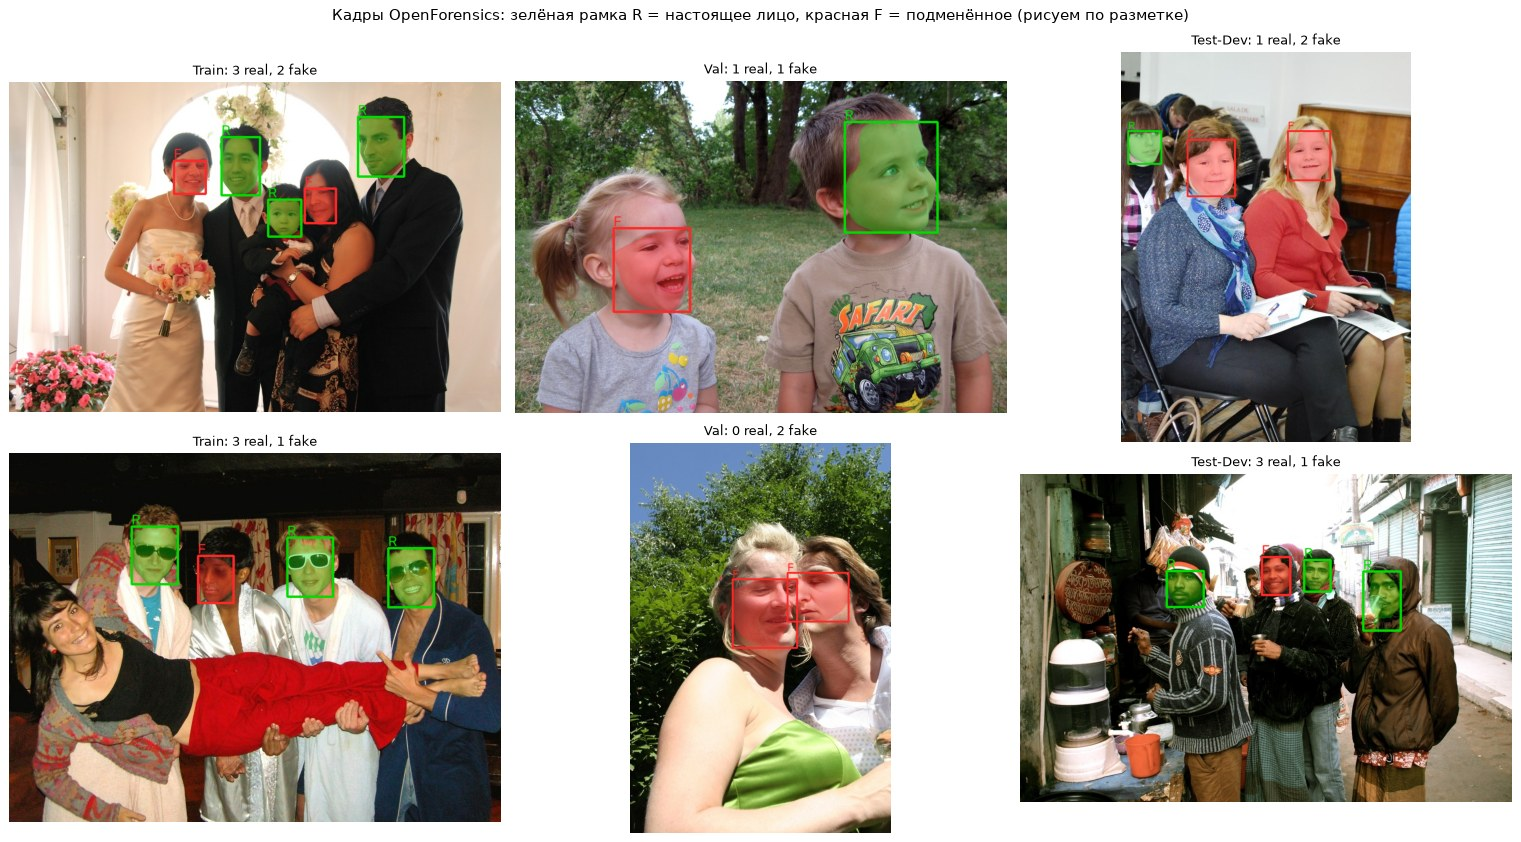

In [2]:
# По два случайных кадра из каждого сплита: так выглядят данные (рамки и маски нарисованы по разметке)
pick = pd.concat([frames[frames["split"] == s].pipe(sample_rows, 2, random_state=SEED + k) for k, s in enumerate(SPLITS)])
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for ax, (_, fr) in zip(axes.T.ravel(), pick.iterrows()):
    g = faces_by_frame[(fr["split"], fr["image_id"])]
    ax.imshow(draw_faces(frame_img(fr["split"], fr["image_id"]), g)); ax.axis("off")
    ax.set_title(f"{fr['split']}: {(g['label'] == 'real').sum()} real, {(g['label'] == 'fake').sum()} fake", fontsize=10)
fig.suptitle("Кадры OpenForensics: зелёная рамка R = настоящее лицо, красная F = подменённое (рисуем по разметке)", fontsize=12)
plt.tight_layout(); plt.show()

## 1.2 Как сделаны фейки

По статье OpenForensics конвейер такой: (1) на фото находят лица и ставят на каждом 68 опорных точек
(брови, глаза, нос, рот, овал); (2) проверяют, «годится» ли лицо для подмены: достаточно крупное, чёткое,
качественное, плюс случайный выбор; (3) нейросеть кодирует лицо в вектор чисел, вектор случайно
меняют, и генератор (GAN) рисует **новое лицо несуществующего человека** 512×512 в тех же условиях;
(4) детектор XceptionNet проверяет результат: если он распознал подделку, лицо выбрасывают и рисуют
заново; (5) новое лицо возвращают в исходную позу, подгоняют по цвету и вклеивают по маске так, чтобы
шов был незаметен (пуассоновское смешивание).

Что из этого важно для анализа:
- **все фейки сделаны одним методом** 2021 года, поэтому перенос на незнакомые генераторы внутри
  датасета проверить нельзя, только на других наборах;
- **подменяли только «пригодные» лица** (крупные и чёткие), значит, размер и резкость real и fake могут
  различаться по построению: это кандидаты в шорткаты;
- **в датасете только фейки, обманувшие XceptionNet**: на простых Xception-подобных моделях этот
  датасет искусственно труднее.

## 1.3 Состав по сплитам

Одна таблица со всем, что нужно знать о размере данных. **Доля real** дана с 95% доверительным
интервалом Уилсона (стандартный интервал для доли).

In [3]:
fpf = frames.groupby("split")["n_faces"]
tab = pd.DataFrame({
    "кадров": frames.groupby("split").size(),
    "лиц": faces.groupby("split").size(),
    "real": faces[faces["label"] == "real"].groupby("split").size(),
    "fake": faces[faces["label"] == "fake"].groupby("split").size(),
    "лиц на кадр: среднее": fpf.mean(), "медиана": fpf.median(), "макс": fpf.max(),
    "ГБ кадров": [sum(p.stat().st_size for p in (IMAGES / s).glob("*.jpg")) / 1e9 for s in sorted(SPLITS)],
    "МБ разметки": [(ANNOT / f"{s}_poly.json").stat().st_size / 1e6 for s in sorted(SPLITS)],
}).loc[SPLITS]
lo, hi = proportion_confint(tab["real"], tab["лиц"], method="wilson")
tab.insert(4, "доля real [95% ДИ]", [f"{r / n:.1%} [{a:.1%}; {b:.1%}]" for r, n, a, b in zip(tab["real"], tab["лиц"], lo, hi)])
tab.insert(5, "fake : real", tab["fake"] / tab["real"])
tab.loc["Всего"] = [len(frames), len(faces), (faces["label"] == "real").sum(), (faces["label"] == "fake").sum(),
                    f"{(faces['label'] == 'real').mean():.1%}", (faces["label"] == "fake").sum() / (faces["label"] == "real").sum(),
                    frames["n_faces"].mean(), frames["n_faces"].median(), frames["n_faces"].max(),
                    tab["ГБ кадров"].sum(), tab["МБ разметки"].sum()]
display(tab.style.format({"кадров": "{:,.0f}", "лиц": "{:,.0f}", "real": "{:,.0f}", "fake": "{:,.0f}", "fake : real": "{:.2f}",
                          "лиц на кадр: среднее": "{:.2f}", "медиана": "{:.0f}", "макс": "{:.0f}", "ГБ кадров": "{:.1f}", "МБ разметки": "{:.0f}"}))

# Одинакова ли доля real в сплитах? Хи-квадрат однородности и V Крамера (сила связи «сплит - метка», 0..1)
ct = pd.crosstab(faces["split"], faces["label"])
chi2, p, dof, _ = chi2_contingency(ct)
print(f"Хи-квадрат = {chi2:,.0f}, p = {p:.1e}; V Крамера = {np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))):.3f}")

,кадров,лиц,real,fake,доля real [95% ДИ],fake : real,лиц на кадр: среднее,медиана,макс,ГБ кадров,МБ разметки
split,,,,,,,,,,,
Train,"44,097","150,866","85,006","65,860",56.3% [56.1%; 56.6%],0.77,3.42,2,45,20.3,531
Val,"7,308","15,345","4,782","10,563",31.2% [30.4%; 31.9%],2.21,2.10,2,14,3.2,122
Test-Dev,"18,895","49,718","21,048","28,670",42.3% [41.9%; 42.8%],1.36,2.63,2,9,8.3,313
Всего,"70,300","215,929","110,836","105,093",51.3%,0.95,3.07,2,45,31.8,967


Хи-квадрат = 5,627, p = 0.0e+00; V Крамера = 0.161


**Как устроена разметка.** JSON в стандартном формате COCO: список кадров (`images`) и список лиц
(`annotations`). Одна запись лица выглядит так:

In [4]:
with open(ANNOT / "Val_poly.json") as f:
    coco_val = json.load(f)
ann = dict(coco_val["annotations"][0])
ann["segmentation"] = [poly[:10] + ["..."] for poly in ann["segmentation"]]
print("кадр:", coco_val["images"][0])
print("лицо:", json.dumps(ann, ensure_ascii=False))
del coco_val

кадр: {'id': 0, 'file_name': 'Images/Val/0793f07ea0.jpg', 'width': 1024, 'height': 681}
лицо: {"id": 0, "image_id": 0, "iscrowd": 0, "area": 16812, "category_id": 1, "bbox": [192, 236, 162, 133], "segmentation": [[237, 236, 232, 237, 226, 238, 218, 242, 216, 244, "..."]]}


| Поле | Что означает |
| --- | --- |
| `image_id` | на каком кадре лицо (номер внутри сплита) |
| `category_id` | **метка**: 0 = real, 1 = fake |
| `bbox` | рамка лица [x, y, ширина, высота] в пикселях |
| `segmentation` | контур лица (маска) как многоугольник [x1, y1, x2, y2, ...]; у fake это область, которую нарисовал генератор |
| `area` | площадь маски в пикселях |

Ключи уникальны, каждое лицо ссылается на существующий кадр, метки только 0 и 1 (проверки в приложении A4).

## 1.4 Что известно о данных до анализа

Ниже факты из статьи и из технических проверок (приложение) и то, что из них следует.

| Факт | Источник | Следствие для анализа |
| --- | --- | --- |
| Фото из Open Images, 45 473 исходных фото после фильтрации | статья | исходных фото меньше, чем кадров: одно фото использовано несколько раз (проверяем в шаге 2) |
| Почти все кадры уменьшены до 1024 px по длинной стороне (99,0–99,3%) | приложение A1 | размер кадра одинаков, **шорткатом быть не может** |
| Все файлы JPEG качества 100 со стандартными таблицами, EXIF нет ни у одного | приложение A1 | сжатие файла и метаданные **не отличают** real от fake |
| Геометрия разметки чистая: рамки в кадре, маски внутри рамок | приложение A2 | можно доверять размерам лиц из JSON |
| В JSON на 0,3% лиц меньше, чем в таблице статьи; 288 кадров Train лежат в архиве без разметки | приложение A3 | используем JSON; 288 кадров без меток исключаем |
| Сплит по статье «случайный 60:10:30» | статья | проверяем ниже: доли классов в сплитах разные |

Отдельно: Kaggle-версию этого датасета я проверял раньше: там 27% дублей и 604 группы, где одна и та
же картинка помечена и real, и fake. Поэтому в оригинале дубли проверяем в первую очередь (шаг 2).

## 1.5 Описательная статистика и баланс real / fake

**Что делаем.** Строим одну сводную таблицу по сплитам и классам, как это принято в эконометрике
(«Table 1»), и проверяем **баланс**: различаются ли real и fake по признакам, которые к подделке
отношения не имеют (размер лица, его положение в кадре, число лиц на фото).

**Мера дисбаланса: SMD** (standardized mean difference) = (среднее у fake − среднее у real) ÷ общее
стандартное отклонение. Это разница средних «в сигмах»: 0 = группы одинаковы, |SMD| > 0,1 принято
считать заметным дисбалансом (Austin, 2009). Скошенные величины (размеры) берём в логарифме.

**Почему здесь.** Если real и fake различаются уже по геометрии из разметки, это первый кандидат в
шорткат, и дальше все сравнения нужно делать с поправкой на него.

In [5]:
faces["log_face_side"] = np.log10(faces["face_side_px"])
faces["log_bbox_frac"] = np.log10(faces["bbox_frac"])
faces["cx"] = (faces["x"] + faces["w"] / 2) / faces["width"]
faces["cy"] = (faces["y"] + faces["h"] / 2) / faces["height"]
faces["in_mixed"] = faces["frame_type"] == "mixed"
faces["tiny"] = faces["face_side_px"] < 32

def smd(g, col):
    a, b = g.loc[g["label"] == "fake", col], g.loc[g["label"] == "real", col]
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

covs = {"сторона лица, px (лог)": "log_face_side", "доля кадра под лицом (лог)": "log_bbox_frac",
        "лиц на кадре": "n_faces_in_frame", "центр лица по x": "cx", "центр лица по y": "cy",
        "лицо из смешанного кадра": "in_mixed", "лицо < 32 px": "tiny"}
rows = []
for s in SPLITS:
    g = faces[faces["split"] == s]
    for name, col in covs.items():
        r = g[g["label"] == "real"][col].astype(float); f = g[g["label"] == "fake"][col].astype(float)
        rows.append({"сплит": s, "признак": name, "real: среднее": r.mean(), "real: σ": r.std(),
                     "fake: среднее": f.mean(), "fake: σ": f.std(), "SMD": smd(g.assign(**{col: g[col].astype(float)}), col)})
table1 = pd.DataFrame(rows)
med = faces.groupby(["split", "label"])["face_side_px"].median().unstack().loc[SPLITS]
display(table1.set_index(["сплит", "признак"]).style.format(precision=3).format({"SMD": "{:+.2f}"})
        .map(lambda v: "background-color: #fde0c5" if isinstance(v, float) and abs(v) > 0.1 else "", subset=["SMD"]))
print("Медиана стороны лица, px (real / fake):", {s: f"{med.loc[s, 'real']:.0f} / {med.loc[s, 'fake']:.0f}" for s in SPLITS})

Медиана стороны лица, px (real / fake): {'Train': '73 / 85', 'Val': '191 / 192', 'Test-Dev': '128 / 156'}


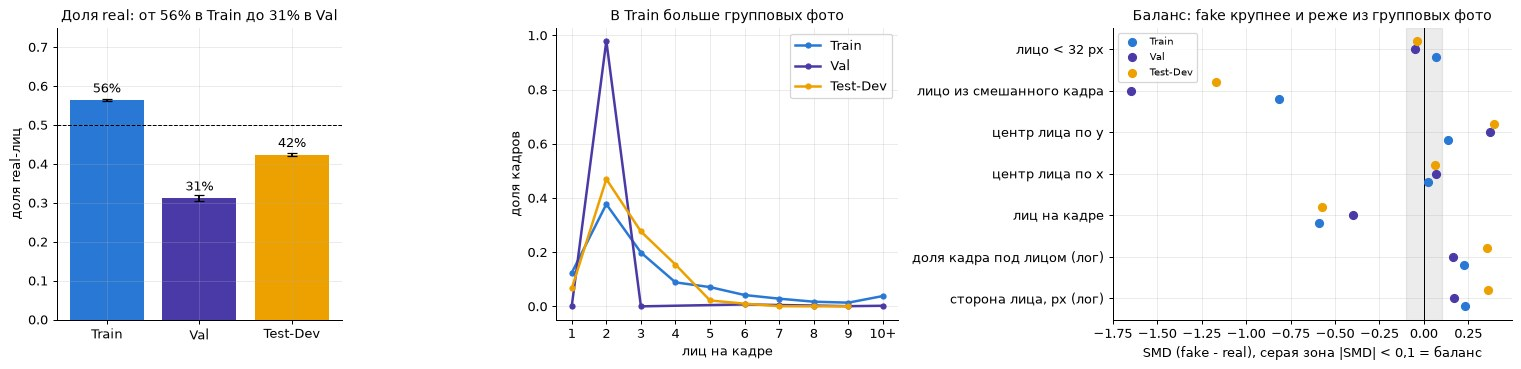

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1.2, 1.4]})
# (а) доля real с 95% ДИ
share = tab.loc[SPLITS, "real"] / tab.loc[SPLITS, "лиц"]
lo, hi = proportion_confint(tab.loc[SPLITS, "real"], tab.loc[SPLITS, "лиц"], method="wilson")
axes[0].bar(SPLITS, share, color=[SPLIT_COLOR[s] for s in SPLITS], yerr=[share - lo, hi - share], capsize=4)
axes[0].axhline(0.5, color="k", ls="--", lw=0.8)
for i, v in enumerate(share):
    axes[0].text(i, v + 0.02, f"{v:.0%}", ha="center")
axes[0].set_ylim(0, 0.75); axes[0].set_ylabel("доля real-лиц"); axes[0].set_title("Доля real: от 56% в Train до 31% в Val")
# (б) число лиц на кадре
for s in SPLITS:
    v = frames.loc[frames["split"] == s, "n_faces"].clip(upper=10).value_counts(normalize=True).sort_index()
    axes[1].plot(v.index, v.values, marker="o", ms=4, lw=2, color=SPLIT_COLOR[s], label=s)
axes[1].set_xticks(range(1, 11), [str(i) for i in range(1, 10)] + ["10+"])
axes[1].set_xlabel("лиц на кадре"); axes[1].set_ylabel("доля кадров"); axes[1].legend()
axes[1].set_title("В Train больше групповых фото")
# (в) график баланса (love plot): SMD каждого признака в каждом сплите
names = list(covs)
for k, s in enumerate(SPLITS):
    v = table1[table1["сплит"] == s].set_index("признак").loc[names, "SMD"]
    axes[2].scatter(v.values, np.arange(len(names)) + (k - 1) * 0.2, color=SPLIT_COLOR[s], s=40, label=s, zorder=3)
axes[2].axvspan(-0.1, 0.1, color="gray", alpha=0.15); axes[2].axvline(0, color="k", lw=0.8)
axes[2].set_yticks(range(len(names)), names); axes[2].set_xlabel("SMD (fake - real), серая зона |SMD| < 0,1 = баланс")
axes[2].legend(fontsize=8); axes[2].set_title("Баланс: fake крупнее и реже из групповых фото")
plt.tight_layout(); plt.show()

*Как читать. Таблица: средние признаков у real и fake и SMD (разница средних в стандартных отклонениях; больше 0,1 по модулю подсвечено = классы заметно различаются). Графики: доля real в каждом сплите с интервалом; сколько лиц на фото; SMD каждого признака (точки вне серой зоны = дисбаланс).*

**Что видим.**

- **Доля real в сплитах разная**: 56,3% в Train, 31,2% в Val, 42,3% в Test-Dev; интервалы не
  пересекаются, связь «сплит ↔ метка» умеренная (V Крамера 0,16). **98% кадров Val содержат ровно 2
  размеченных лица** (в Train 38%, в Test-Dev 47%). При «случайном» делении одной выборки так не бывает:
  сплиты различаются по составу.
- **Баланс real/fake нарушен по контексту, а не только по размеру.** Самые большие |SMD|: «лицо из
  смешанного кадра» (−0,82 / −1,65 / −1,17) и «лиц на кадре» (−0,59 / −0,40 / −0,57): real-лица живут
  в групповых фото, fake часто приходят из кадров с 1–2 лицами. Сторона лица: fake крупнее
  (SMD +0,23 / +0,17 / +0,36; медиана в Train 85 против 73 px). Fake ниже в кадре (SMD по y до +0,39).
  Положение по горизонтали и доля лиц < 32 px сбалансированы (|SMD| < 0,1).

**Что это значит.** Модель может отличать классы по тому, *сколько людей вокруг лица* и *насколько
лицо крупное*, не глядя на подделку. Это два главных кандидата в шорткат по разметке.

**Решение.** Основная метрика ROC-AUC (не зависит от доли классов), порог калибруем на отложенной части
Train, Val используем как «тест сдвига». Сравнения real/fake дальше делаем и в целом, и внутри
смешанных кадров. Число лиц на кадре и размер лица войдут в шорткат-тест (следующий шаг плана).

---
# 2. Дубли и утечки между сплитами

**Зачем.** Если одно и то же фото есть и в Train, и в Test-Dev, модель его «помнит», и качество на тесте
завышено (утечка). Дубли внутри Train тоже опасны: при кросс-валидации копия попадёт и в обучение, и в
проверку. В Kaggle-версии датасета дублей было 27%, поэтому в оригинале это главный открытый вопрос.

**Как ищем.** Сравнить попиксельно все 2,5 млрд пар кадров долго, поэтому в два этапа:
1. **Кандидаты по dHash.** dHash: 64-битный «отпечаток» картинки: кадр уменьшаем до 9×8 пикселей и для
   каждого пикселя записываем, ярче ли он соседа справа. У похожих картинок похожие отпечатки.
   Похожесть меряем **расстоянием Хэмминга**: числом различающихся битов из 64 (0 = совпадают).
2. **Проверка пикселями.** Для каждой пары-кандидата считаем **MAE**: среднюю абсолютную разницу
   яркости пикселей миниатюр 64×64 (шкала 0…255; < 2 = на глаз неотличимы). Считаем её **только по
   фону** (вне рамок лиц обоих кадров): если два кадра сделаны из одного фото, но лица подменены
   по-разному, фон у них совпадёт, а лица нет.

In [ ]:
t0 = time.time()
cand = close_pairs(frames["dhash"].to_numpy(np.uint64), max_dist=10)       # мягкий порог: хэш только отбирает
boxes_by_row = [faces_by_frame[k][["x", "y", "w", "h"]].to_numpy(float).tolist() for k in zip(frames["split"], frames["image_id"])]
cand = pixel_check(cand, thumbs, boxes_by_row, list(zip(frames["width"], frames["height"])))
cand["cross_split"] = frames["split"].to_numpy()[cand["i"]] != frames["split"].to_numpy()[cand["j"]]
print(f"Пар-кандидатов (Хэмминг <= 10): {len(cand):,} за {time.time() - t0:.0f} c")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
bins = np.logspace(-4, 2.3, 80)
for cross, name, col in [(False, "внутри сплита", "#2a78d6"), (True, "между сплитами", "#eb6834")]:
    v = cand.loc[cand["cross_split"] == cross, "mae_bg"].dropna().clip(lower=1e-4)
    axes[0].hist(v, bins=bins, density=True, color=col, alpha=0.6, label=f"{name} ({len(v):,} пар)")
axes[0].axvline(2, color="k", ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].legend()
axes[0].set_xlabel("MAE фона (0..255, лог)"); axes[0].set_ylabel("плотность пар (лог)")
axes[0].set_title("Два горба: «фон тот же» (MAE около 0) и «разные фото»")
dup_share = cand.groupby("hamming")["mae_bg"].apply(lambda s: (s < 2).mean())
axes[1].bar(dup_share.index, dup_share.values, color="#2a78d6")
axes[1].set_xlabel("расстояние Хэмминга dHash, бит"); axes[1].set_ylabel("доля пар-дублей (MAE фона < 2)")
axes[1].set_title("Порог «Хэмминг <= 4» неточен: дубли есть и при 5-7")
plt.tight_layout(); plt.show()

Пар-кандидатов (Хэмминг <= 10): 46,810 за 18 c


График обновится при запуске EDA на исходниках: прежние таблицы измерений не сохранились. Код использует нормированную плотность или долю наблюдений.

*Как читать. Слева: насколько отличается фон у пар-кандидатов (левее = одинаковее; пунктир = порог «копия»). Справа: какая доля кандидатов оказалась копиями при разной похожести отпечатков.*

**Что видим.**

- Кандидатов 46 810 пар. MAE фона распадается на **два горба**: копии (MAE 10⁻⁴…10⁻², фон совпадает
  до шума округления) и разные фото (MAE 10…200). Между 0,1 и 2 почти пусто, поэтому порог 2 выбран по
  провалу распределения.
- Доля копий среди кандидатов: при Хэмминге 0–3 почти 100%, при 4 около 70%, при 5 около 30%, дальше
  почти ноль. Фиксированный порог по хэшу ошибался бы в обе стороны, пиксельная проверка обязательна.
- **Ни одна пара из разных сплитов не имеет MAE фона < 2.**

## 2.1 Копии одного фото: как выглядят и сколько их

Пары с MAE фона < 2 объявляем копиями и собираем в группы (если A копия B, а B копия C, это одна
группа). Номер группы `source_id` это наша оценка «исходного фото Open Images».

Пар-копий: 25,021, из них между сплитами: 0
Исходных фото: 45,281 (в статье: 45 473); кадров на одно фото: 1.55
Доля кадров, у которых есть копия: {'Train': '69.8%', 'Val': '74.6%', 'Test-Dev': '73.1%'}


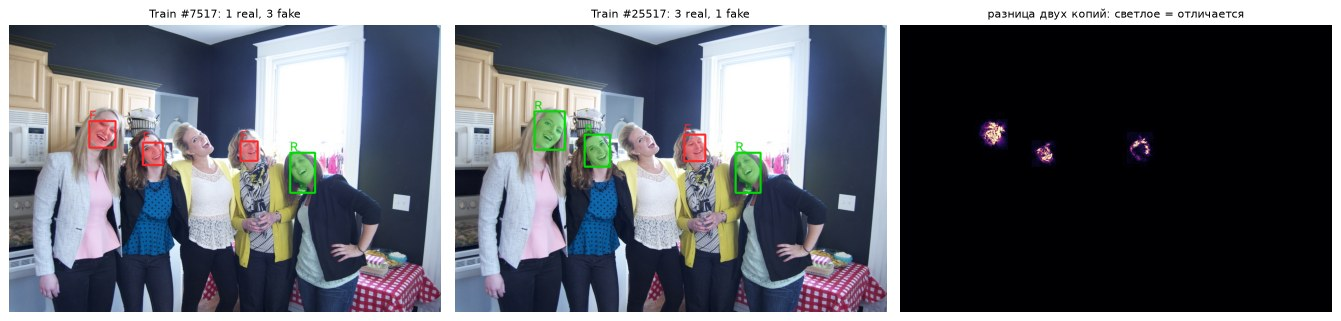

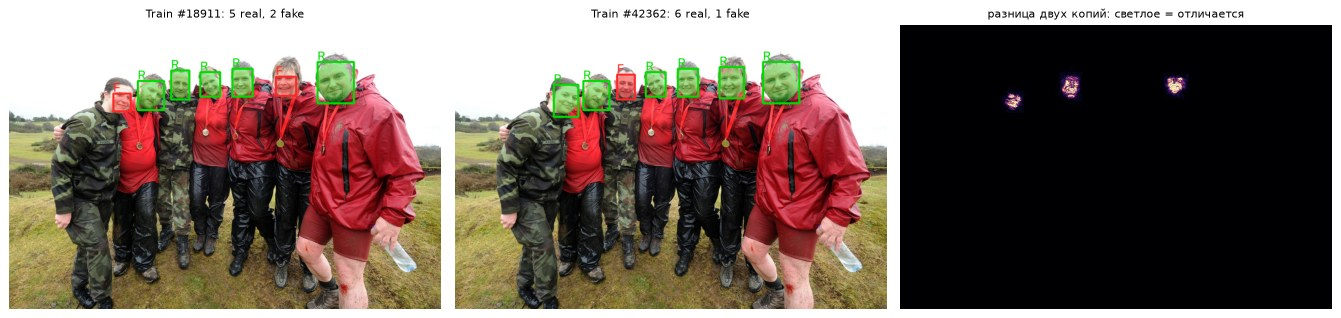

In [8]:
dups = cand[cand["mae_bg"] < 2]
frames["source_id"] = groups_from_pairs(len(frames), dups)
frames["group_size"] = frames.groupby("source_id")["split"].transform("size")
n_src = frames["source_id"].nunique()
print(f"Пар-копий: {len(dups):,}, из них между сплитами: {int(dups['cross_split'].sum())}")
print(f"Исходных фото: {n_src:,} (в статье: 45 473); кадров на одно фото: {len(frames) / n_src:.2f}")
print("Доля кадров, у которых есть копия:", frames.groupby("split")["group_size"].apply(lambda s: f"{(s > 1).mean():.1%}").loc[SPLITS].to_dict())

def show_group(src):
    rows = frames[frames["source_id"] == src].head(2)
    imgs = [frame_img(r["split"], r["image_id"]) for _, r in rows.iterrows()]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, img, (_, fr) in zip(axes, imgs, rows.iterrows()):
        g = faces_by_frame[(fr["split"], fr["image_id"])]
        ax.imshow(draw_faces(img, g)); ax.axis("off")
        ax.set_title(f"{fr['split']} #{fr['image_id']}: {(g['label'] == 'real').sum()} real, {(g['label'] == 'fake').sum()} fake", fontsize=9)
    axes[2].imshow(np.clip(np.abs(imgs[0].astype(int) - imgs[1].astype(int)).sum(axis=2), 0, 60), cmap="magma")
    axes[2].set_title("разница двух копий: светлое = отличается", fontsize=9); axes[2].axis("off")
    plt.tight_layout(); plt.show()

for src in frames.loc[(frames["group_size"] == 2) & (frames["split"] == "Train"), "source_id"].drop_duplicates().pipe(sample_rows, 2, random_state=SEED):
    show_group(src)

*Как читать. Числа: сколько найдено копий и исходных фото. Картинки: две копии одного фото и карта их разницы (светлое = отличается).*

**Что видим.**

- 25 021 пара копий, **все внутри сплитов, между сплитами 0**.
- **Исходных фото 45 281**, в статье написано 45 473: совпадение с точностью 0,4%.
- Копия есть у 70–75% кадров; почти все группы из двух кадров.
- На картинках две копии совпадают пиксель в пиксель везде, кроме лиц: в одной копии лицо оставили
  настоящим, в другой заменили (или заменили по-разному).

**Что это значит.** Так устроен весь датасет: примерно 45 тыс. исходных фото, и большинство
использовано **дважды** с разными случайными подменами (1,55 кадра на фото). Авторы держали обе копии
в одном сплите, поэтому тест честный. Но внутри Train у 70% кадров есть «близнец»: если делить Train
на фолды по кадрам, копия окажется и в обучении, и в проверке.

**Решение.** Официальные сплиты оставляем. Любую кросс-валидацию и отложенную часть Train делим по
`source_id` (исходному фото), а не по кадру.

## 2.2 Утечки между сплитами: та же сцена и тот же человек

Точных копий между сплитами нет, но остаются два более тонких вида утечки. Фото в Open Images часто
идут **сериями**: несколько снимков одного селфи подряд или десятки фото одного мероприятия
(банкет, вручение наград, пресс-волл). Соседние снимки серии это разные файлы, но на них те же люди.

- **Та же сцена:** почти тот же кадр, камера чуть сдвинулась. Ищем среди пар кадров с MAE фона от 2 до 8
  (выше порога копий, но намного ниже «разных фото»).
- **Тот же человек на другом снимке события:** целые кадры разные, но кроп лица почти тот же. Ищем,
  сравнивая dHash **кропов лиц** между сплитами и проверяя кандидатов по MAE миниатюр 32×32.

In [9]:
# Уровень 1: та же сцена (кадры)
scene_pairs = cand[(cand["mae_bg"] < 8) & (cand["hamming"] <= 5)]
frames["scene_id"] = groups_from_pairs(len(frames), scene_pairs)
frames["scene_n_splits"] = frames.groupby("scene_id")["split"].transform("nunique")

# Уровень 2: тот же человек (кропы лиц): Train против Val + Test-Dev, Val против Test-Dev
fh = faces["face_dhash"].to_numpy(np.uint64)
def cross_face_pairs(split_a, splits_b, max_dist=6, chunk=500):
    ia, ib = np.where(faces["split"] == split_a)[0], np.where(faces["split"].isin(splits_b))[0]
    out = []
    for s in range(0, len(ia), chunk):
        d = bitwise_count(fh[ia[s:s + chunk], None] ^ fh[None, ib])
        r, c = np.nonzero(d <= max_dist)
        out.append(pd.DataFrame({"a": ia[s + r], "b": ib[c]}))
    return pd.concat(out, ignore_index=True)
xf = pd.concat([cross_face_pairs("Train", ["Val", "Test-Dev"]), cross_face_pairs("Val", ["Test-Dev"])], ignore_index=True)
xf["mae_crop"] = np.abs(face_thumbs[xf["a"]].astype(np.int16) - face_thumbs[xf["b"]].astype(np.int16)).mean(axis=(1, 2))
print("MAE кропов у кандидатов-лиц из разных сплитов:")
print(pd.cut(xf["mae_crop"], [0, 6, 8, 10, 12, 15, 20, 255]).value_counts().sort_index().to_string())

same_person = xf[xf["mae_crop"] < 10]
faces["leak_person"] = faces.index.isin(np.r_[same_person["a"], same_person["b"]])
leak_frames = faces.loc[faces["leak_person"], ["split", "image_id"]].drop_duplicates()
frames["leak_person"] = pd.MultiIndex.from_frame(frames[["split", "image_id"]]).isin(pd.MultiIndex.from_frame(leak_frames))
frames["leak_any"] = (frames["scene_n_splits"] > 1) | frames["leak_person"]
summary = pd.DataFrame({
    "кадров со сценой в другом сплите": frames.groupby("split")["scene_n_splits"].apply(lambda s: (s > 1).sum()),
    "кадров с тем же человеком в другом сплите": frames.groupby("split")["leak_person"].sum(),
    "кадров с любой утечкой": frames.groupby("split")["leak_any"].sum(),
    "кадров всего": frames.groupby("split").size()}).loc[SPLITS].astype(int)
summary["доля кадров с утечкой"] = summary["кадров с любой утечкой"] / summary["кадров всего"]
summary.style.format({"доля кадров с утечкой": "{:.2%}"})

MAE кропов у кандидатов-лиц из разных сплитов:
mae_crop
(0, 6]            3
(6, 8]           25
(8, 10]          19
(10, 12]         26
(12, 15]        109
(15, 20]       1079
(20, 255]    103405


,кадров со сценой в другом сплите,кадров с тем же человеком в другом сплите,кадров с любой утечкой,кадров всего,доля кадров с утечкой
split,,,,,
Train,5,23,27,44097,0.06%
Val,5,5,9,7308,0.12%
Test-Dev,5,20,23,18895,0.12%


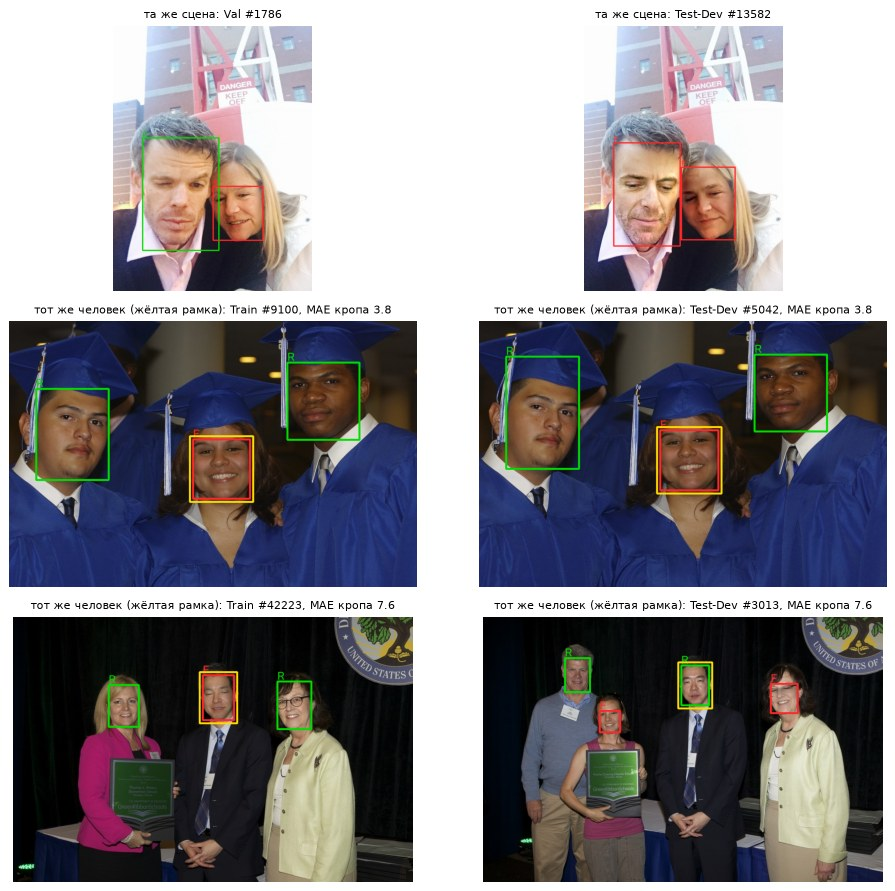

In [10]:
# Примеры: верхний ряд - та же сцена (серия снимков), нижние - тот же человек на другом снимке события
ex_scene = cand[(cand["cross_split"]) & (cand["mae_bg"].between(2, 8))].sort_values("mae_bg").head(1)
ex_person = same_person.sort_values("mae_crop").iloc[[0, len(same_person) // 2]]
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for k, (_, pr) in enumerate(ex_scene.iterrows()):
    for ax, idx in zip(axes[0], [pr["i"], pr["j"]]):
        fr = frames.iloc[int(idx)]
        ax.imshow(draw_faces(frame_img(fr["split"], fr["image_id"]), faces_by_frame[(fr["split"], fr["image_id"])], masks=False))
        ax.set_title(f"та же сцена: {fr['split']} #{fr['image_id']}", fontsize=9); ax.axis("off")
for row_axes, (_, pr) in zip(axes[1:], ex_person.iterrows()):
    for ax, idx in zip(row_axes, [pr["a"], pr["b"]]):
        r = faces.iloc[int(idx)]
        vis = draw_faces(frame_img(r["split"], r["image_id"]), faces_by_frame[(r["split"], r["image_id"])], masks=False)
        t = max(3, int(max(vis.shape[:2]) / 250))
        cv2.rectangle(vis, (int(r["x"]) - 2 * t, int(r["y"]) - 2 * t), (int(r["x"] + r["w"]) + 2 * t, int(r["y"] + r["h"]) + 2 * t), (255, 220, 0), t)
        ax.imshow(vis); ax.axis("off")
        ax.set_title(f"тот же человек (жёлтая рамка): {r['split']} #{r['image_id']}, MAE кропа {pr['mae_crop']:.1f}", fontsize=9)
plt.tight_layout(); plt.show()

*Как читать. Список: насколько похожи кропы лиц-кандидатов из разных сплитов (меньше = похожее). Таблица: сколько фото в каждом сплите имеют «ту же сцену» или «того же человека» в другом сплите. Картинки: примеры.*

**Что видим.**

- **Та же сцена** (серийные снимки, MAE фона 2–8): по 5 кадров в каждом сплите. На примере это селфи,
  снятое серией: два кадра попали в Val и Test-Dev.
- **Тот же человек на другом снимке события**: у пар лиц из разных сплитов MAE кропов распадается
  так же: ниже 10 это один и тот же человек (47 пар), от 12 уже разные люди. На примерах это выпускной
  и вручение награды: соседние фото одной серии попали в Train и Test-Dev.
- Всего кадров с утечкой: Train 27 (0,06%), Val 9 (0,12%), Test-Dev 23 (0,12%).

**Что это значит.** Утечка есть, но это утечка **личности** (те же люди с соседнего снимка), а не
картинки, и она в 4–8 раз ниже порога 0,5%, при котором стоило бы перестраивать сплиты. Это нижняя
оценка: dHash кропа находит человека только в почти той же позе.

**Решение.** Сплиты не меняем. Флаг `leak_any` сохраняем (эти кадры можно исключить из
теста). Поиск того же человека в другой позе сделаем по описаниям лиц из нейросети (следующие шаги плана).

## 2.3 Одно лицо в двух копиях фото

В двух копиях одного фото на одном и том же месте кадра стоит одно и то же лицо. Его метка в копиях
может совпадать или различаться, и это даёт три случая:

| Случай | Что произошло | Чем это полезно или опасно |
| --- | --- | --- |
| real в обеих копиях | лицо не трогали ни разу: **одинаковые пиксели** попали в датасет дважды | настоящих лиц «по факту» меньше, чем строк в таблице |
| real в одной, fake в другой | в одной копии лицо оставили, в другой заменили | готовая пара «оригинал → подделка» с одинаковым фоном и светом |
| fake в обеих копиях | одно исходное лицо заменили дважды разными «людьми» | две разные подделки одного места |

Лица копий сопоставляем по совпадению рамок (IoU ≥ 0,5: площадь пересечения ÷ площадь объединения).

In [11]:
faces = faces.merge(frames[["split", "image_id", "source_id", "group_size", "scene_id", "scene_n_splits"]], on=["split", "image_id"])
parent = np.arange(len(faces))   # объединяем совпавшие лица в группы «одно исходное лицо»
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
pairs = []
for _, g in faces[faces["group_size"] > 1].groupby("source_id"):
    idx, b, img = g.index.to_numpy(), g[["x", "y", "w", "h"]].to_numpy(float), list(zip(g["split"], g["image_id"]))
    for a in range(len(idx)):
        for c in range(a + 1, len(idx)):
            if img[a] != img[c] and iou(b[a], b[c]) >= 0.5:
                pairs.append((idx[a], idx[c])); parent[find(idx[a])] = find(idx[c])
faces["face_src_id"] = [find(i) for i in range(len(faces))]
fp = pd.DataFrame(pairs, columns=["a", "b"])
fp["случай"] = [" + ".join(sorted([faces.at[a, "label"], faces.at[b, "label"]])) for a, b in zip(fp["a"], fp["b"])]
fp["MAE кропов"] = np.abs(face_thumbs[fp["a"]].astype(np.int16) - face_thumbs[fp["b"]].astype(np.int16)).mean(axis=(1, 2))
display(fp.groupby("случай").agg(пар=("a", "size"), медиана_MAE=("MAE кропов", "median")).style.format({"медиана_MAE": "{:.1f}"}))
n_real_rows = (faces["label"] == "real").sum()
n_real_unique = faces.loc[faces["label"] == "real", "face_src_id"].nunique()
print(f"Строк real: {n_real_rows:,}; уникальных настоящих лиц: {n_real_unique:,} ({n_real_unique / n_real_rows:.0%})")

,пар,медиана_MAE
случай,,
fake + fake,27704,38.0
fake + real,16705,22.5
real + real,29827,0.0


Строк real: 110,836; уникальных настоящих лиц: 81,022 (73%)


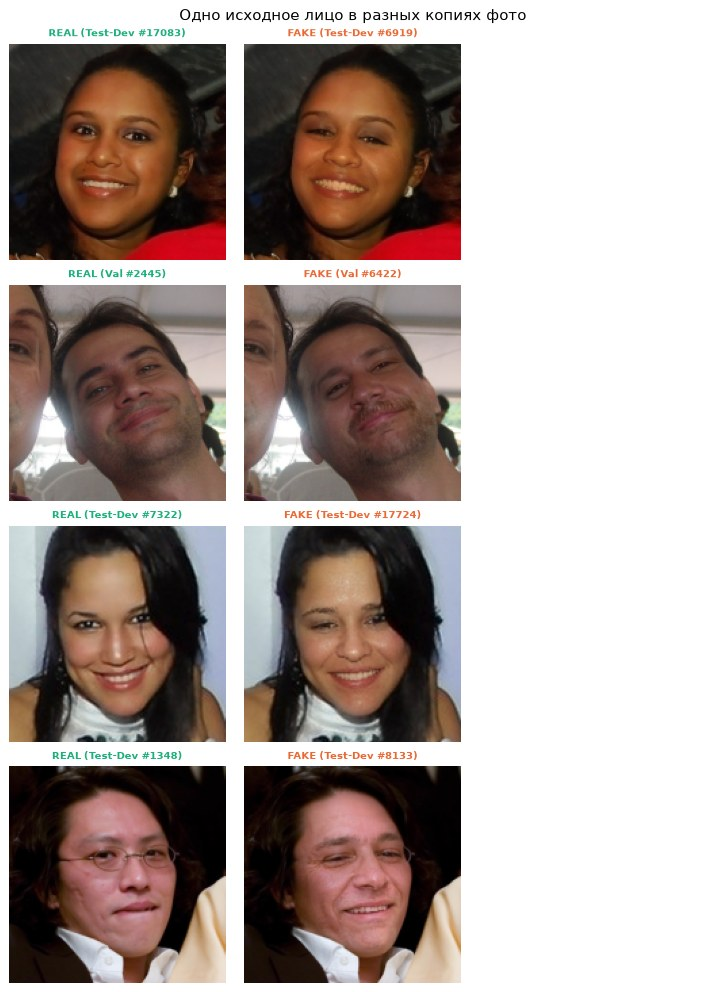

In [12]:
# Галерея: в каждом ряду одно исходное лицо во всех копиях фото
labels_of = faces.groupby("face_src_id")["label"].agg(set)
mixed_src = labels_of[labels_of.apply(lambda v: v == {"real", "fake"})].index
pick = faces[faces["face_src_id"].isin(mixed_src) & (faces["face_side_px"] >= 80)]["face_src_id"].drop_duplicates().pipe(sample_rows, 4, random_state=SEED)
fig, axes = plt.subplots(len(pick), 3, figsize=(8, 2.8 * len(pick)))
for row_axes, src in zip(axes, pick):
    g = faces[faces["face_src_id"] == src].sort_values("category_id").head(3)
    box = tuple(g.iloc[0][["x", "y", "w", "h"]])     # одна рамка на все копии, чтобы кропы совпадали
    for ax in row_axes:
        ax.axis("off")
    for ax, (_, r) in zip(row_axes, g.iterrows()):
        ax.imshow(crop_of(r, box=box))
        ax.set_title(f"{r['label'].upper()} ({r['split']} #{r['image_id']})", fontsize=8, color=PLOT_COLOR[r["label"]], fontweight="bold")
fig.suptitle("Одно исходное лицо в разных копиях фото")
plt.tight_layout(); plt.show()

*Как читать. Таблица: сколько пар «одно лицо в двух копиях фото» каждого вида и насколько различаются их кропы (0 = пиксель в пиксель). Галерея: одно лицо в разных копиях.*

**Что видим.**

- **real + real: 29 827 пар с MAE 0,0**: одинаковые настоящие лица попали в датасет дважды пиксель в
  пиксель. Из 110 836 строк real уникальных настоящих лиц 81 022 (73%).
- **real + fake: 16 705 пар**: в одной копии лицо настоящее, в другой подменено.
- **fake + fake: 27 704 пары**: одно лицо подменено дважды разными «людьми».
- На галерее подмена сохраняет позу, причёску, свет и фон, но меняет черты лица.

**Что это значит.** (1) Каждое четвёртое real-лицо в таблице повторяет другое. При случайном делении
по кадрам одно и то же настоящее лицо попадёт и в обучение, и в проверку, это прямая утечка.
(2) 16,7 тыс. пар «оригинал → подделка» с идентичным фоном. Это лучший материал, чтобы понять, что
именно меняет генератор (используем в 3.4, 4.2 и 7.5).

**Решение.** Группировать по `source_id` (решение из 2.1 закрывает и эту утечку). Пары сохраняем
через `face_src_id` для парного анализа (3.4, 7.5, 8.1).

## Итог шага 2

| Проверка | Нашли | Решение |
| --- | --- | --- |
| Копии одного фото | 45 281 исходное фото, у 70% кадров есть копия; **между сплитами копий нет** | сплиты честные; CV и калибровку делить по `source_id` |
| Та же сцена / тот же человек в разных сплитах | 59 кадров (0,06–0,12%), нижняя оценка | сплиты не меняем, флаг `leak_any`, проверка по описаниям лиц из нейросети дальше |
| Одинаковые real-лица в копиях | 27% строк real повторяют другие | группировка по `source_id` |
| Пары «оригинал → подделка» | 16 705 | парный анализ (3.4, 4.2, 7.5, 8.1) |

**Главный открытый вопрос закрыт:** в отличие от Kaggle-версии, в оригинале нет копий одного фото между
сплитами. Дубли есть, но они структурные (две подмены одного фото) и лежат внутри сплитов.

---
# 3. Что подаём модели и где метка может врать

**Объект анализа: лицо.** Модель получает не всё фото, а **кроп**: квадрат вокруг лица со стороной
1,3 × большая сторона рамки, уменьшенный до 256×256. Так режут лица в FaceForensics++ и DeepfakeBench,
это делает результаты сравнимыми со статьями; запас 30% нужен, чтобы в кроп попал шов вклейки.

Дальше разбираем ситуации, где кроп и его метка расходятся с тем, что модель на самом деле видит.
Это самые важные для обучения находки.

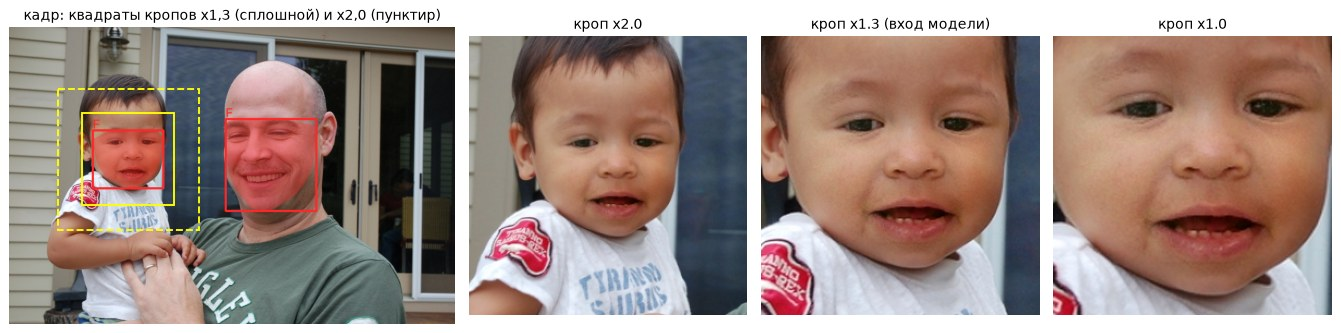

In [13]:
r0 = faces[faces["split"] == "Val"].iloc[0]
val_example_id = r0["image_id"]
img = frame_img("Val", val_example_id)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
for sc, ls in [(1.3, "-"), (2.0, "--")]:
    x0, y0, side = square_box(r0["x"], r0["y"], r0["w"], r0["h"], sc)
    axes[0].add_patch(plt.Rectangle((x0, y0), side, side, fill=False, ec="yellow", lw=1.5, ls=ls))
axes[0].imshow(draw_faces(img, faces_by_frame[("Val", val_example_id)])); axes[0].axis("off")
axes[0].set_title("кадр: квадраты кропов x1,3 (сплошной) и x2,0 (пунктир)")
for ax, sc in zip(axes[1:], [2.0, 1.3, 1.0]):
    ax.imshow(crop_face(img, r0["x"], r0["y"], r0["w"], r0["h"], scale=sc, out=256)); ax.axis("off")
    ax.set_title(f"кроп x{sc}" + (" (вход модели)" if sc == 1.3 else ""))
plt.tight_layout(); plt.show()

## 3.1 Три типа кадров

Каждый кадр по составу размеченных лиц относится к одному из трёх типов:
- **все лица настоящие** (`all_real`): ни одно лицо не подменяли;
- **все лица подменены** (`all_fake`);
- **смешанный** (`mixed`): на фото есть и настоящие, и подменённые лица. В таком кадре real и fake сняты
  одной камерой при одном свете, поэтому их сравнение ближе всего к «чистому» следу подделки.

In [14]:
ft = pd.crosstab(frames["split"], frames["frame_type"], normalize="index").loc[SPLITS, ["all_real", "mixed", "all_fake"]]
ff = pd.crosstab([faces["split"], faces["label"]], faces["frame_type"], normalize="index").loc[SPLITS, ["all_real", "mixed", "all_fake"]]
lpf = faces.groupby(["split", "frame_type"])["n_faces_in_frame"].mean().unstack().loc[SPLITS, ["all_real", "mixed", "all_fake"]]
display(Markdown("**Доля кадров каждого типа**")); display(ft.style.format("{:.1%}"))
display(Markdown("**Откуда берутся лица каждого класса** (доля лиц класса из кадров данного типа)")); display(ff.style.format("{:.1%}"))
display(Markdown("**Среднее число лиц на кадре данного типа**")); display(lpf.style.format("{:.2f}"))

**Доля кадров каждого типа**

frame_type,all_real,mixed,all_fake
split,,,
Train,1.0%,74.0%,25.0%
Val,0.1%,57.5%,42.4%
Test-Dev,0.2%,68.1%,31.7%


**Откуда берутся лица каждого класса** (доля лиц класса из кадров данного типа)

**Среднее число лиц на кадре данного типа**

frame_type,all_real,mixed,all_fake
split,,,
Train,4.16,6.25,2.02
Val,4.33,2.64,2.00
Test-Dev,3.09,3.24,2.21


*Как читать. Первая таблица: доля фото каждого типа в сплите. Вторая: из фото какого типа приходят лица каждого класса (строка = 100%). Третья: сколько в среднем лиц на фото такого типа.*

**Что видим.**

- Смешанных кадров большинство (Train 74%, Val 58%, Test-Dev 68%), «все fake» 25–42%, а **кадров «все
  real» почти нет**: 1,0% Train, 0,1% Val, 0,2% Test-Dev.
- 99% real-лиц приходят из смешанных кадров. Fake из кадров «все fake» составляют 28% fake Train, 59%
  fake Val, 42% fake Test-Dev, и в таких кадрах в среднем 2 лица, а в смешанных кадрах Train 6,3.

> **Опасность 1.** Фото, где все лица настоящие, модель почти не видит. Модель на всём кадре выучила бы
> «если на фото есть лица, какое-то подменено».
>
> **Опасность 2.** Real-лица приходят из групповых фото, fake часто из фото на двоих. В кроп ×1,3
> попадают соседи, поэтому «тесный кроп с чужими лицами» сам по себе подсказывает real (подробнее 3.2).

**Решение.** Модель работает с лицами, а не с кадрами. Сравнения real/fake делаем и внутри смешанных
кадров, где фото общее. Число лиц на кадре войдёт в шорткат-тест.

## 3.2 Чужое лицо в кропе

**Что проверяем.** В групповом фото лица стоят тесно, и в квадрат кропа одного лица может попасть
соседнее. Если в кроп **настоящего** лица попадает половина **подменённого** соседа, метка «real» на
этом кропе становится неоднозначной: модель видит артефакт подделки, а ей говорят «настоящее».

**Как считаем.** Для каждого лица строим кроп и смотрим, какая доля рамки каждого соседа в него
попадает. Лицо «загрязнено», если в кроп попадает ≥ 20% рамки соседа. Отдельно считаем соседей
**с противоположной меткой** и любых соседей; для кропа ×1,3 (вход модели) и ×2,0 (больше фона).
Считаем по рамкам, а не по пикселям лица, поэтому это **верхняя оценка**.

In [15]:
def contamination(scale, min_share=0.2):
    # для каждого лица: попадает ли в его кроп >= min_share рамки соседа (любого / с другой меткой)
    any_n, opp_n = np.zeros(len(faces), bool), np.zeros(len(faces), bool)
    for _, g in faces[faces["n_faces_in_frame"] > 1].groupby(["split", "image_id"]):
        b, lab = g[["x", "y", "w", "h"]].to_numpy(float), g["category_id"].to_numpy()
        x0, y0, side = square_box(b[:, 0], b[:, 1], b[:, 2], b[:, 3], scale)
        # пересечение кропа лица i с рамкой лица j (матрица n x n), делённое на площадь рамки j
        iw = np.clip(np.minimum((x0 + side)[:, None], (b[:, 0] + b[:, 2])[None]) - np.maximum(x0[:, None], b[None, :, 0]), 0, None)
        ih = np.clip(np.minimum((y0 + side)[:, None], (b[:, 1] + b[:, 3])[None]) - np.maximum(y0[:, None], b[None, :, 1]), 0, None)
        share = iw * ih / (b[:, 2] * b[:, 3])[None]
        np.fill_diagonal(share, 0)
        hit = share >= min_share
        any_n[g.index], opp_n[g.index] = hit.any(axis=1), (hit & (lab[:, None] != lab[None])).any(axis=1)
    return any_n, opp_n

for sc in [1.3, 2.0]:
    faces[f"neighbor_any_{sc}"], faces[f"neighbor_opposite_{sc}"] = contamination(sc)
cont = faces.groupby(["split", "label"])[["neighbor_opposite_1.3", "neighbor_any_1.3", "neighbor_opposite_2.0", "neighbor_any_2.0"]].mean()
cont.columns = ["x1,3: сосед с другой меткой", "x1,3: любой сосед", "x2,0: сосед с другой меткой", "x2,0: любой сосед"]
cont.loc[SPLITS].style.format("{:.1%}").background_gradient(cmap="Oranges", vmin=0, vmax=0.5)

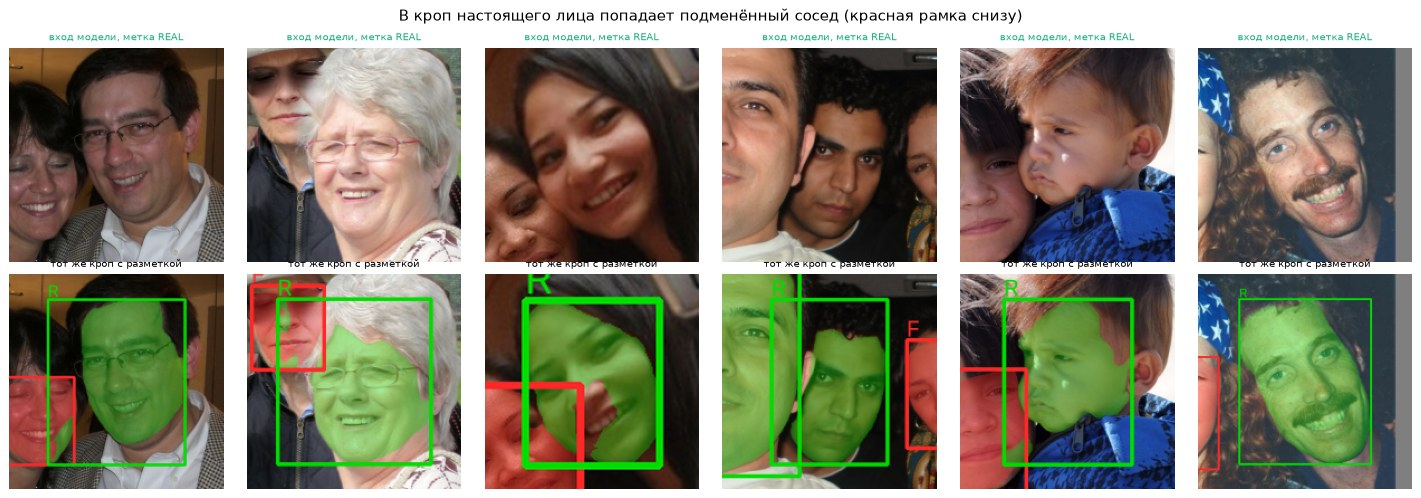

In [16]:
ex = faces[(faces["label"] == "real") & faces["neighbor_opposite_1.3"] & (faces["face_side_px"] >= 64)].pipe(sample_rows, 6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for k, (_, r) in enumerate(ex.iterrows()):
    img = frame_img(r["split"], r["image_id"])
    axes[0, k].imshow(crop_face(img, r["x"], r["y"], r["w"], r["h"], 1.3, 192))
    axes[0, k].set_title(f"вход модели, метка REAL", fontsize=8, color=PLOT_COLOR["real"])
    axes[1, k].imshow(crop_face(draw_faces(img, faces_by_frame[(r["split"], r["image_id"])]), r["x"], r["y"], r["w"], r["h"], 1.3, 192))
    axes[1, k].set_title("тот же кроп с разметкой", fontsize=8)
    axes[0, k].axis("off"); axes[1, k].axis("off")
fig.suptitle("В кроп настоящего лица попадает подменённый сосед (красная рамка снизу)")
plt.tight_layout(); plt.show()

*Как читать. Таблица: доля лиц, в кроп которых попадает сосед (с другой меткой или любой) при кропе ×1,3 и ×2,0; оранжевее = больше. Картинки: сверху то, что получит модель, снизу тот же кроп с разметкой.*

**Что видим.**

| Сосед с другой меткой в кропе | Train | Val | Test-Dev |
| --- | --- | --- | --- |
| real, кроп ×1,3 | 3,8% | **21,0%** | **10,8%** |
| fake, кроп ×1,3 | 2,8% | 5,6% | 4,8% |
| real, кроп ×2,0 | 13,8% | **46,5%** | 27,1% |

На примерах в кроп настоящего лица заходит половина подменённого соседа.

**Что это значит.** Загрязнение **асимметрично**: страдают в основном real-кропы, сильнее всего в Val
(каждый пятый). Модель получает метку «real» на картинке, где виден артефакт подделки, и в Val это ещё
и испортит оценку: часть ошибок на real будет реакцией на соседа, а не на само лицо.

**Решение.** В таблице лиц есть флаг `neighbor_opposite_1.3` (True, если в кроп ×1,3 попадает ≥ 20%
рамки соседа с другой меткой) и `neighbor_any_1.3`.
- Обучение: такие кропы убираем (в Train это около 3 200 real и 1 800 fake, ~3%).
- Оценка: метрики на Val и Test-Dev считаем дважды, на всех лицах и без загрязнённых, и сравниваем.
- Эксперимент с большим контекстом (кроп ×2,0, вопрос «лицо и фон») делаем только с **закрашенными
  соседями** (их рамки заливаем серым), иначе в Val загрязнена почти половина real.

## 3.3 Какую часть рамки занимает маска

**Что проверяем.** Рамка это прямоугольник, а маска это точный контур лица. Для fake маска показывает
**область, которую на самом деле нарисовал генератор**; всё, что в рамке вне маски (лоб, волосы, уши,
фон по углам), осталось настоящим. Для real маска это просто контур лица. Считаем
`mask_frac_of_bbox` = площадь маски ÷ площадь рамки (0…1).

**Зачем.** Если у fake маска занимает малую часть рамки, «подделка» в кропе состоит в основном из
настоящих пикселей, и модель должна искать артефакт в маленькой области. Если маски real и fake устроены
по-разному, это различие в разметке, а не в лицах.

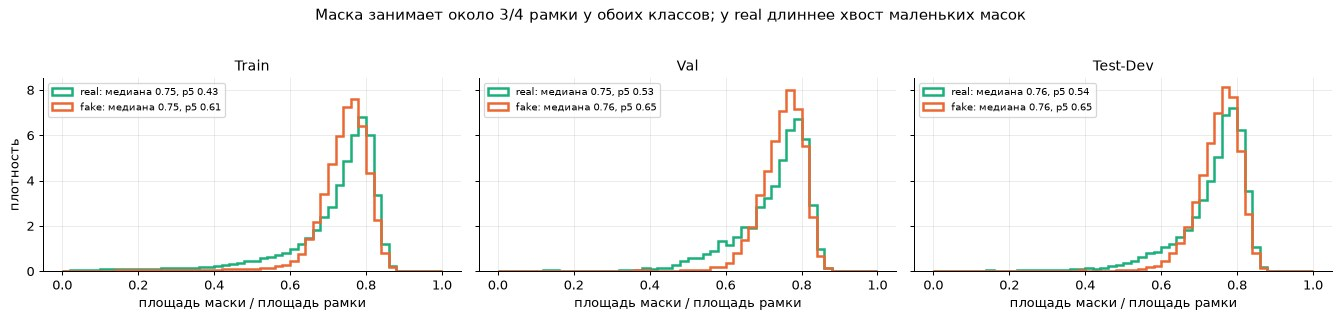

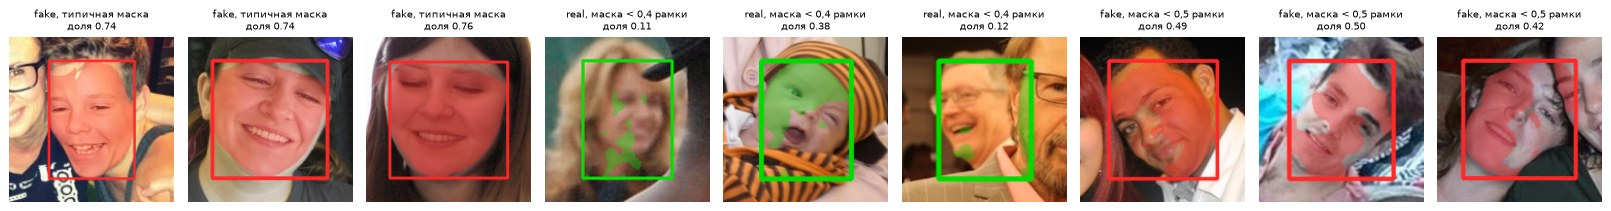

In [17]:
faces["mask_frac_of_bbox"] = faces["area"] / (faces["w"] * faces["h"])   # area = число пикселей маски (приложение A2)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for ax, s in zip(axes, SPLITS):
    for lab in ["real", "fake"]:
        v = faces.loc[(faces["split"] == s) & (faces["label"] == lab), "mask_frac_of_bbox"]
        ax.hist(v, bins=np.linspace(0, 1, 51), density=True, histtype="step", lw=2, color=PLOT_COLOR[lab],
                label=f"{lab}: медиана {v.median():.2f}, p5 {v.quantile(0.05):.2f}")
    ax.set_title(s); ax.set_xlabel("площадь маски / площадь рамки"); ax.legend(fontsize=8)
axes[0].set_ylabel("плотность")
fig.suptitle("Маска занимает около 3/4 рамки у обоих классов; у real длиннее хвост маленьких масок", y=1.03)
plt.tight_layout(); plt.show()

# Как выглядят: типичная маска fake, маленькая маска real и маленькая маска fake (лица >= 80 px)
big = faces[faces["face_side_px"] >= 80]
sel = [("fake, типичная маска", big[(big["label"] == "fake") & big["mask_frac_of_bbox"].between(0.72, 0.76)].pipe(sample_rows, 3, random_state=SEED)),
       ("real, маска < 0,4 рамки", big[(big["label"] == "real") & (big["mask_frac_of_bbox"] < 0.4)].pipe(sample_rows, 3, random_state=SEED)),
       ("fake, маска < 0,5 рамки", big[(big["label"] == "fake") & (big["mask_frac_of_bbox"] < 0.5)].pipe(sample_rows, 3, random_state=SEED))]
fig, axes = plt.subplots(1, 9, figsize=(18, 2.6))
for k, (name, g) in enumerate(sel):
    for m, (_, r) in enumerate(g.iterrows()):
        ax = axes[k * 3 + m]
        vis = draw_faces(frame_img(r["split"], r["image_id"]), faces_by_frame[(r["split"], r["image_id"])].loc[[r.name]], letters=False)
        ax.imshow(crop_face(vis, r["x"], r["y"], r["w"], r["h"], 1.4, 160)); ax.axis("off")
        ax.set_title(f"{name}\nдоля {r['mask_frac_of_bbox']:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

*Как читать. Графики: какую часть рамки занимает маска лица у real и fake (правее = маска почти заполняет рамку). Картинки: типичные и маленькие маски.*

**Что видим.**

- Медиана доли маски в рамке у обоих классов **0,75–0,76** во всех сплитах. Но у real длиннее левый
  хвост: 5% real-лиц имеют маску меньше 0,43 рамки в Train (у fake 0,61).
- На примерах: типичная маска fake закрывает лицо от бровей до подбородка без лба, волос и ушей.
  Маленькие маски real часто **рваные**: несколько пятен вместо контура лица (дефект разметки), таких
  real с маской < 0,4 рамки около 4% в Train и 1% в Val и Test-Dev. Маленькие маски fake обычно у лиц,
  частично закрытых волосами или рукой.

**Что это значит.** В кропе ×1,3 площадь квадрата не меньше 1,69 площади рамки, а маска fake около 0,75
рамки. Значит, **генератор нарисовал не больше 44% пикселей fake-кропа**, остальное настоящие пиксели
(лоб, волосы, фон). Модели нужно найти подделку в меньшей половине картинки.

**Решение.** Доля маски хранится в таблице лиц как **атрибут** `mask_frac_of_bbox`, то есть как столбец,
который мы сами вычислили из разметки для диагностики (модели он не подаётся). Real-лица с рваной маской
(< 0,4) не используем там, где нужна маска (свет по маске, анализ шва).

## 3.4 Рамка fake устроена иначе, чем рамка real

**Что проверяем.** В разметке рамка лица у обоих классов совпадает с границами маски. Но маска fake
описывает **подменённую область**, а маска real описывает **всё лицо**. Если эти области разные, то
рамки и кропы real и fake будут кадрированы по-разному, даже если лица одинаковые. Проверить это можно
на парах из шага 2.3, где одно и то же лицо в одной копии фото real, в другой fake: поза, размер и свет
у такого лица одинаковые по построению, отличаться может только разметка.

In [18]:
pair_src = faces[faces["face_src_id"].isin(mixed_src)]
r = pair_src[pair_src["label"] == "real"].groupby("face_src_id")[["x", "y", "w", "h", "area"]].first()
f = pair_src[pair_src["label"] == "fake"].groupby("face_src_id")[["x", "y", "w", "h", "area"]].first()
both = r.index.intersection(f.index); r, f = r.loc[both], f.loc[both]
geo = pd.DataFrame({"ширина рамки fake / real": f["w"] / r["w"], "высота рамки fake / real": f["h"] / r["h"],
                    "площадь маски fake / real": f["area"] / r["area"],
                    "сдвиг верха рамки, доля высоты": (f["y"] - r["y"]) / r["h"],
                    "сдвиг низа рамки, доля высоты": ((f["y"] + f["h"]) - (r["y"] + r["h"])) / r["h"]})
print(f"Пар «одно лицо: real и fake»: {len(both):,}")
display(geo.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T[["10%", "25%", "50%", "75%", "90%"]].style.format("{:.3f}"))
print(f"Доля пар, где рамка fake меньше по площади: {((f['w'] * f['h']) < (r['w'] * r['h'])).mean():.1%}")

Пар «одно лицо: real и fake»: 16,669


,10%,25%,50%,75%,90%
ширина рамки fake / real,0.800,0.870,0.943,0.987,1.000
высота рамки fake / real,0.680,0.775,0.898,0.966,1.000
площадь маски fake / real,0.599,0.737,0.869,0.942,0.980
"сдвиг верха рамки, доля высоты",0.000,0.008,0.063,0.163,0.279
"сдвиг низа рамки, доля высоты",-0.108,-0.044,-0.013,0.000,0.000


Доля пар, где рамка fake меньше по площади: 95.4%


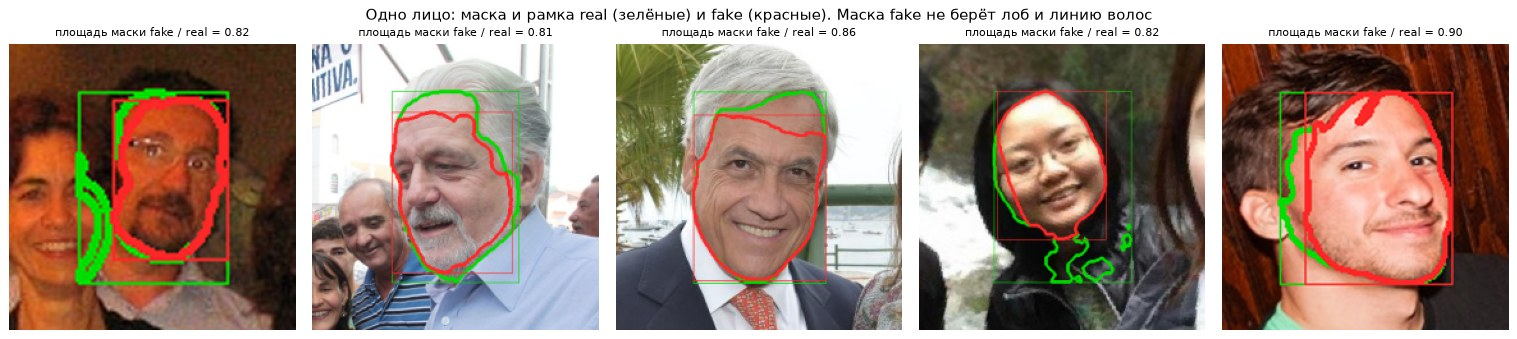

In [19]:
# Одно и то же лицо (пиксели real-копии): зелёный контур = маска real, красный = маска fake из другой копии
pick = both.to_series().pipe(sample_rows, 5, random_state=SEED + 5)
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, src in zip(axes, pick):
    g = pair_src[pair_src["face_src_id"] == src]
    rr, ff = g[g["label"] == "real"].iloc[0], g[g["label"] == "fake"].iloc[0]
    img = frame_img(rr["split"], rr["image_id"]).copy()
    H, W = img.shape[:2]
    t = max(2, int(rr["face_side_px"] / 60))
    for row, col in [(rr, (0, 220, 0)), (ff, (255, 40, 40))]:
        cnts, _ = cv2.findContours(polygon_mask(row["segmentation"], H, W), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(img, cnts, -1, col, t)
        cv2.rectangle(img, (int(row["x"]), int(row["y"])), (int(row["x"] + row["w"]), int(row["y"] + row["h"])), col, max(1, t // 2))
    ax.imshow(crop_face(img, rr["x"], rr["y"], rr["w"], rr["h"], 1.5, 224)); ax.axis("off")
    ax.set_title(f"площадь маски fake / real = {ff['area'] / rr['area']:.2f}", fontsize=9)
fig.suptitle("Одно лицо: маска и рамка real (зелёные) и fake (красные). Маска fake не берёт лоб и линию волос")
plt.tight_layout(); plt.show()

*Как читать. Таблица: во сколько раз рамка и маска подделки отличаются от рамки того же лица в настоящей копии (1 = одинаково) и насколько сдвинуты верх и низ рамки; столбцы = 10%, 25%, 50%, 75%, 90% пар. Картинки: зелёный контур = разметка real, красный = разметка fake того же лица.*

**Что видим.**

- На 16 669 парах «одно лицо, real и fake» **рамка fake меньше рамки real в 95% пар**. Медианы:
  ширина 0,94, высота 0,90, площадь маски 0,87 от real. Верх рамки fake ниже на 6% высоты лица (у четверти
  пар на 16% и больше), низ почти совпадает.
- На картинках видно почему: маска real обводит всё лицо до линии волос, маска fake только область,
  которую нарисовал генератор, без лба. Рамка у обоих классов = границы маски.

> **Опасность 3 (шорткат из разметки).** Кроп, построенный по рамке из разметки, у fake **кадрирован
> иначе**: лицо крупнее, лба и волос меньше, центр ниже. Модель может научиться отличать классы по
> кадрированию, а не по подделке. Тот же эффект искажает «размер лица»: у fake он занижен примерно на 10%
> по стороне (13% по площади).

**Что это значит для других выводов.** Отношение «fake / real-сосед на одном кадре» ≈ 0,87 (шаг 7.1)
совпадает с этой разницей рамок, то есть «fake мельче соседа» почти целиком объясняется разметкой.

**Решение.** Кропы строим **не по рамке из разметки, а по рамке детектора лиц** (YuNet
находит 97–100% размеченных лиц ≥ 32 px обоих классов, шаг 3.6): процедура одна для real и fake, как в
DeepfakeBench. Рамку из разметки используем только для сопоставления детекции с меткой. Повторим
шорткат-тест с обоими вариантами кропа.

## 3.5 Очень маленькие лица

**Что проверяем.** Сколько в данных лиц, на которых подделку **физически нельзя увидеть**. Возьмём
лицо 20×20 пикселей: в кроп 256×256 его придётся растянуть в 13 раз, каждый исходный пиксель станет
пятном 13×13. Мелкие следы генератора (текстура кожи, шов) при этом исчезают.

**Откуда порог 32 px.** Это не закон, а принятая граница «маленького объекта»: в стандарте COCO
маленькими считаются объекты меньше 32×32 пикселей, и детекторы на них работают заметно хуже. Мы
проверяем, разумен ли этот порог для наших данных, тремя способами: глазами, по доле таких лиц и по
тому, видит ли их независимый детектор лиц (3.6).

Размер лица `face_side_px` = √(ширина × высота рамки).

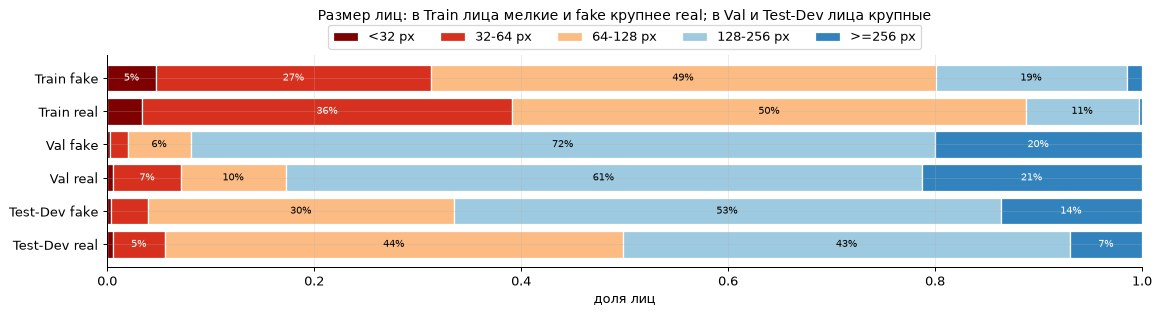

Лиц < 32 px: {'Train': {'fake': 3133, 'real': 2897}, 'Val': {'fake': 28, 'real': 29}, 'Test-Dev': {'fake': 96, 'real': 125}}


In [20]:
sb = pd.crosstab([faces["split"], faces["label"]], faces["size_bin"], normalize="index").loc[SPLITS]
fig, ax = plt.subplots(figsize=(13, 3.6))
colors = ["#7f0000", "#d7301f", "#fdbb84", "#9ecae1", "#3182bd"]
labels = [f"{s} {l}" for s, l in sb.index]
left = np.zeros(len(sb))
for c, col in zip(SIZE_NAMES, colors):
    ax.barh(labels, sb[c], left=left, color=col, label=f"{c} px", edgecolor="white")
    for y, (l, v) in enumerate(zip(left, sb[c])):
        if v > 0.04:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if c in ("<32", "32-64", ">=256") else "black")
    left += sb[c].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("доля лиц"); ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Размер лиц: в Train лица мелкие и fake крупнее real; в Val и Test-Dev лица крупные", pad=28)
plt.tight_layout(); plt.show()
n_tiny = faces[faces["face_side_px"] < 32].groupby(["split", "label"]).size().unstack().loc[SPLITS]
print("Лиц < 32 px:", n_tiny.to_dict("index"))

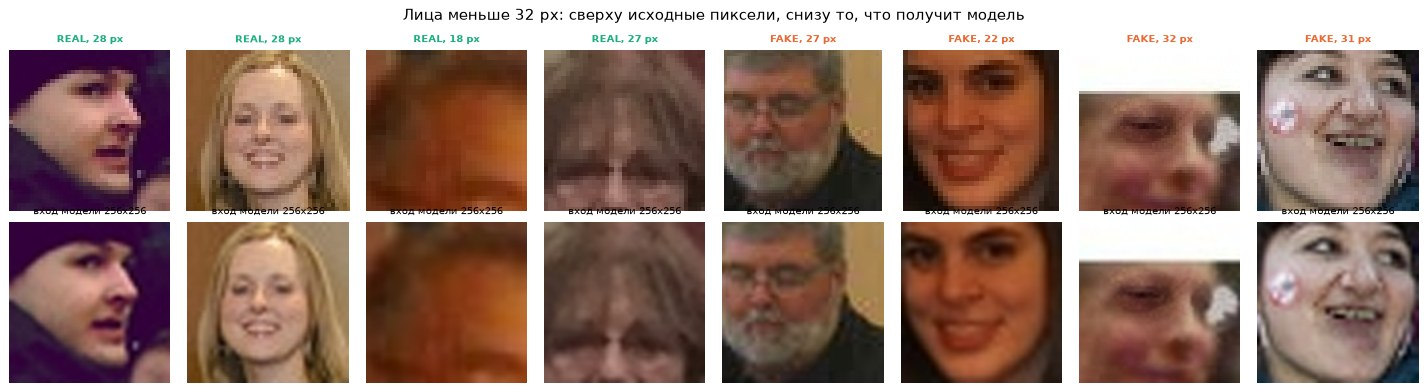

In [21]:
small = pd.concat([faces[(faces["face_side_px"] < 32) & (faces["label"] == lab)].pipe(sample_rows, 4, random_state=SEED) for lab in ["real", "fake"]])
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for k, (_, r) in enumerate(small.iterrows()):
    img = frame_img(r["split"], r["image_id"])
    x0, y0, side = square_box(r["x"], r["y"], r["w"], r["h"], 1.3)
    axes[0, k].imshow(img[max(int(y0), 0):int(y0 + side), max(int(x0), 0):int(x0 + side)], interpolation="nearest")
    axes[0, k].set_title(f"{r['label'].upper()}, {r['face_side_px']:.0f} px", fontsize=8, color=PLOT_COLOR[r["label"]], fontweight="bold")
    axes[1, k].imshow(crop_face(img, r["x"], r["y"], r["w"], r["h"], 1.3, 256)); axes[1, k].set_title("вход модели 256x256", fontsize=8)
    axes[0, k].axis("off"); axes[1, k].axis("off")
fig.suptitle("Лица меньше 32 px: сверху исходные пиксели, снизу то, что получит модель")
plt.tight_layout(); plt.show()

*Как читать. Полосы: доля лиц каждого размера в каждом сплите и классе. Картинки: сверху исходные пиксели маленького лица, снизу то, что получит модель после растяжения.*

**Что видим.**

| Доля лиц | < 32 px | 32–64 | 64–128 | 128–256 | ≥ 256 |
| --- | --- | --- | --- | --- | --- |
| Train real | 3,4% | **35,7%** | 49,7% | 10,8% | 0,3% |
| Train fake | 4,8% | 26,5% | 48,7% | **18,5%** | 1,4% |
| Val real / fake | 0,6% / 0,3% | 6,5% / 1,7% | 10,1% / 6,1% | 61,5% / 71,9% | 21,3% / 20,0% |
| Test-Dev real / fake | 0,6% / 0,3% | 5,0% / 3,6% | 44,3% / 29,6% | 43,2% / 52,8% | 6,9% / 13,7% |

Лиц меньше 32 px: в Train 6 030 (2 897 real и 3 133 fake), в Val 57, в Test-Dev 221.
На картинках real и fake < 32 px выглядят одинаково размытыми пятнами.

**Что это значит.**
1. В Train **лица маленькие** (медиана ~80 px) и fake смещены в сторону крупных, в Val и Test-Dev лица
   в 2–2,6 раза крупнее. Модель, обученная на Train, на Val и Test-Dev попадёт в непривычный масштаб.
2. На лицах < 32 px подделку физически не видно, но классы различаются **другим**: детектор лиц находит
   78% мелких fake и только 53% мелких real, MediaPipe не находит лицо у 61% мелких real и 41% мелких
   fake (шаг 6.1). Похоже, генератор рисует чёткое лицо даже в 20 px, а мелкие настоящие лица
   размыты и повёрнуты. Модель на таких лицах выучит «чёткость пятна», а не подделку.
3. Проверить качество на мелких лицах всё равно нельзя: в Val и Test-Dev их меньше 1%.

**Решение.** Лица < 32 px исключаем из обучения и оценки и помечаем «недостаточно данных» (в сервисе
это отдельный ответ). Лица 32–64 px оставляем, но метрики по ним считаем отдельно. Все метрики модели
отчитываем по бинам размера.

## 3.6 Неразмеченные лица

**Что проверяем.** На некоторых кадрах есть лица без рамки: ни real, ни fake. Ищем их систематически:
запускаем на полных кадрах независимый детектор лиц **YuNet**¹ и берём уверенные находки (уверенность
≥ 0,9, размер ≥ 32 px), которые почти не пересекаются с рамками разметки (покрыто < 30% находки).
Заодно смотрим обратное: находит ли YuNet размеченные лица, и одинаково ли хорошо для real и fake.

¹ *YuNet: лёгкая нейросеть-детектор лиц из библиотеки OpenCV; возвращает рамку, 5 точек лица и уверенность 0…1.*

,кадров,кадров с неразмеченным лицом,неразмеченных лиц,размеченных лиц,доля кадров
split,,,,,
Train,44097,9906,16045,150866,22.5%
Val,7308,617,759,15345,8.4%
Test-Dev,18895,1962,2423,49718,10.4%


Медиана размера: неразмеченные 60 px, размеченные 94 px


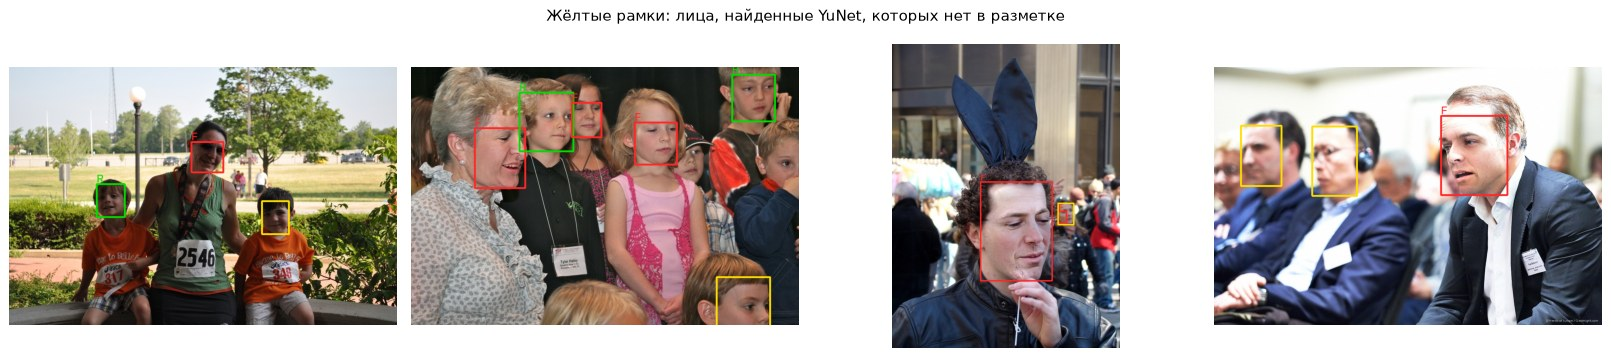

In [22]:
det["side"] = np.sqrt(det["det_w"] * det["det_h"])
un = det[(det["covered"] < 0.3) & (det["det_score"] >= 0.9) & (det["side"] >= 32)]
t = pd.DataFrame({"кадров": frames.groupby("split").size(),
                  "кадров с неразмеченным лицом": un.groupby("split")["image_id"].nunique(),
                  "неразмеченных лиц": un.groupby("split").size(),
                  "размеченных лиц": faces.groupby("split").size()}).loc[SPLITS]
t["доля кадров"] = t["кадров с неразмеченным лицом"] / t["кадров"]
display(t.style.format({"доля кадров": "{:.1%}"}, precision=0))
print("Медиана размера: неразмеченные", round(un["side"].median()), "px, размеченные", round(faces["face_side_px"].median()), "px")

pick = un.sort_values("det_score", ascending=False).groupby(["split", "image_id"]).head(1).pipe(sample_rows, 4, random_state=SEED)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (_, r) in zip(axes, pick.iterrows()):
    vis = draw_faces(frame_img(r["split"], r["image_id"]), faces_by_frame[(r["split"], r["image_id"])], masks=False)
    t_ = max(3, int(max(vis.shape[:2]) / 250))
    for _, q in un[(un["split"] == r["split"]) & (un["image_id"] == r["image_id"])].iterrows():
        cv2.rectangle(vis, (int(q["det_x"]), int(q["det_y"])), (int(q["det_x"] + q["det_w"]), int(q["det_y"] + q["det_h"])), (255, 220, 0), t_)
    ax.imshow(vis); ax.axis("off")
fig.suptitle("Жёлтые рамки: лица, найденные YuNet, которых нет в разметке")
plt.tight_layout(); plt.show()

In [23]:
# Обратная проверка: доля РАЗМЕЧЕННЫХ лиц, которые находит YuNet (IoU с находкой >= 0,3), по размеру и классу
det_by_frame = {k: g[["det_x", "det_y", "det_w", "det_h"]].to_numpy(float) for k, g in det[det["det_score"] >= 0.6].groupby(["split", "image_id"])}
def best_iou(r):
    boxes = det_by_frame.get((r.split, r.image_id), [])
    return max([iou((r.x, r.y, r.w, r.h), b) for b in boxes], default=0.0)
faces["yunet_found"] = [best_iou(r) >= 0.3 for r in faces[["split", "image_id", "x", "y", "w", "h"]].itertuples(index=False)]
rec = faces.groupby(["size_bin", "split", "label"], observed=True)["yunet_found"].mean().unstack()
rec.style.format("{:.0%}")

*Как читать. Первая таблица: сколько найдено неразмеченных лиц. Картинки: жёлтые рамки = лица, которых нет в разметке. Последняя таблица: какую долю размеченных лиц находит детектор, по размеру и классу.*

**Что видим.**

- Уверенно найденное неразмеченное лицо есть в **22,5% кадров Train** (16 045 лиц, это 11% от
  размеченных), в 8,4% кадров Val и 10,4% Test-Dev. Неразмеченные лица мельче (медиана 60 px против 94).
- На картинках это в основном настоящие лица людей на заднем плане, детей, частично закрытые лица.
  Бывают и ошибки детектора (портреты, отражения), поэтому числа это верхняя оценка.
- Размеченные лица ≥ 32 px YuNet находит в 97–100% случаев у обоих классов: детектор «видит» real и fake
  одинаково хорошо. Различие только у лиц < 32 px (3.5).

**Что это значит.** Разметка покрывает не все лица. Похоже, авторы размечали только лица, прошедшие
фильтр пригодности: и подменённые, и оставленные настоящими. Это **хорошо** для сравнения классов
(real и fake прошли один фильтр) и **плохо** для всего остального: неразмеченное лицо может попасть в
кроп соседа, а задачу «найти подделку на всём фото» на этой разметке ставить нельзя.

**Решение.** Работаем только с размеченными лицами. Неразмеченные лица в кропе соседа считаем
настоящим контекстом. Флаг `yunet_found` сохраняем: он нужен для кропов по детектору (3.4).

## 3.7 Одно лицо размечено дважды, иногда с разными метками

**Что проверяем.** Ищем пары рамок одного кадра, которые описывают одно и то же лицо. Рамки двух людей,
стоящих друг за другом, тоже сильно перекрываются, поэтому решение принимаем по **маскам**: если
контуры почти совпадают (IoU масок ≥ 0,6), это одно лицо, размеченное дважды.

метки,fake + fake,fake + real,real + real
mask_iou,,,
"(-0.001, 0.2]",2,7,27
"(0.2, 0.4]",14,34,58
"(0.4, 0.6]",13,48,22
"(0.6, 0.8]",39,39,9
"(0.8, 1.0]",61,34,24


Противоречивых пар (одно лицо: real и fake): 73, лиц 146 (по сплитам {'Test-Dev': 20, 'Train': 106, 'Val': 20}); дважды с одной меткой: 266 лиц; кадров всего: 187


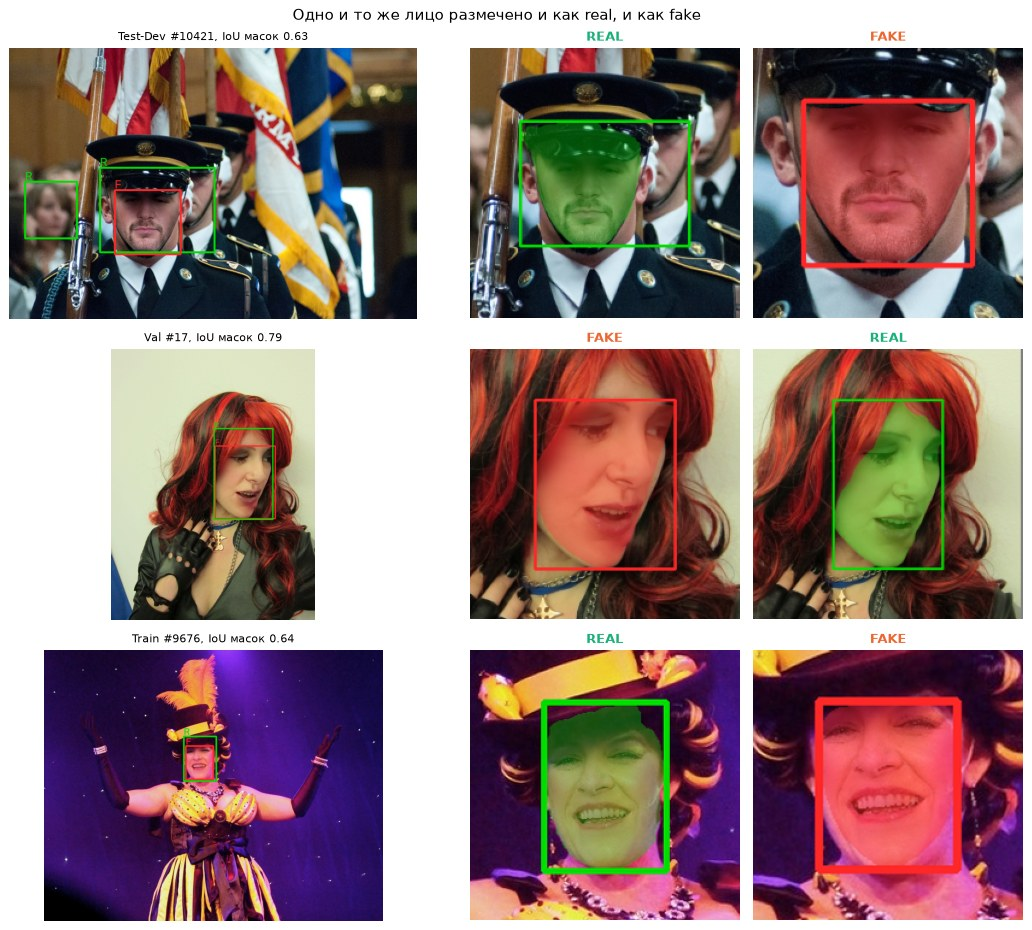

In [24]:
def mask_iou(seg_a, seg_b, box_a, box_b):
    # растеризуем обе маски в общем окне вокруг двух рамок и считаем IoU
    x0, y0 = int(min(box_a[0], box_b[0])) - 2, int(min(box_a[1], box_b[1])) - 2
    x1, y1 = int(max(box_a[0] + box_a[2], box_b[0] + box_b[2])) + 2, int(max(box_a[1] + box_a[3], box_b[1] + box_b[3])) + 2
    shift = lambda seg: [(np.array(p, float).reshape(-1, 2) - [x0, y0]).ravel().tolist() for p in seg]
    ma, mb = polygon_mask(shift(seg_a), y1 - y0, x1 - x0).astype(bool), polygon_mask(shift(seg_b), y1 - y0, x1 - x0).astype(bool)
    return (ma & mb).sum() / max((ma | mb).sum(), 1)

ov = []
for (s, img_id), g in faces[faces["n_faces_in_frame"] > 1].groupby(["split", "image_id"]):
    b = g[["x", "y", "w", "h"]].to_numpy(float)
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            if iou(b[i], b[j]) > 0.3:
                ov.append({"ia": g.index[i], "ib": g.index[j], "split": s, "image_id": img_id,
                           "mask_iou": mask_iou(g["segmentation"].iloc[i], g["segmentation"].iloc[j], b[i], b[j]),
                           "метки": " + ".join(sorted([g["label"].iloc[i], g["label"].iloc[j]]))})
ov = pd.DataFrame(ov)
same_face = ov[ov["mask_iou"] >= 0.6]
confl = same_face[same_face["метки"] == "fake + real"]
faces["ann_conflict"] = faces.index.isin(np.r_[confl["ia"], confl["ib"]])
faces["ann_double"] = faces.index.isin(np.r_[same_face["ia"], same_face["ib"]]) & ~faces["ann_conflict"]
display(pd.crosstab(pd.cut(ov["mask_iou"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True), ov["метки"]))
print(f"Противоречивых пар (одно лицо: real и fake): {len(confl)}, лиц {int(faces['ann_conflict'].sum())} "
      f"(по сплитам {faces[faces['ann_conflict']].groupby('split').size().to_dict()}); "
      f"дважды с одной меткой: {int(faces['ann_double'].sum())} лиц; кадров всего: {same_face[['split', 'image_id']].drop_duplicates().shape[0]}")

pick = confl.drop_duplicates(["split", "image_id"]).pipe(sample_rows, 3, random_state=SEED)
fig, axes = plt.subplots(len(pick), 3, figsize=(12, 3.5 * len(pick)), gridspec_kw={"width_ratios": [1.8, 1, 1]})
for row_axes, (_, pr) in zip(axes, pick.iterrows()):
    img = frame_img(pr["split"], pr["image_id"])
    row_axes[0].imshow(draw_faces(img, faces_by_frame[(pr["split"], pr["image_id"])], masks=False))
    row_axes[0].set_title(f"{pr['split']} #{pr['image_id']}, IoU масок {pr['mask_iou']:.2f}", fontsize=9)
    for ax, idx in zip(row_axes[1:], [pr["ia"], pr["ib"]]):
        r = faces.loc[idx]
        ax.imshow(crop_face(draw_faces(img, faces.loc[[idx]], letters=False), r["x"], r["y"], r["w"], r["h"], 1.6, 224))
        ax.set_title(r["label"].upper(), fontsize=10, color=PLOT_COLOR[r["label"]], fontweight="bold")
    for ax in row_axes:
        ax.axis("off")
fig.suptitle("Одно и то же лицо размечено и как real, и как fake")
plt.tight_layout(); plt.show()

*Как читать. Таблица: пары сильно перекрытых рамок одного фото по тому, насколько совпадают их маски (столбцы = сочетание меток). Картинки: одно лицо, размеченное и real, и fake.*

**Что видим.**

- **73 пары** (146 лиц: Train 106, Val 20, Test-Dev 20), где **одно и то же лицо размечено и real,
  и fake**, и 266 лиц, размеченных дважды с одной меткой. Всего 187 кадров (0,27%).
- На примерах обе рамки лежат на одном лице. Похоже, в разметку кадра попали аннотации и исходного
  фото, и его подменённой копии.

**Что это значит.** Модель получает на один и тот же вход противоположные ответы. Случаев мало, но это
прямой шум в метках. Порог 0,6 по маскам выбран по таблице и примерам, а часть масок рваная, поэтому
73 пары это скорее нижняя оценка.

**Решение.** Флаги `ann_conflict` и `ann_double`. Противоречивые лица исключаем из обучения и оценки,
из дублей с одной меткой оставляем одну рамку.

## Итог шага 3

| Находка | Насколько велика | Решение для обучения |
| --- | --- | --- |
| Кадров «все real» почти нет | 0,1–1% кадров | модель на лицах, не на кадрах |
| Чужое лицо с другой меткой в кропе | real: 4% Train, 21% Val, 11% Test-Dev | убрать из обучения, метрики с ними и без; контекст ×2,0 только с закрашенными соседями |
| Генератор нарисовал ≤ 44% пикселей fake-кропа | маска ≈ 0,75 рамки | учитывать в анализе шва |
| **Рамка fake туже рамки real того же лица** | в 95% пар, площадь −13%, верх ниже | **кропы строить по детектору лиц**, а не по разметке |
| Лица < 32 px неинформативны, но классы различаются по «чёткости» | 4% Train, < 1% Val/Test-Dev | исключить, ответ «недостаточно данных» |
| Неразмеченные лица | 22,5% кадров Train | только размеченные лица; ограничение данных |
| Одно лицо с метками real и fake | 73 пары | исключить |

---
# 4. Визуальный осмотр: как выглядят подделки

**Зачем.** Числа не показывают, *как выглядит* подделка, а без этого непонятно, что измеряют метрики
дальше. Смотрим по чек-листу видимых артефактов (из работы Celeb-DF): размытая или «пластиковая»
кожа, видимый шов по краю маски, несовпадение цвета лица и шеи, остатки исходного лица (двойной контур
бровей, очков, подбородка). Всё, что видно глазами, это **гипотезы**, которые проверяют шаги 5–7.

## 4.1 Кропы real и fake рядом и мини-тест «угадай глазами»

24 случайных кропа real и 24 fake из Train (только лица ≥ 64 px, чтобы было что разглядывать). Ниже
перемешанная сетка без подписей: можно угадать самому, ответы в следующей ячейке. В статье
OpenForensics люди угадывали 59,7%, то есть немного лучше монетки.

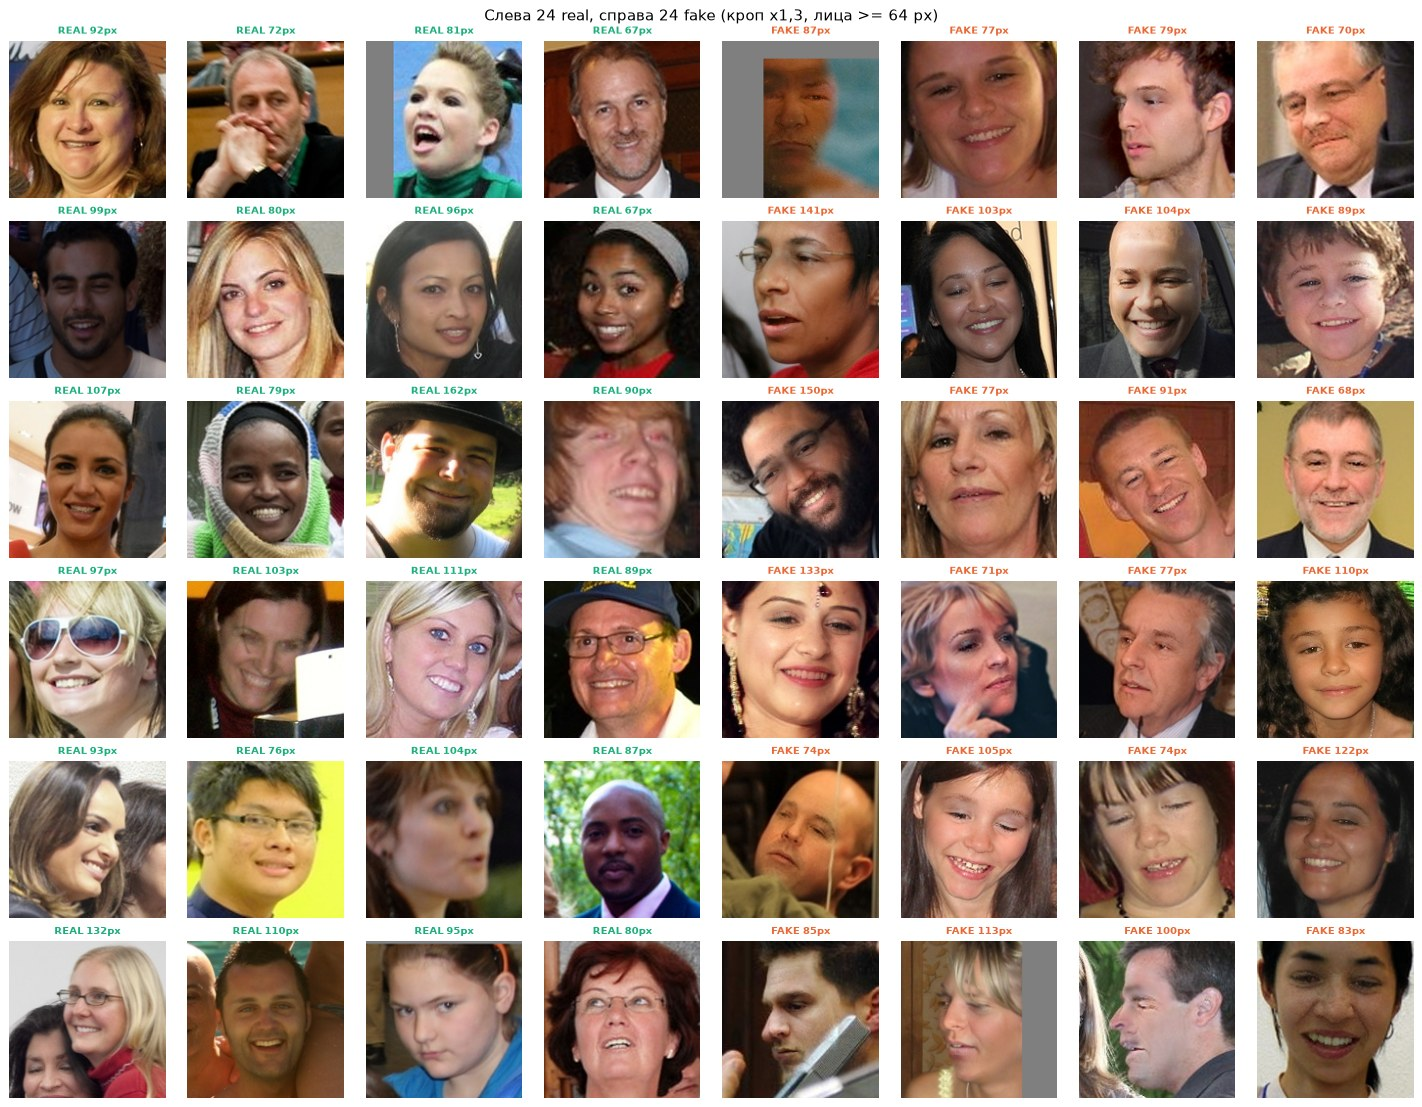

In [25]:
big = faces[(faces["split"] == "Train") & (faces["face_side_px"] >= 64) & ~faces["ann_conflict"]]
fig, axes = plt.subplots(6, 8, figsize=(16, 12.5))
for col0, lab in [(0, "real"), (4, "fake")]:
    for k, (_, r) in enumerate(big[big["label"] == lab].pipe(sample_rows, 24, random_state=SEED).iterrows()):
        ax = axes[k // 4, col0 + k % 4]
        ax.imshow(crop_of(r)); ax.axis("off")
        ax.set_title(f"{lab.upper()} {r['face_side_px']:.0f}px", fontsize=8, color=PLOT_COLOR[lab], fontweight="bold")
fig.suptitle("Слева 24 real, справа 24 fake (кроп x1,3, лица >= 64 px)", fontsize=12)
plt.tight_layout(); plt.show()

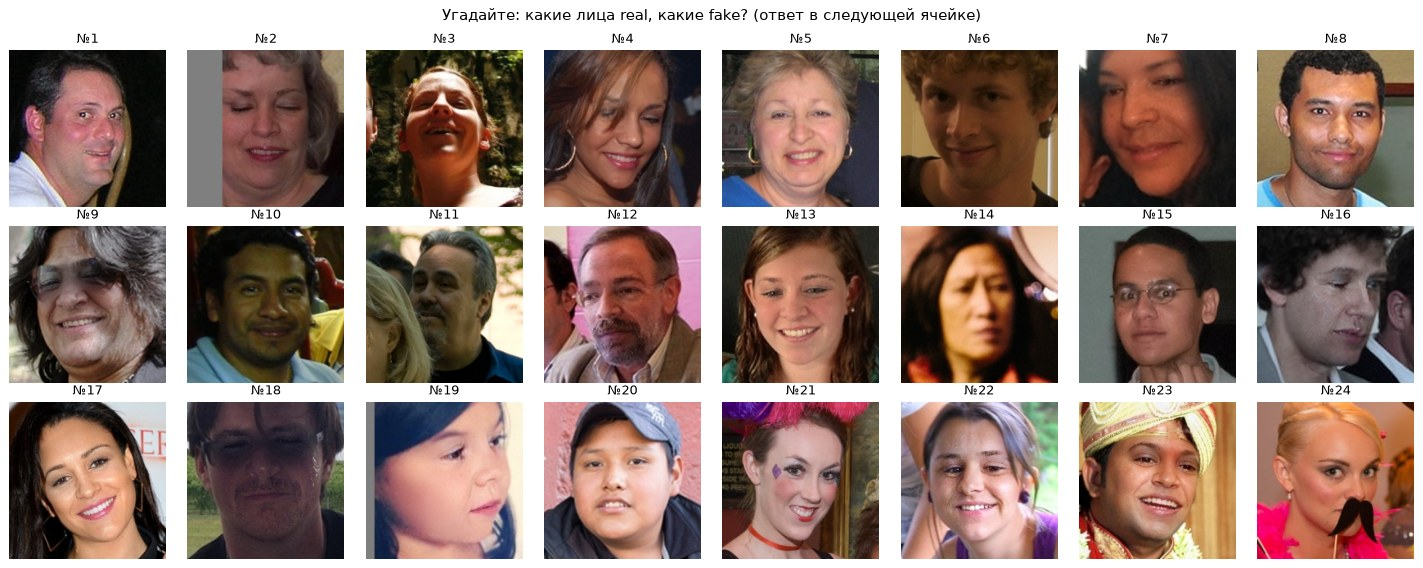

In [26]:
quiz = pd.concat([big[big["label"] == lab].pipe(sample_rows, 12, random_state=SEED + 1) for lab in ["real", "fake"]]).sample(frac=1, random_state=SEED)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for k, (ax, (_, r)) in enumerate(zip(axes.ravel(), quiz.iterrows())):
    ax.imshow(crop_of(r, out=192)); ax.axis("off"); ax.set_title(f"№{k + 1}", fontsize=10)
fig.suptitle("Угадайте: какие лица real, какие fake? (ответ в следующей ячейке)", fontsize=12)
plt.tight_layout(); plt.show()

In [27]:
print("Ответы:", ", ".join(f"№{k + 1}: {lab}" for k, lab in enumerate(quiz["label"])))

Ответы: №1: real, №2: fake, №3: real, №4: fake, №5: real, №6: real, №7: fake, №8: real, №9: fake, №10: real, №11: real, №12: fake, №13: fake, №14: real, №15: real, №16: fake, №17: fake, №18: fake, №19: fake, №20: real, №21: real, №22: fake, №23: fake, №24: real


**Что видно.** Часть fake выдаёт себя: слишком гладкая, «восковая» кожа, лицо заметно мягче, чем волосы и фон вокруг,
иногда другой оттенок кожи, чем у шеи. Но многие fake выглядят совершенно естественно, а размытые real
легко принять за подделку. Глазами задача трудная: это согласуется с 59,7% у людей в статье.

## 4.2 Оригинал и подделка одного и того же лица

Из шага 2.3: одно и то же лицо в одной копии фото настоящее, в другой подменено. Режем оба кропа по
**одной рамке** и строим карту разницы |real − fake|: она показывает, какие пиксели на самом деле
изменил генератор. Справа маска fake из разметки.

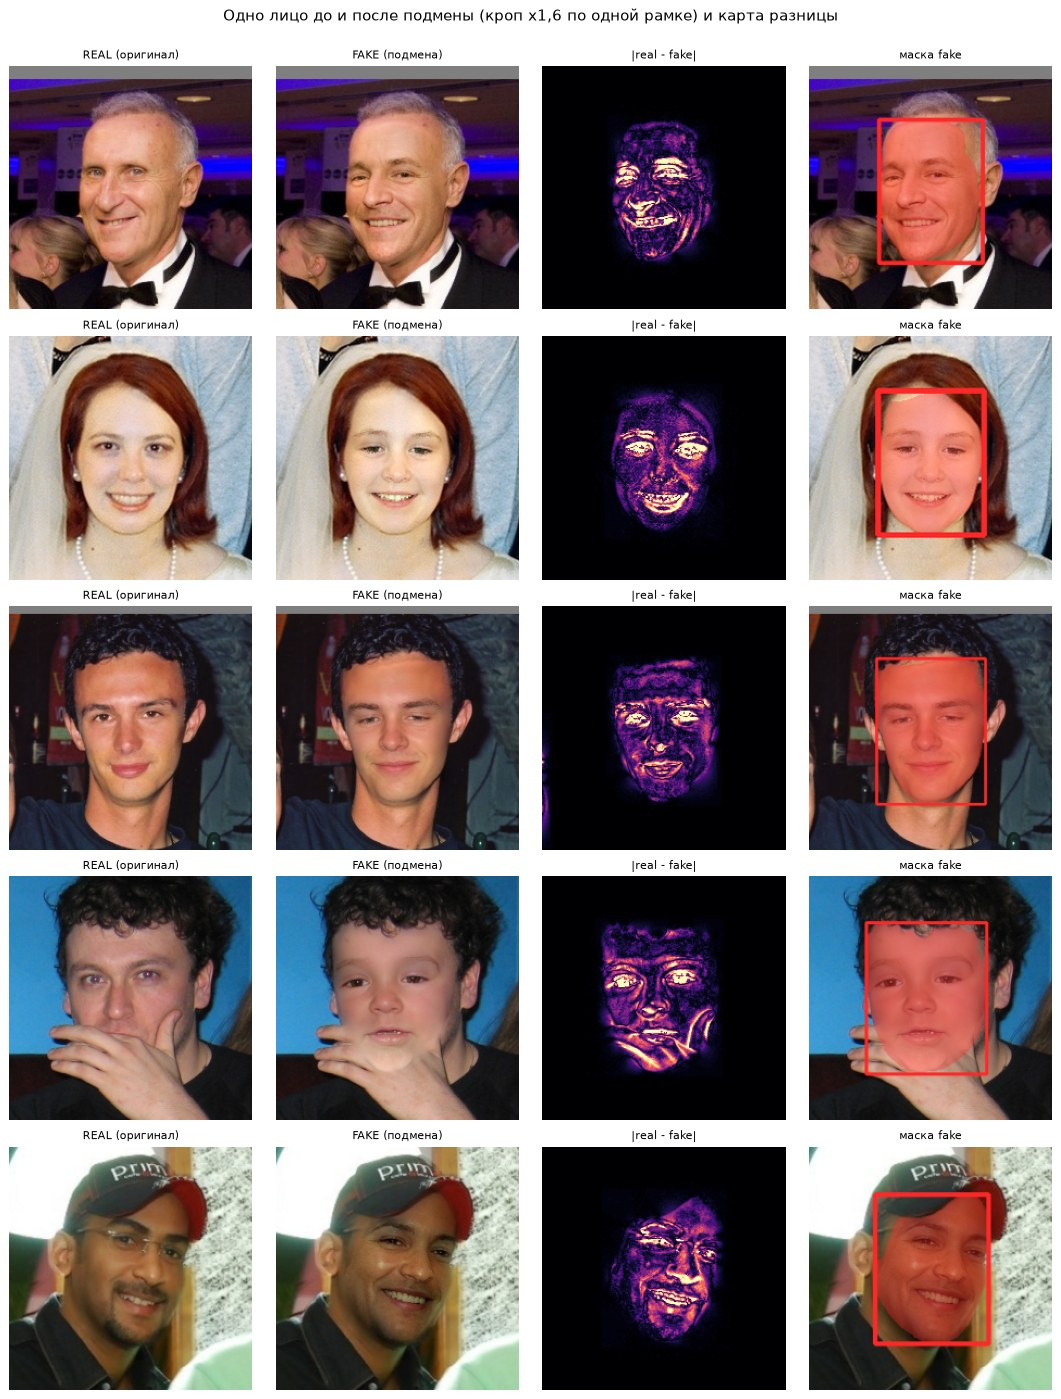

In [28]:
pick = faces[faces["face_src_id"].isin(mixed_src) & (faces["face_side_px"] >= 96)]["face_src_id"].drop_duplicates().pipe(sample_rows, 5, random_state=SEED + 3)
fig, axes = plt.subplots(len(pick), 4, figsize=(12, 3.1 * len(pick)))
for row_axes, src in zip(axes, pick):
    g = faces[faces["face_src_id"] == src]
    r_real, r_fake = g[g["label"] == "real"].iloc[0], g[g["label"] == "fake"].iloc[0]
    box = (r_real["x"], r_real["y"], r_real["w"], r_real["h"])
    a, b = crop_of(r_real, 1.6, 224, box), crop_of(r_fake, 1.6, 224, box)
    diff = np.abs(a.astype(int) - b.astype(int)).sum(axis=2)
    seg = crop_face(draw_faces(frame_img(r_fake["split"], r_fake["image_id"]), g.loc[[r_fake.name]], letters=False), *box, scale=1.6, out=224)
    for ax, im, t in zip(row_axes, [a, b, diff, seg], ["REAL (оригинал)", "FAKE (подмена)", "|real - fake|", "маска fake"]):
        ax.imshow(im, cmap="magma" if im.ndim == 2 else None, vmin=0, vmax=120 if im.ndim == 2 else None)
        ax.set_title(t, fontsize=9); ax.axis("off")
fig.suptitle("Одно лицо до и после подмены (кроп x1,6 по одной рамке) и карта разницы", y=1.0)
plt.tight_layout(); plt.show()

**Что видно.** Карта разницы светится **только внутри маски**: всё остальное в кадре совпадает. Генератор сохраняет
позу, причёску, освещение и фон, но меняет черты лица, причём сильно: может сменить возраст и даже пол
(мужчина становится ребёнком, женщина девочкой), снять очки. Цвет кожи подгоняется под исходный. Видны
и грубые артефакты: если лицо закрыто рукой, рука внутри маски размывается.

## 4.3 Шов вклейки крупно и высокие частоты

Слева контур маски на кропе, затем участок левой границы маски в 4 раза крупнее, затем
**высокочастотный остаток** = кроп минус его размытая копия: остаются только мелкие детали и шум.
Если вклейка оставила шов или другую текстуру кожи, это лучше видно на остатке, чем на фото.

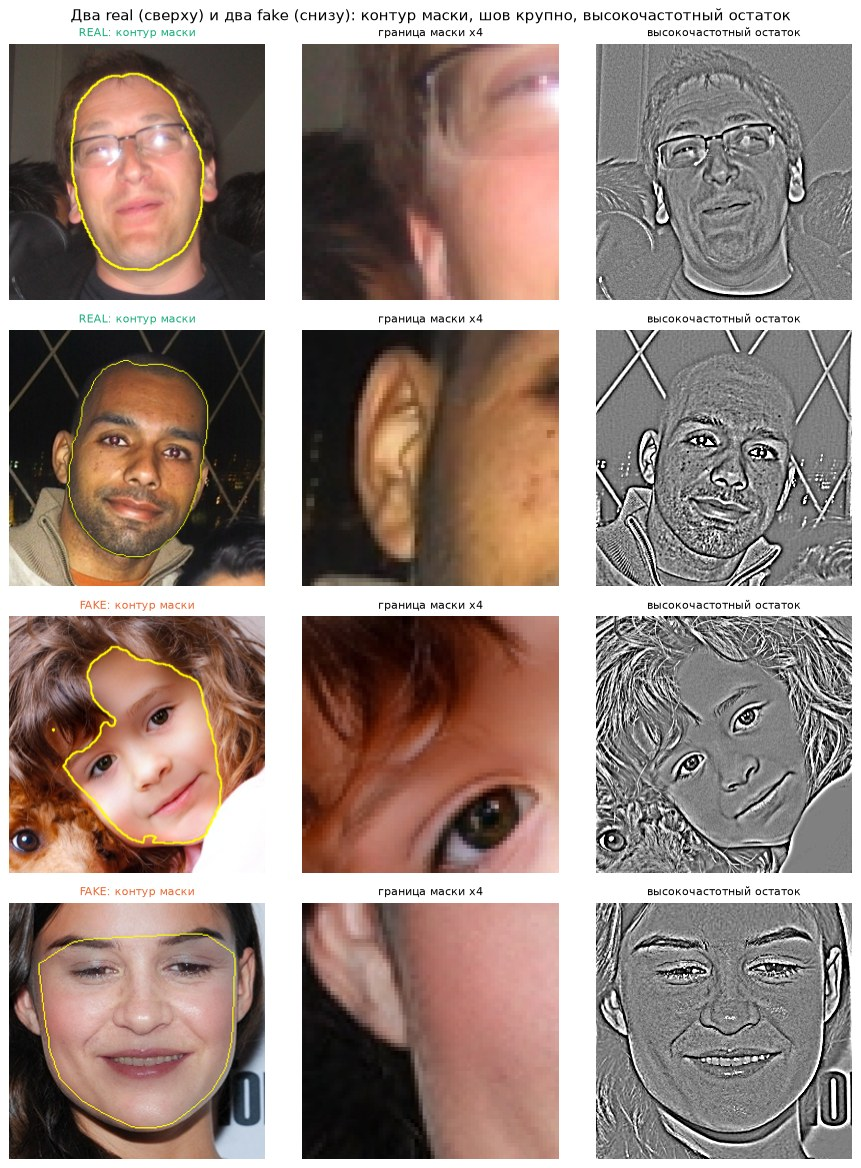

In [29]:
def highpass(img, sigma=2.0):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    return g - cv2.GaussianBlur(g, (0, 0), sigma)

# берём лица >= 160 px, у которых кроп x1,3 целиком внутри кадра (иначе увеличение попадёт на серую подложку)
x0, y0, side = square_box(faces["x"], faces["y"], faces["w"], faces["h"], 1.3)
inside = (x0 >= 0) & (y0 >= 0) & (x0 + side <= faces["width"]) & (y0 + side <= faces["height"])
pool = faces[inside & (faces["face_side_px"] >= 160) & (faces["split"] == "Train")]
rows = [r for lab in ["real", "fake"] for _, r in pool[pool["label"] == lab].pipe(sample_rows, 2, random_state=SEED + 2).iterrows()]
fig, axes = plt.subplots(len(rows), 3, figsize=(10, 3.3 * len(rows)))
for row_axes, r in zip(axes, rows):
    img = frame_img(r["split"], r["image_id"])
    m = polygon_mask(r["segmentation"], *img.shape[:2])
    contour = img.copy()
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(contour, cnts, -1, (255, 255, 0), max(1, int(r["face_side_px"] / 120)))
    crop = crop_face(img, r["x"], r["y"], r["w"], r["h"], 1.3, 256)
    mcrop = crop_face(m * 255, r["x"], r["y"], r["w"], r["h"], 1.3, 256)
    inside = np.where(mcrop[128] > 127)[0]
    bx = min(max(int(inside[0]) if len(inside) else 48, 32), 224)       # левая граница маски на средней строке
    zoom = cv2.resize(crop[96:160, bx - 32:bx + 32], (256, 256), interpolation=cv2.INTER_NEAREST)
    for ax, im, t in zip(row_axes, [crop_face(contour, r["x"], r["y"], r["w"], r["h"], 1.3, 256), zoom, highpass(crop)],
                         [f"{r['label'].upper()}: контур маски", "граница маски x4", "высокочастотный остаток"]):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=-20 if im.ndim == 2 else None, vmax=20 if im.ndim == 2 else None)
        ax.set_title(t, fontsize=9, color=PLOT_COLOR[r["label"]] if "контур" in t else "black"); ax.axis("off")
fig.suptitle("Два real (сверху) и два fake (снизу): контур маски, шов крупно, высокочастотный остаток")
plt.tight_layout(); plt.show()

**Что видно.** На обычной картинке шов почти не виден, пуассоновское смешивание хорошо прячет границу. В
высокочастотном остатке у fake иногда заметна смена текстуры на границе маски и более «плоская»
текстура внутри. Это гипотеза: числа по высоким частотам
есть в шаге 7.5.

## 4.4 Крайние случаи

Маленькие, тёмные, светлые, повёрнутые в профиль, размытые лица. Для выбора примеров используем
атрибуты, которые подробно объясняются в шаге 5 (здесь они нужны только чтобы найти «хвосты»).

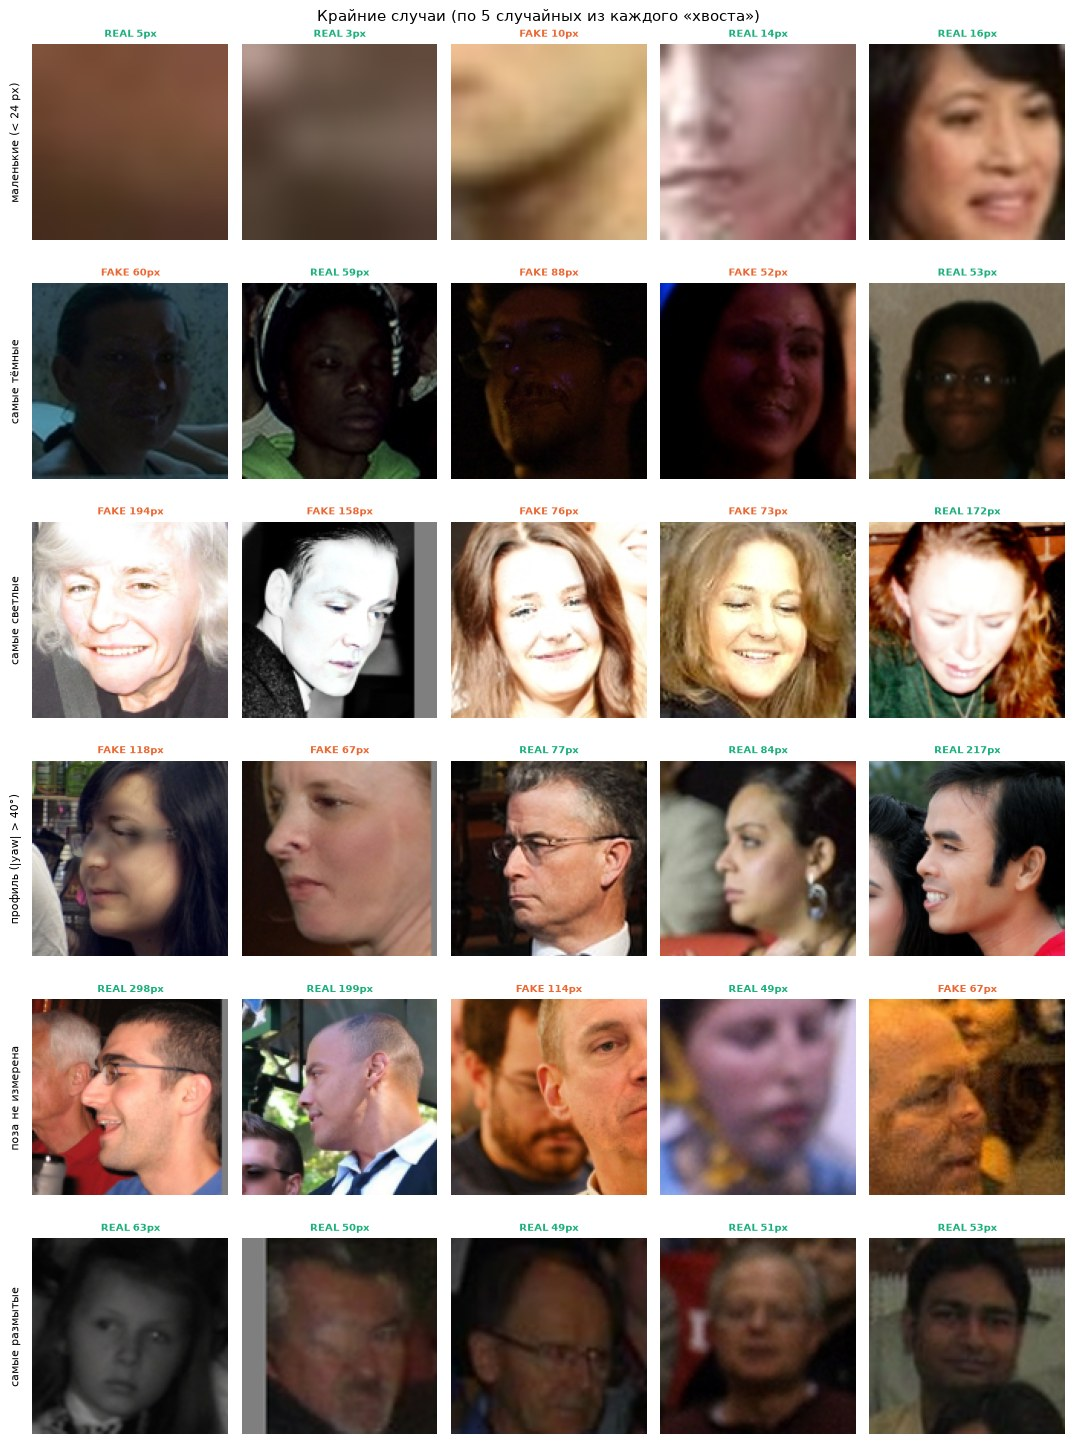

In [30]:
tmp = faces.merge(attr_raw, on=["split", "face_id"], how="left")
tmp["abs_yaw"] = tmp["yaw"].abs()
b48 = tmp[tmp["face_side_px"] >= 48]
groups = [("маленькие (< 24 px)", tmp[tmp["face_side_px"] < 24].pipe(sample_rows, 5, random_state=SEED)),
          ("самые тёмные", b48.nsmallest(200, "face_L_mean").pipe(sample_rows, 5, random_state=SEED)),
          ("самые светлые", b48.nlargest(200, "face_L_mean").pipe(sample_rows, 5, random_state=SEED)),
          ("профиль (|yaw| > 40°)", b48[b48["abs_yaw"] > 40].pipe(sample_rows, 5, random_state=SEED)),
          ("поза не измерена", b48[~b48["pose_ok"].fillna(False).astype(bool)].pipe(sample_rows, 5, random_state=SEED)),
          ("самые размытые", b48.nsmallest(200, "sharp_lap").pipe(sample_rows, 5, random_state=SEED))]
fig, axes = plt.subplots(len(groups), 5, figsize=(12, 2.75 * len(groups)))
for row_axes, (name, sel) in zip(axes, groups):
    for ax, (_, r) in zip(row_axes, sel.iterrows()):
        ax.imshow(crop_of(r, out=128)); ax.axis("off")
        ax.set_title(f"{r['label'].upper()} {r['face_side_px']:.0f}px", fontsize=8, color=PLOT_COLOR[r["label"]], fontweight="bold")
    row_axes[0].text(-8, 64, name, rotation=90, ha="right", va="center", fontsize=9)
fig.suptitle("Крайние случаи (по 5 случайных из каждого «хвоста»)")
plt.tight_layout(); plt.show()

**Что видно.** Лица < 24 px это пятна без деталей. На самых тёмных лицах почти ничего не видно, на самых светлых
пересвечена кожа. Профили и лица без позы это сильные повороты, закрытые лица и размытие. Самые
размытые лица это мелкие лица, растянутые до кропа, и смаз. Во всех этих «хвостах» есть и real, и fake,
и именно на них модель будет ошибаться чаще всего.

---
# 5. Описываем каждое лицо числами: поза, свет, резкость

**Где мы сейчас.** Шаги 1–4 опирались на разметку (рамки, метки) и на осмотр глазами. Но на вопросы об
условиях съёмки («под каким углом лица?», «какое освещение?») глазами для 216 тыс. лиц не ответить. И скрытые
различия real и fake (например, «подделки чуть светлее») глазами тоже не увидеть.

**Что делаем.** Заполняем на каждое лицо «анкету» из чисел: как повёрнута голова, насколько лицо
светлое, насколько чёткое. Получается обычная таблица (строка = лицо), и к ней можно применить
стандартный EDA: типичные значения, пропуски, сравнение real и fake.

**Важно:** модели эту анкету **не даём**, она смотрит только на картинку. Анкета нужна нам, чтобы
проверить данные.

| Что в анкете | Что значит по-простому | Чем мерили | Где прибор ошибается |
| --- | --- | --- | --- |
| `yaw`, `pitch`, `roll` | поворот головы: влево-вправо, вверх-вниз, наклон к плечу (градусы) | MediaPipe: программа Google, ставит на лицо 478 точек и по ним считает поворот | на профилях и лицах < 40 px часто не находит лицо |
| `yn_yaw_proxy` | грубая оценка поворота: насколько нос смещён от середины между глазами (0 = смотрит прямо) | детектор лиц YuNet (шаг 3.6) | грубая шкала; нужна, чтобы перепроверить MediaPipe |
| `face_L_mean` | насколько лицо светлое: от 0 (чёрное) до 100 (белое) | по пикселям внутри маски лица | маски real и fake чуть различаются по форме (3.4) |
| `lr_asym`, `bg_L_mean`, `overexp`, `underexp` | боковой свет (левая половина лица светлее правой?), светлота фона, доля засвеченных и чёрных пикселей | то же | то же |
| `ita` | светлота кожи по шкале дерматологов (угол в градусах) | по участкам щёк | зависит от освещения снимка, а не только от кожи |
| `sharp_lap`, `noise_est`, `hf_ratio` | чёткость краёв; зернистость (шум); доля мелкой ряби и деталей | по кропу лица 128×128 | все три сильно зависят от размера лица |

Если прибор не смог измерить лицо, пишем **«не измерено»**, а не подставляем среднее: иначе ошибка
прибора спряталась бы в данных.

In [31]:
df = faces.drop(columns=["segmentation"]).merge(attr_raw, on=["split", "face_id"], how="left", validate="one_to_one")
df = df.merge(frames[["split", "image_id", "bytes", "jpeg_q"]], on=["split", "image_id"], how="left")
df["pose_ok"] = df["pose_ok"].fillna(False).astype(bool)
df["abs_yaw"] = df["yaw"].abs()
df["pose_bin"] = pd.cut(df["abs_yaw"], [0, 15, 45, 90.01], labels=["анфас <15°", "полупрофиль 15-45°", "профиль >45°"], right=False)
df["pose_bin"] = df["pose_bin"].cat.add_categories("не измерено").fillna("не измерено")
df["y_fake"] = (df["label"] == "fake").astype(int)
print(f"Таблица лиц: {df.shape[0]:,} строк (лиц) x {df.shape[1]} столбцов")
display(Markdown("**Первые 5 строк таблицы лиц** (строка = одно лицо; что значит каждый столбец, см. обозначения признаков в начале ноутбука)"))
display(df[["split", "label", "face_side_px", "bbox_frac", "frame_type", "yaw", "pitch", "face_L_mean", "lr_asym", "ita", "sharp_lap", "hf_ratio"]].head())

Таблица лиц: 215,929 строк (лиц) x 64 столбцов


**Первые 5 строк таблицы лиц** (строка = одно лицо; что значит каждый столбец, см. обозначения признаков в начале ноутбука)

,split,label,face_side_px,bbox_frac,frame_type,yaw,pitch,face_L_mean,lr_asym,ita,sharp_lap,hf_ratio
0,Train,fake,132.492,0.020,all_fake,8.755,9.391,34.070,2.610,-39.862,284.363,0.008
1,Train,fake,114.446,0.019,all_fake,12.895,2.581,39.220,2.388,-10.551,352.294,0.014
2,Train,fake,110.928,0.018,all_fake,-6.428,-3.302,58.187,-0.941,37.533,266.487,0.008
3,Train,fake,178.298,0.040,all_fake,-27.095,1.851,54.871,8.446,47.926,145.631,0.006
4,Train,fake,261.981,0.087,all_fake,1.231,-5.329,33.463,-18.638,76.994,348.139,0.009


## 5.1 Можно ли верить углу поворота головы?

**Зачем.** Все выводы о позе (шаг 7) держатся на одном приборе, MediaPipe. Если он врёт, врут и выводы.
Проверка простая: сравниваем его с другим, независимым прибором (YuNet). Если оба правильно меряют
поворот, их показания должны расти вместе.

**Как меряем согласие.** Число ρ Спирмена: от −1 до +1. 1 значит «когда один прибор показывает больший
поворот, второй тоже всегда показывает больший», 0 значит «никакой связи». Плюс смотрим глазами: лица,
разложенные по углу, должны поворачиваться слева направо.

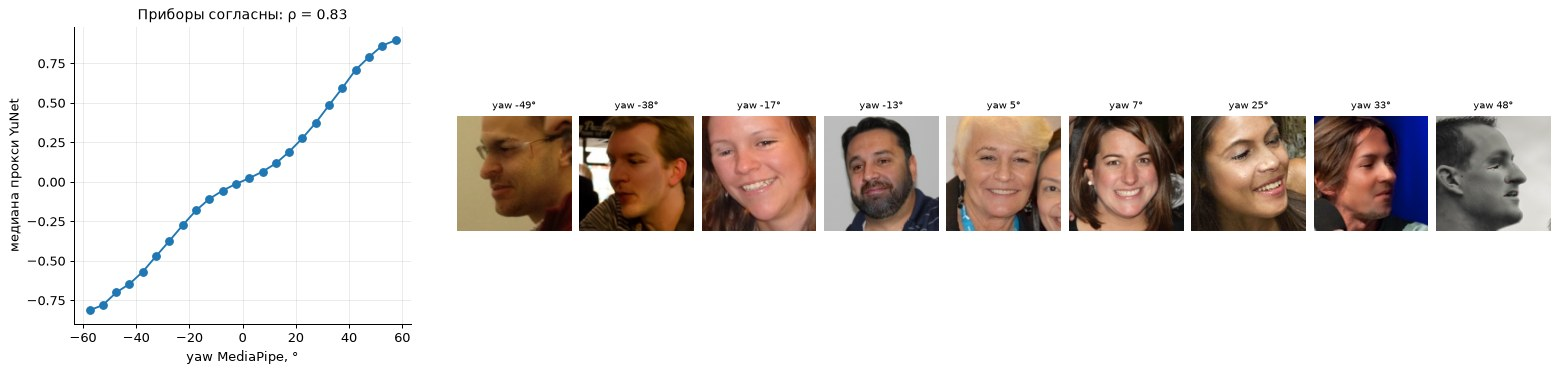

In [32]:
ok = df[df["pose_ok"] & df["yn_ok"].fillna(False).astype(bool)]
rho = spearmanr(ok["yaw"], ok["yn_yaw_proxy"])[0]
fig = plt.figure(figsize=(17, 4.4))
ax0 = fig.add_axes([0.03, 0.12, 0.22, 0.75])
q = ok.groupby(pd.cut(ok["yaw"], np.arange(-60, 61, 5)), observed=True)["yn_yaw_proxy"].median()
ax0.plot([i.mid for i in q.index], q.values, marker="o")
ax0.set_xlabel("yaw MediaPipe, °"); ax0.set_ylabel("медиана прокси YuNet"); ax0.set_title(f"Приборы согласны: ρ = {rho:.2f}")
edges = [-60, -45, -30, -15, -5, 5, 15, 30, 45, 60]
for k in range(len(edges) - 1):
    sel = df[df["pose_ok"] & df["yaw"].between(edges[k], edges[k + 1]) & (df["face_side_px"] >= 80)]
    ax = fig.add_axes([0.28 + k * 0.08, 0.15, 0.075, 0.7]); ax.axis("off")
    if len(sel):
        r = sel.pipe(sample_rows, 1, random_state=SEED).iloc[0]
        ax.imshow(crop_of(r, out=128)); ax.set_title(f"yaw {r['yaw']:.0f}°", fontsize=8)
plt.show()

*Как читать. Слева: по горизонтали угол MediaPipe, по вертикали средний поворот по YuNet для лиц с таким углом; если линия ровно растёт, приборы согласны. Справа: лица, разложенные по углу MediaPipe слева направо.*

**Что видим.** Приборы согласны: ρ = **0,83**, график растёт ровно во всём диапазоне ±60°. На картинках
голова действительно поворачивается: при отрицательном угле к левому краю кадра, при положительном к
правому.

**Что это значит.** Углу MediaPipe можно верить там, где он измерен. Слабое место: углы больше ~50° он
почти не выдаёт, сильно повёрнутые лица у него становятся «не измерено». Это разбираем в 6.1.

In [33]:
# Сохраняем таблицу лиц: её используют раздел 8 и скрипты моделей
df.to_parquet(RESULTS / "attributes.parquet", index=False)

---
# 6. Проверяем саму анкету: типичные значения, пропуски, ошибки

**Где мы сейчас.** Анкета на каждое лицо заполнена (шаг 5). Прежде чем сравнивать по ней real и fake
(шаг 7), нужно убедиться, что она сама в порядке. Это стандартная часть любого EDA, четыре вопроса:
1. Какие значения типичны и есть ли «хвосты» (очень мелкие лица, очень тёмные фото)?
2. Где прибор не смог измерить (пропуски), и случайно ли это?
3. Нет ли невозможных значений (угол 200°) и что за редкие крайние значения (выбросы)?
4. Нет ли размеченных объектов, которые вовсе не лица (6.3), и как признаки связаны между собой (6.4)?

Если это пропустить, сравнение в шаге 7 исказят дыры в данных и редкие крайние значения.

**Как читать таблицу ниже.** Медиана = значение «посередине»: у половины лиц меньше, у половины больше.
1% и 99% = границы, за которые выходит по 1% самых маленьких и самых больших значений. «Скошено» значит,
что большинство значений маленькие, но есть длинный хвост больших (так у размера лица).

,count,mean,std,min,1%,25%,50%,75%,99%,max,пропуски
face_side_px,"215,929",111.943663,71.299084,2.828427,21.246111,62.625873,93.952115,141.017729,364.527091,1429.820268,0.0%
bbox_frac,"215,929",0.023482,0.036081,0.000010,0.000627,0.005426,0.012131,0.027021,0.170062,0.907463,0.0%
abs_yaw,"210,884",12.002913,10.440466,0.000048,0.148844,3.951929,9.115292,17.155243,44.911062,75.834824,2.3%
pitch,"210,884",0.767416,8.158722,-39.544325,-19.270637,-4.405800,0.633528,5.887382,21.044828,41.965753,2.3%
face_L_mean,"215,442",51.222490,13.939970,2.283533,16.484900,42.194804,52.084557,61.003792,80.608296,99.282776,0.2%
lr_asym,"214,862",0.621798,8.181633,-55.200562,-22.581421,-3.338561,0.689114,4.570225,23.759280,57.622070,0.5%
ita,"204,801",13.998556,37.668480,-89.989931,-77.899998,-9.952206,18.346581,41.845805,83.075874,89.995327,5.2%
sharp_lap,"215,797",217.028731,232.618265,0.135010,2.411506,55.391639,150.885332,301.844817,1063.267034,6831.228429,0.1%
noise_est,"215,797",1.022364,0.760188,0.018420,0.269199,0.375984,0.779137,1.496988,3.356048,9.968213,0.1%
hf_ratio,"215,797",0.007075,0.004754,0.000121,0.000925,0.003839,0.006061,0.009098,0.023333,0.161426,0.1%


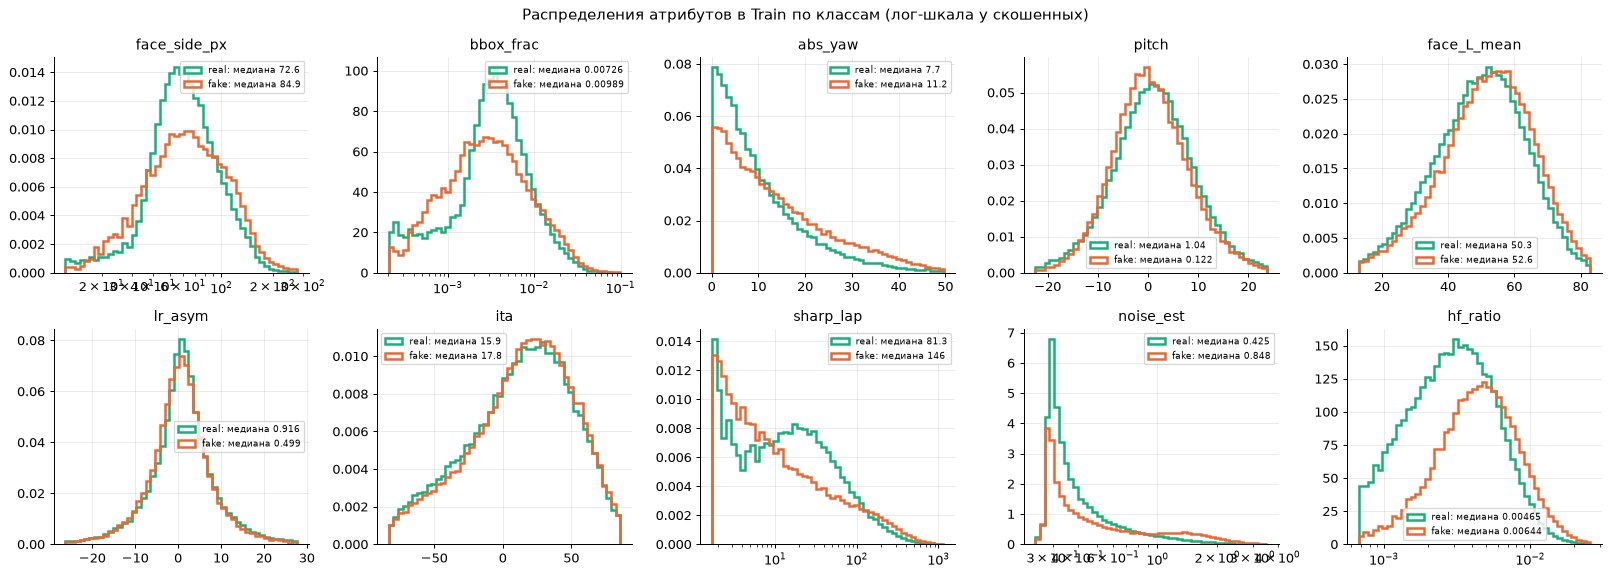

In [34]:
key = ["face_side_px", "bbox_frac", "abs_yaw", "pitch", "face_L_mean", "lr_asym", "ita", "sharp_lap", "noise_est", "hf_ratio"]
desc = df[key].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["пропуски"] = df[key].isna().mean()
display(desc.style.format(precision=3).format({"count": "{:,.0f}", "пропуски": "{:.1%}"}))

plot_cols = [("face_side_px", True), ("bbox_frac", True), ("abs_yaw", False), ("pitch", False), ("face_L_mean", False),
             ("lr_asym", False), ("ita", False), ("sharp_lap", True), ("noise_est", True), ("hf_ratio", True)]
d0 = df[df["split"] == "Train"]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, (c, logx) in zip(axes.ravel(), plot_cols):
    v = d0[c].dropna(); v = v[v > 0] if logx else v
    lo_, hi_ = v.quantile(0.005), v.quantile(0.995)
    bins = np.logspace(np.log10(lo_), np.log10(hi_), 50) if logx else np.linspace(lo_, hi_, 50)
    for lab in ["real", "fake"]:
        x = d0.loc[d0["label"] == lab, c].dropna()
        ax.hist(x, bins=bins, density=True, histtype="step", lw=2, color=PLOT_COLOR[lab], label=f"{lab}: медиана {x.median():.3g}")
    if logx:
        ax.set_xscale("log")
    ax.set_title(c); ax.legend(fontsize=7)
fig.suptitle("Распределения атрибутов в Train по классам (лог-шкала у скошенных)", fontsize=12)
plt.tight_layout(); plt.show()

*Как читать. Таблица: по строкам признаки анкеты; count = сколько лиц измерено, 50% = медиана, 1% и 99% = границы хвостов, «пропуски» = доля не измеренных. Графики: распределение признака у real (зелёный) и fake (оранжевый) в Train; где линии расходятся, признак различается у классов.*

**Что видим.**

- **Размер лица** сильно скошен: у половины лиц сторона меньше 94 px, но разброс от 21 px до 365 px
  (1% и 99%). Лицо занимает в среднем около 1% кадра: это фото с большим фоном, а не портреты.
- **Поворот головы:** у половины лиц меньше 9°, у 99% меньше 45°. Наклон вверх-вниз около 0.
- **Светлота лица:** в середине шкалы (медиана 52 из 100), от 16 до 81: есть и тёмные, и засвеченные.
- **Чёткость, шум, мелкая рябь** скошены: большинство значений небольшие, есть хвост больших.
- **Пропуски:** поза не измерена у 2,3% лиц, светлота кожи (ITA) у 5,2%, остальное меньше 1%.
- Уже на этих графиках видно, что в Train fake крупнее, чаще повёрнуты и с большим шумом. Есть ли тут
  подвох, разбираем в шаге 7.

**Что это значит.** Анкета выглядит правдоподобно, явного мусора нет. Пропусков мало, но у позы их надо
проверить отдельно (6.1): если прибор отказывает не случайно, выбрасывать такие лица опасно.

## 6.1 Почему у некоторых лиц нет позы, и можно ли их просто выбросить

**Зачем.** Поза пустая там, где MediaPipe не нашёл лицо. Выбросить такие лица можно, только если
прибор отказывал **случайно**. Возможны три варианта (так их называют в статистике):
- **случайно** (MCAR): тогда выброс ничего не меняет;
- **из-за другого известного признака** (MAR): например, прибор не видит мелкие лица;
- **из-за самого неизмеренного значения** (MNAR): позы нет *потому что* голова сильно повёрнута. Тогда,
  выбросив пропуски, мы потеряем именно повёрнутые лица и будем думать, что их в данных нет.

**Как проверяем.** (1) Смотрим долю пропусков по размеру лица. (2) Смотрим поворот этих лиц по второму
прибору, YuNet: если они повёрнуты сильнее остальных, это третий вариант. (3) Проверяем, не подсказывает
ли сам пропуск метку. Силу связи «пропуск ↔ метка» меряем числом V Крамера: от 0 (нет связи) до 1;
меньше 0,1 слабая, больше 0,3 сильная.

label,fake,real,V Крамера (пропуск ~ метка),лиц
size_bin,,,,
<32,41.2%,61.2%,0.199,"6,308"
32-64,2.6%,1.7%,0.032,"50,449"
64-128,0.6%,0.7%,0.011,"93,249"
128-256,0.1%,0.6%,0.044,"56,187"
>=256,0.1%,0.8%,0.060,"9,736"


Доля пропусков позы по сплитам и классам: {('Test-Dev', 'fake'): 0.005, ('Test-Dev', 'real'): 0.0126, ('Train', 'fake'): 0.029, ('Train', 'real'): 0.0307, ('Val', 'fake'): 0.0051, ('Val', 'real'): 0.0123}
V Крамера (пропуск ~ метка) по всем лицам: 0.021


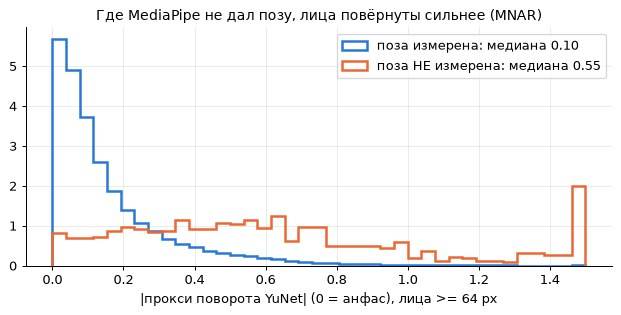

In [35]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(t, correction=False)[0] / (t.values.sum() * (min(t.shape) - 1))) if min(t.shape) > 1 else np.nan

df["pose_missing"] = ~df["pose_ok"]
by_size = df.groupby(["size_bin", "label"], observed=True)["pose_missing"].mean().unstack()
by_size["V Крамера (пропуск ~ метка)"] = [cramers_v(g["pose_missing"], g["label"]) for _, g in df.groupby("size_bin", observed=True)]
by_size["лиц"] = df.groupby("size_bin", observed=True).size()
display(by_size.style.format({"real": "{:.1%}", "fake": "{:.1%}", "V Крамера (пропуск ~ метка)": "{:.3f}", "лиц": "{:,.0f}"}))
print("Доля пропусков позы по сплитам и классам:", df.groupby(["split", "label"])["pose_missing"].mean().round(4).to_dict())
print(f"V Крамера (пропуск ~ метка) по всем лицам: {cramers_v(df['pose_missing'], df['label']):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
sub = df[(df["face_side_px"] >= 64) & df["yn_ok"].fillna(False).astype(bool)]
for miss, col, name in [(False, "#2a78d6", "поза измерена"), (True, "#eb6834", "поза НЕ измерена")]:
    v = sub.loc[sub["pose_missing"] == miss, "yn_yaw_proxy"].abs().clip(upper=1.5)
    ax.hist(v, bins=np.linspace(0, 1.5, 40), density=True, histtype="step", lw=2, color=col, label=f"{name}: медиана {v.median():.2f}")
ax.set_xlabel("|прокси поворота YuNet| (0 = анфас), лица >= 64 px"); ax.legend()
ax.set_title("Где MediaPipe не дал позу, лица повёрнуты сильнее (MNAR)")
plt.tight_layout(); plt.show()

*Как читать. Таблица: доля лиц без позы в каждой группе размера у real и fake, и сила связи «пропуск ↔ метка». График: насколько повёрнуты лица по второму прибору (правее = сильнее поворот) у лиц с позой (синий) и без неё (оранжевый).*

**Что видим.**

- Пропуски почти все у **лиц < 32 px**: там позы нет у 61% real и 41% fake. У лиц 32–64 px всего
  2–3%, у крупных меньше 1%. Это второй вариант: прибор не видит мелкие лица.
- У крупных лиц (≥ 64 px) без позы YuNet показывает поворот в 5 раз больше (0,55 против 0,10): MediaPipe
  отказывает **именно на сильно повёрнутых лицах**. Это третий вариант, самый опасный.
- Пропуск почти не подсказывает метку (V Крамера 0,02), кроме мелких лиц (0,20).

**Что это значит.** Пропуски не случайны. Если их выбросить, из данных исчезнут профили и мелкие лица,
и выводы о позе будут про «удобные» лица.

**Решение.** Пропуски не заполняем (угадывать позу бессмысленно), храним отдельную категорию
«не измерено». В выводах о позе явно пишем, что они про 97,7% лиц, где поза измерена. Мелкие лица
исключаем из обучения (3.5), поэтому связь пропуска с меткой нам не мешает.

## 6.2 Ошибочные значения и выбросы

**Зачем.** Два разных вопроса:
- **Ошибочное значение** невозможно в принципе, как «отрицательный возраст» в анкете: угол больше 90°,
  светлота вне 0…100, полностью однотонное «лицо». Это брак, его убираем.
- **Выброс** возможен, но редок: очень тёмное фото, засветка от вспышки. Это может быть и брак, и
  настоящий трудный случай. Решаем, посмотрев глазами.

**Как ищем выбросы.** Стандартное правило Тьюки: значение считается выбросом, если оно сильно дальше от
«середины» распределения, чем остальные (точнее: дальше 1,5 размаха средней половины данных от её
границ). Сравниваем долю выбросов у real и fake: если у одного класса их больше, это тоже подсказка.

,нарушений
"|yaw|, |pitch| или |roll| > 90°",0
L* лица вне 0..100,0
ITA вне -90..90,0
лицо однотонное (разброс L* < 1),9


,доля выбросов у fake,доля выбросов у real
face_side_px,0.9%,1.1%
sharp_lap,2.1%,2.2%
face_L_mean,0.7%,0.6%
lr_asym,6.2%,7.2%
noise_est,0.0%,0.0%


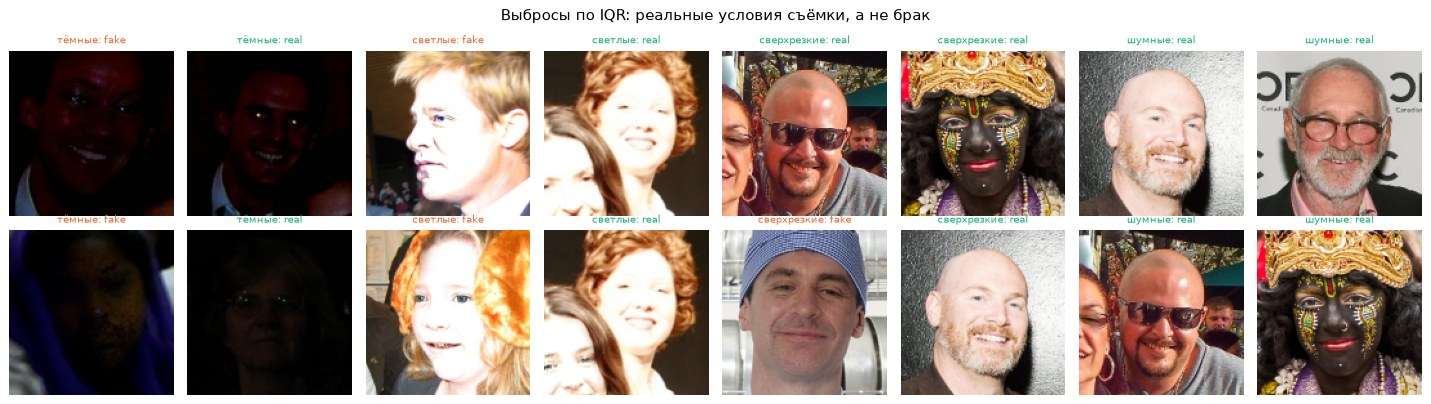

In [36]:
rules = {"|yaw|, |pitch| или |roll| > 90°": (df[["yaw", "pitch", "roll"]].abs() > 90).any(axis=1),
         "L* лица вне 0..100": ~df["face_L_mean"].between(0, 100) & df["face_L_mean"].notna(),
         "ITA вне -90..90": df["ita"].abs() > 90,
         "лицо однотонное (разброс L* < 1)": df["face_L_std"] < 1}
display(pd.Series({k: int(v.sum()) for k, v in rules.items()}, name="нарушений").to_frame())

def iqr_out(x, log=False):
    v = np.log10(x.clip(lower=1e-9)) if log else x
    q1, q3 = v.quantile(0.25), v.quantile(0.75)
    return (v < q1 - 1.5 * (q3 - q1)) | (v > q3 + 1.5 * (q3 - q1))
out = pd.DataFrame({c: df.assign(o=iqr_out(df[c].dropna(), lg).astype(float).reindex(df.index)).groupby("label")["o"].mean()
                    for c, lg in [("face_side_px", True), ("sharp_lap", True), ("face_L_mean", False), ("lr_asym", False), ("noise_est", True)]}).T
out.columns = ["доля выбросов у fake", "доля выбросов у real"]
display(out.style.format("{:.1%}"))

big = df[df["face_side_px"] >= 48]
sel = [("тёмные", big.nsmallest(4, "face_L_mean")), ("светлые", big.nlargest(4, "face_L_mean")),
       ("сверхрезкие", big.nlargest(4, "sharp_lap")), ("шумные", big.nlargest(4, "noise_est"))]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for k, (name, g) in enumerate(sel):
    for m, (_, r) in enumerate(g.iterrows()):
        ax = axes[m // 2, k * 2 + m % 2]
        ax.imshow(crop_of(r, out=128)); ax.axis("off"); ax.set_title(f"{name}: {r['label']}", fontsize=8, color=PLOT_COLOR[r["label"]])
fig.suptitle("Выбросы по IQR: реальные условия съёмки, а не брак")
plt.tight_layout(); plt.show()

*Как читать. Первая таблица: сколько найдено невозможных значений. Вторая: доля выбросов по признаку у fake и real (если доли близки, выбросы не подсказывают метку). Картинки: по 4 самых крайних лица каждого вида.*

**Что видим.** Невозможных значений нет. Однотонных «лиц» 9, все крошечные (5–33 px): это брак, они и
так уходят вместе с лицами < 32 px. Выбросов мало (размер 1%, чёткость 2%), больше только у бокового
света (6–7%: сильный свет сбоку встречается часто). У real и fake доли выбросов одинаковы. На картинках
выбросы выглядят как реальные условия: ночные фото, засветка, вспышка.

**Решение.** Выбросы оставляем: это трудные, но настоящие случаи, на них модель тоже должна работать.

## 6.3 Размеченные «лица», которые не лица

**Зачем.** Ещё один вид брака в разметке: рамка с меткой real или fake стоит на том, что лицом не является
(затылок, рисунок, маска, пятно). Такой объект не относится ни к одному классу, и модель будет учиться на
шуме. Проверяем крупные рамки (от 64 px), где лицо **не нашёл ни один из двух независимых приборов**:
ни детектор лиц YuNet, ни MediaPipe.

Крупных размеченных лиц: 159,172; ни один прибор не нашёл лицо: 49 (0.03%)


label,fake,real
split,,
Train,11,20
Val,2,4
Test-Dev,7,5


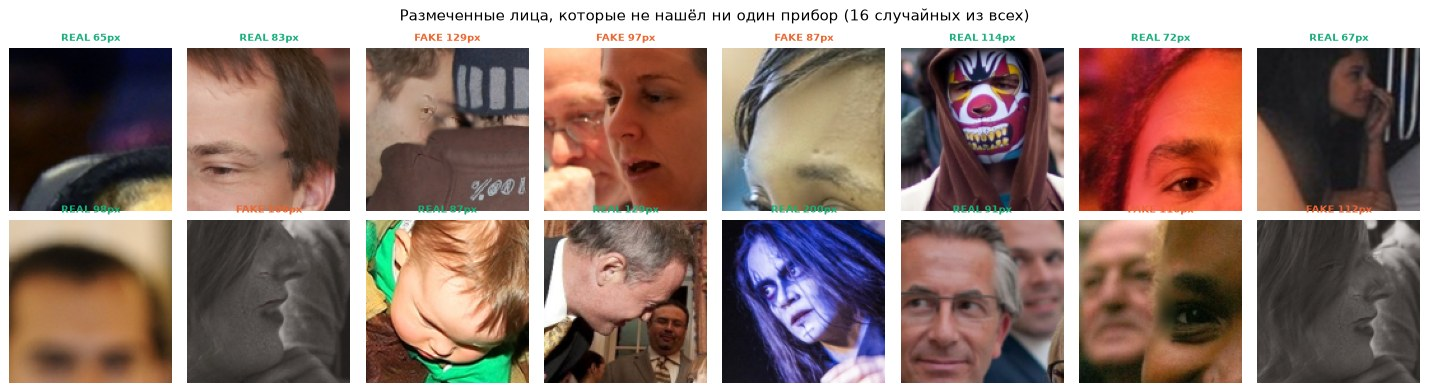

In [37]:
big64 = df[df["face_side_px"] >= 64]
not_face = big64[~big64["yunet_found"] & ~big64["pose_ok"]]
print(f"Крупных размеченных лиц: {len(big64):,}; ни один прибор не нашёл лицо: {len(not_face)} ({len(not_face) / len(big64):.2%})")
display(not_face.groupby(["split", "label"]).size().unstack(fill_value=0).loc[SPLITS])
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, (_, r) in zip(axes.ravel(), not_face.pipe(sample_rows, 16, random_state=SEED).iterrows()):
    ax.imshow(crop_of(r, out=128)); ax.axis("off")
    ax.set_title(f"{r['label'].upper()} {r['face_side_px']:.0f}px", fontsize=8, color=PLOT_COLOR[r["label"]], fontweight="bold")
fig.suptitle("Размеченные лица, которые не нашёл ни один прибор (16 случайных из всех)")
plt.tight_layout(); plt.show()

*Как читать. Число сверху: сколько крупных рамок не распознал ни один прибор. Таблица: сколько их в каждом сплите
и классе. Картинки: 16 случайных таких рамок.*

**Что видим.** Таких рамок всего **49 из 159 тыс. (0,03%)**: 29 real и 20 fake. На картинках почти
все это **настоящие лица в трудных условиях**: обрезаны краем кадра, повёрнуты затылком, закрыты рукой,
в маске или гриме, сильно размыты. Настоящих «не-лиц» (маска, тёмное пятно) единицы.

**Решение.** Это не ошибка разметки, а трудные лица. Отдельно их не убираем: их слишком мало, чтобы
повлиять на обучение. Ошибки разметки, которые действительно мешают, разобраны в шагах 3.2 и 3.7.

## 6.4 Как признаки связаны между собой

**Зачем.** Если два признака почти повторяют друг друга, то различие real и fake в одном из них может
быть просто отражением другого. Например, если зернистость растёт вместе с размером лица, то «у подделок
больше зернистость» может значить лишь «подделки крупнее». Проверяем это двумя способами:
- **таблица корреляций**: для каждой пары признаков число от −1 до +1 (ρ Спирмена). +1 значит «растут
  вместе», −1 «один растёт, другой падает», 0 «не связаны»;
- **pairplot**: попарные графики пяти главных признаков для 1 500 real и 1 500 fake из Train.

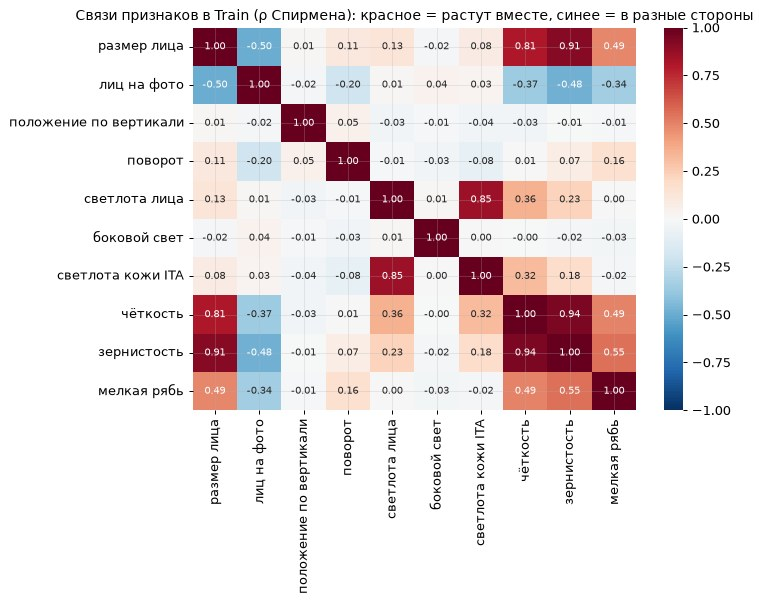

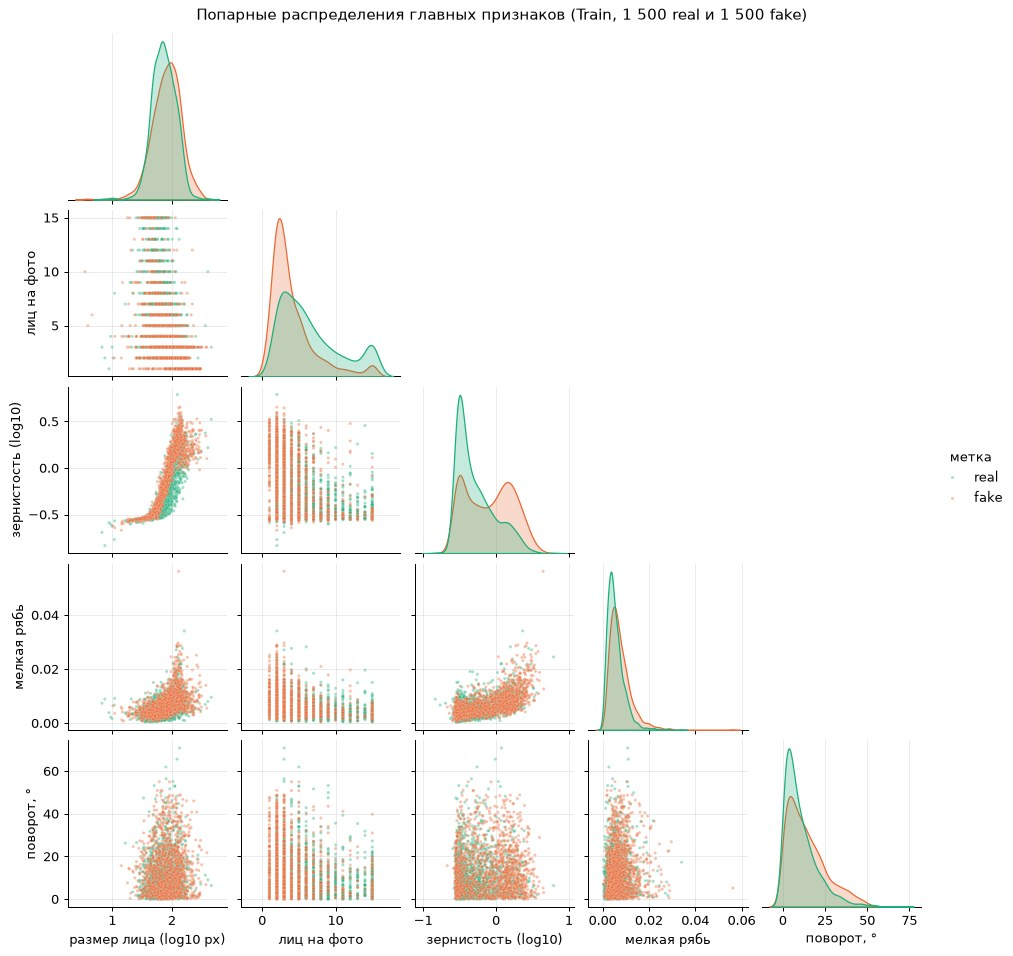

In [38]:
import seaborn as sns
FEAT = {"face_side_px": "размер лица", "n_faces_in_frame": "лиц на фото", "cy": "положение по вертикали", "abs_yaw": "поворот",
        "face_L_mean": "светлота лица", "lr_asym": "боковой свет", "ita": "светлота кожи ITA",
        "sharp_lap": "чёткость", "noise_est": "зернистость", "hf_ratio": "мелкая рябь"}
train = df[df["split"] == "Train"]
corr = train[list(FEAT)].corr(method="spearman")
corr.index = corr.columns = list(FEAT.values())
fig, ax = plt.subplots(figsize=(8.5, 6.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Связи признаков в Train (ρ Спирмена): красное = растут вместе, синее = в разные стороны")
plt.tight_layout(); plt.show()

sample = pd.concat([train[train["label"] == lab].pipe(sample_rows, 1500, random_state=SEED) for lab in ["real", "fake"]])
pp = pd.DataFrame({"размер лица (log10 px)": np.log10(sample["face_side_px"]), "лиц на фото": sample["n_faces_in_frame"].clip(upper=15),
                   "зернистость (log10)": np.log10(sample["noise_est"].clip(lower=1e-3)), "мелкая рябь": sample["hf_ratio"],
                   "поворот, °": sample["abs_yaw"], "метка": sample["label"]})
g = sns.pairplot(pp, hue="метка", palette=PLOT_COLOR, plot_kws={"s": 6, "alpha": 0.4}, corner=True, height=2.1)
g.figure.suptitle("Попарные распределения главных признаков (Train, 1 500 real и 1 500 fake)", y=1.01)
plt.show()

*Как читать. Таблица: число в клетке = связь двух признаков. Pairplot: на диагонали распределение
признака у real и fake, ниже диагонали точки для каждой пары признаков; если облака двух цветов
расходятся, по этой паре классы различаются.*

**Что видим.**
- **Чёткость, зернистость и мелкая рябь почти повторяют размер лица:** связь 0,81 / 0,91 / 0,49, а
  чёткость с зернистостью 0,94. Крупное лицо уменьшают до 128 px, и все мелкие детали «сжимаются»
  в кроп, поэтому он выглядит зернистее и резче.
- **Светлота лица и ITA почти одно и то же** (0,85): ITA меряет в первую очередь свет (как в 7.4).
- **Чем больше лиц на фото, тем они мельче** (−0,50): групповые снимки сделаны издалека.
- Поворот, положение и боковой свет почти ни с чем не связаны.
- На pairplot главное: **при одинаковом размере лица зернистость у подделок выше** (оранжевая полоса идёт
  над зелёной). То есть различие в зернистости не сводится к размеру.

**Что это значит.** Зернистость и чёткость нельзя сравнивать у real и fake «в лоб»: сначала нужно
учесть размер лица (поэтому в 7.5 они показаны ещё и внутри групп размера). После такой поправки у
подделок всё равно больше зернистости, это похоже на след генератора; окончательно проверим в парном
анализе по одному окну.

**Решение.** Признаки, связанные с размером лица, сравниваем только внутри групп размера. В отчётах о
качестве модели размер лица учитываем всегда.

---
# 7. Условия съёмки: лицо и фон, угол, анфас, освещение

**Где мы сейчас.** Анкета на каждое лицо готова и проверена (шаги 5–6). Теперь с её помощью разбираем
четыре условия съёмки, которые сильнее всего влияют на поиск подделки:
- **лицо и фон** (7.1): насколько крупно лицо и сколько вокруг него фона. От этого зависит, сколько деталей
  подделки вообще видно;
- **угол поворота головы** (7.2) и **только ли анфас в данных** (7.3): генератор хуже рисует повёрнутые
  лица, а модель, не видевшая профилей, на них не работает;
- **освещение** (7.4): в тени и на бликах следы подделки прячутся.

Затем (7.5) проверяем все признаки анкеты сразу, а в 7.6 собираем выводы.

Каждое условие проверяем в двух смыслах:
- **Что вообще есть в данных?** Если в обучении нет, например, профилей, модель на профилях работать не
  будет. Это определяет, где модели можно верить.
- **Различается ли это у real и fake?** Если, например, все подделки светлее настоящих, модель может
  научиться «светлое = подделка» вместо того, чтобы искать саму подделку. Такая лазейка и называется
  **шорткат**: модель покажет отличный результат на нашем датасете и провалится в жизни.

### Как измеряем «различается ли у real и fake»

Одно число, **AUC признака**. Представим, что мы угадываем real/fake, глядя только на один признак,
например только на размер лица. AUC показывает, насколько хорошо это получилось бы:
- **0,5** = как подбрасывание монетки: по признаку метку не угадать. Это хорошо, лазейки нет.
- **1** = угадываем безошибочно: готовый шорткат, очень плохо.

Неважно, в какую сторону различие (модель выучит и «светлее = fake», и «темнее = fake»), поэтому берём
симметричный вариант от 0,5 до 1. Наша шкала: **до 0,55 не страшно, 0,55–0,65 слабая подсказка,
0,65–0,75 заметная, больше 0,75 сильная**.

В таблицах есть ещё два столбца той же природы: Cliff δ (то же различие со знаком, от −1 до +1) и KS D
(насколько различается форма распределений, от 0 до 1). Для выводов достаточно AUC. Рядом с AUC даём интервал: в каких пределах было бы число, если бы нам попались другие
фото. Считаем его, много раз вытягивая случайные **целые сцены** (лица одного фото зависят друг от
друга, поэтому тянем их вместе).

In [39]:
def auc_fake_gt_real(x, y):
    fake, real = x[y == 1], x[y == 0]
    return mannwhitneyu(fake, real, alternative="two-sided").statistic / (len(fake) * len(real))

def effect_table(data, col, by=None):
    rows = []
    for key, g in (data.groupby(by, observed=True) if by else [("все", data)]):
        g = g[[col, "y_fake"]].dropna()
        if g["y_fake"].nunique() < 2:
            continue
        a = auc_fake_gt_real(g[col].to_numpy(), g["y_fake"].to_numpy())
        f, r = g.loc[g["y_fake"] == 1, col], g.loc[g["y_fake"] == 0, col]
        rows.append({"группа": key, "n real": len(r), "n fake": len(f), "медиана real": r.median(), "медиана fake": f.median(),
                     "AUC sym": max(a, 1 - a), "Cliff δ": 2 * a - 1, "KS D": ks_2samp(f, r).statistic})
    return pd.DataFrame(rows)

def scene_bootstrap_auc(data, col, n_boot=100):
    # 95% интервал AUC: пересэмплируем целые сцены; строки отсортированы по сцене, сцену задают начало и длина блока
    g = data[[col, "y_fake", "scene_id"]].dropna().sort_values("scene_id")
    x, y = g[col].to_numpy(), g["y_fake"].to_numpy()
    _, starts, lengths = np.unique(g["scene_id"].to_numpy(), return_index=True, return_counts=True)
    r, vals = np.random.default_rng(SEED), []
    for _ in range(n_boot):
        pick = r.integers(0, len(starts), len(starts))
        ln = lengths[pick]
        idx = np.repeat(starts[pick], ln) + np.arange(ln.sum()) - np.repeat(np.cumsum(ln) - ln, ln)
        a = auc_fake_gt_real(x[idx], y[idx]); vals.append(max(a, 1 - a))
    return np.percentile(vals, [2.5, 97.5])

def fmt_effects(t):
    return t.style.format({"n real": "{:,.0f}", "n fake": "{:,.0f}", "медиана real": "{:.4g}", "медиана fake": "{:.4g}",
                           "AUC sym": "{:.3f}", "Cliff δ": "{:+.3f}", "KS D": "{:.3f}"}).background_gradient(subset=["AUC sym"], cmap="Oranges", vmin=0.5, vmax=0.8)

## 7.1 Лицо и фон

**О чём речь.** Насколько крупно лицо на фото и сколько вокруг него фона. Меряем двумя числами: **доля
кадра под лицом** (`bbox_frac`, от 0 до 1) и **размер лица в пикселях** (`face_side_px`). Все кадры
примерно 1024 px, поэтому эти два числа почти одно и то же.

**Зачем.** На крупном лице видны поры, шов вклейки, мелкие артефакты генератора; на лице в 30 px их не
разглядеть ни человеку, ни модели. Поэтому размер лица определяет, где модели вообще можно верить. А если
подделки в среднем крупнее настоящих, модель может угадывать по размеру, а не по подделке.

### (а) Что есть в данных

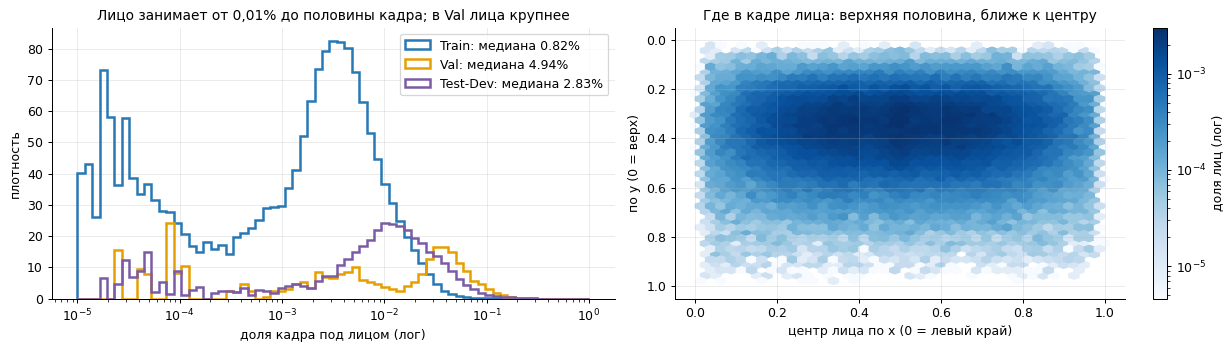

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.logspace(-5, 0, 70)
for s in SPLITS:
    v = df.loc[df["split"] == s, "bbox_frac"]
    axes[0].hist(v, bins=bins, density=True, histtype="step", lw=2, color=SPLIT_COLOR[s], label=f"{s}: медиана {v.median():.2%}")
axes[0].set_ylabel("плотность"); axes[0].set_xscale("log"); axes[0].set_xlabel("доля кадра под лицом (лог)"); axes[0].legend()
axes[0].set_title("Лицо занимает от 0,01% до половины кадра; в Val лица крупнее")
hb = axes[1].hexbin(df["cx"], df["cy"], gridsize=40, cmap="Blues", bins="log", extent=(0, 1, 0, 1))
hb.set_array(hb.get_array() / hb.get_array().sum()); hb.autoscale()
axes[1].invert_yaxis(); axes[1].set_xlabel("центр лица по x (0 = левый край)"); axes[1].set_ylabel("по y (0 = верх)")
axes[1].set_title("Где в кадре лица: верхняя половина, ближе к центру"); plt.colorbar(hb, ax=axes[1], label="доля лиц (лог)")
plt.tight_layout(); plt.show()

### (б) Различается ли у real и fake: ловушка «парадокс Симпсона»

**Что знаем.** В шаге 1.5 fake в Train оказались крупнее real. Вопрос: это подмена делает лицо крупнее,
или просто подделки чаще брали из фото, где лица крупные?

**Как проверяем.** Сравниваем на трёх уровнях, от грубого к точному:
1. весь сплит;
2. только смешанные кадры (на фото есть и real, и fake);
3. внутри одного фото: размер fake ÷ размер real на том же снимке.

Если на точном уровне различие пропадает или меняет знак, общее различие создано тем, **из каких фото**
взяты лица, а не подменой. Это и называется **парадокс Симпсона**: общий вывод переворачивается, если
смотреть внутри групп.

In [41]:
display(Markdown("**Сторона лица real vs fake: весь сплит**")); display(fmt_effects(effect_table(df, "face_side_px", by="split")))
display(Markdown("**Только смешанные кадры**")); display(fmt_effects(effect_table(df[df["frame_type"] == "mixed"], "face_side_px", by="split")))
per_frame = df[df["frame_type"] == "mixed"].groupby(["split", "image_id", "label"])["face_side_px"].mean().unstack()
per_frame["ratio"] = per_frame["fake"] / per_frame["real"]
pr = per_frame.groupby("split")["ratio"].agg(["median", lambda r: (r < 1).mean(), "size"]).loc[SPLITS]
pr.columns = ["медиана отношения fake / real на одном кадре", "доля кадров, где fake мельче", "смешанных кадров"]
display(Markdown("**Внутри одного кадра**")); display(pr.style.format({pr.columns[0]: "{:.3f}", pr.columns[1]: "{:.1%}", pr.columns[2]: "{:,.0f}"}))
rows = []
for s in SPLITS:
    g = df[df["split"] == s]
    a = auc_fake_gt_real(g["face_side_px"].to_numpy(), g["y_fake"].to_numpy())
    lo_, hi_ = scene_bootstrap_auc(g, "face_side_px")
    rows.append({"сплит": s, "AUC sym размера лица": max(a, 1 - a), "95% ДИ (бутстрэп по сценам)": f"[{lo_:.3f}; {hi_:.3f}]"})
display(pd.DataFrame(rows).style.format({"AUC sym размера лица": "{:.3f}"}))

**Сторона лица real vs fake: весь сплит**

,группа,n real,n fake,медиана real,медиана fake,AUC sym,Cliff δ,KS D
0,Test-Dev,"21,048","28,670",128.3,155.7,0.607,+0.214,0.170
1,Train,"85,006","65,860",72.56,84.91,0.573,+0.146,0.135
2,Val,"4,782","10,563",190.9,191.8,0.512,+0.023,0.110


**Только смешанные кадры**

,группа,n real,n fake,медиана real,медиана fake,AUC sym,Cliff δ,KS D
0,Test-Dev,"20,959","16,782",128.4,128.8,0.511,-0.022,0.038
1,Train,"83,981","47,501",72.66,74.7,0.506,+0.011,0.042
2,Val,"4,758","4,381",191.2,171,0.585,-0.170,0.156


**Внутри одного кадра**

,медиана отношения fake / real на одном кадре,"доля кадров, где fake мельче",смешанных кадров
split,,,
Train,0.866,70.7%,"32,615"
Val,0.835,73.8%,"4,204"
Test-Dev,0.872,70.2%,"12,865"


,сплит,AUC sym размера лица,95% ДИ (бутстрэп по сценам)
0,Train,0.573,[0.570; 0.577]
1,Val,0.512,[0.500; 0.526]
2,Test-Dev,0.607,[0.602; 0.613]


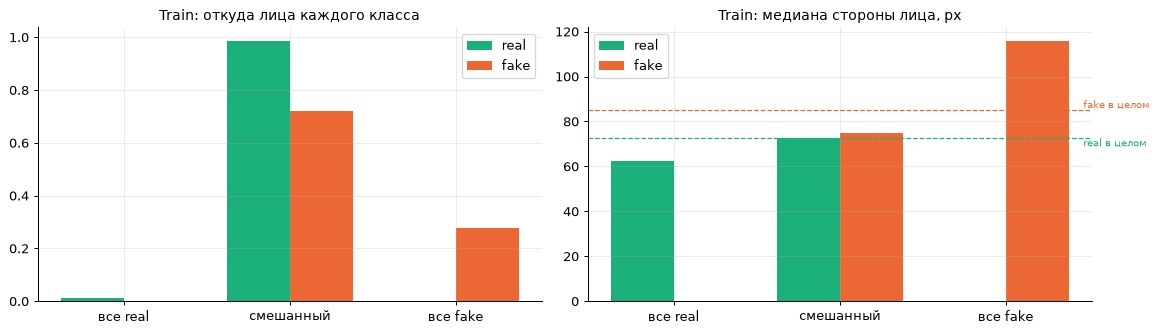

In [42]:
# Откуда берётся парадокс: состав. Слева: из каких кадров лица каждого класса; справа: размер лиц в кадрах каждого типа
ct = df[df["split"] == "Train"].groupby(["label", "frame_type"]).agg(n=("face_id", "size"), med=("face_side_px", "median")).reset_index()
ct["share"] = ct["n"] / ct.groupby("label")["n"].transform("sum")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, val, title in [(axes[0], "share", "Train: откуда лица каждого класса"), (axes[1], "med", "Train: медиана стороны лица, px")]:
    for j, lab in enumerate(["real", "fake"]):
        c = ct[ct["label"] == lab].set_index("frame_type").reindex(["all_real", "mixed", "all_fake"])
        ax.bar(np.arange(3) + (j - 0.5) * 0.38, c[val], 0.38, color=PLOT_COLOR[lab], label=lab)
    ax.set_xticks(range(3), ["все real", "смешанный", "все fake"]); ax.set_title(title); ax.legend()
overall = df[df["split"] == "Train"].groupby("label")["face_side_px"].median()
for lab in ["real", "fake"]:
    axes[1].axhline(overall[lab], color=PLOT_COLOR[lab], ls="--", lw=1)
axes[1].text(2.45, overall["fake"], " fake в целом", color=PLOT_COLOR["fake"], fontsize=8, va="bottom")
axes[1].text(2.45, overall["real"], " real в целом", color=PLOT_COLOR["real"], fontsize=8, va="top")
plt.tight_layout(); plt.show()

*Как читать графики. Слева: распределение доли кадра под лицом в каждом сплите (шкала логарифмическая,
правее = крупнее лицо). Справа: где в кадре центры лиц, темнее = больше лиц. Таблицы ниже: медианы
размера у real и fake и AUC (оранжевее = сильнее подсказывает метку). График состава: слева, из каких
фото приходят лица каждого класса, справа, какого размера лица в фото каждого типа.*

**Что видим. Что есть в данных.** Лицо занимает от сотых долей процента до половины кадра. У половины
лиц меньше 0,8% кадра в Train, 2,8% в Test-Dev, 4,9% в Val. Лица в основном в верхней половине кадра,
ближе к центру. **В Train в основном мелкие лица на большом фоне, в Val и Test-Dev лица крупнее.**

**Различается ли у real и fake.**
- Весь сплит: fake крупнее, AUC размера 0,573 в Train и 0,607 в Test-Dev (слабая подсказка), в Val 0,512
  (нет).
- Только смешанные кадры: различие **исчезает** (AUC 0,506 Train, 0,511 Test-Dev), а в Val fake даже
  **мельче**.
- На одном и том же фото fake мельче соседа-real в 70–74% кадров (отношение 0,83–0,87).
- Почему так, видно на графике: 28% fake в Train взяты из фото «все fake», где обычно 2 крупных лица, а
  real почти все из групповых фото с мелкими лицами.

**Что это значит.** «Fake крупнее» объясняется тем, **какие фото брали для подмены**, а не подменой.
А «fake мельче соседа на том же фото» почти целиком объясняется находкой 3.4: рамка разметки у fake
теснее (площадь 0,87). Настоящего различия в размере, похоже, нет.

**Решение.** Кропы режем по детектору лиц (так рамка одинакова у real и fake, 3.4). При обучении
выравниваем размер лица и число лиц на кадре между классами. Качество модели всегда показываем
отдельно для мелких, средних и крупных лиц.

## 7.2 Угол поворота головы

**Зачем.** Подделку легче сделать и легче заметить в анфас. Если в данных почти одни анфасы, модель не
научится работать с повёрнутыми лицами. А если real и fake повёрнуты по-разному, угол станет лазейкой.

**Как.** Делим лица на группы по повороту влево-вправо: **анфас** (меньше 15°), **полупрофиль** (15–45°),
**профиль** (больше 45°) и «не измерено». Выводы по группе делаем, только если в ней хотя бы 200 лиц
каждого класса: на меньшем числе оценка слишком шаткая (ошибка AUC больше ±0,03).

In [ ]:
okp = df[df["pose_ok"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
hb = axes[0].hexbin(okp["yaw"], okp["pitch"], gridsize=60, bins="log", cmap="Blues", extent=(-70, 70, -50, 50))
hb.set_array(hb.get_array() / hb.get_array().sum()); hb.autoscale()
for v in (-45, -15, 15, 45):
    axes[0].axvline(v, color="gray", lw=0.8, ls=":")
axes[0].set_xlabel("yaw, °"); axes[0].set_ylabel("pitch, °"); axes[0].set_title("Позы yaw x pitch: почти все в пределах ±45°")
plt.colorbar(hb, ax=axes[0], label="доля лиц (лог)")
for lab in ["real", "fake"]:
    v = okp.loc[okp["label"] == lab, "abs_yaw"]
    axes[1].hist(v, bins=np.linspace(0, 70, 71), density=True, histtype="step", lw=2, color=PLOT_COLOR[lab], label=f"{lab}: медиана {v.median():.1f}°")
axes[1].set_ylabel("плотность"); axes[1].set_xlabel("|yaw|, °"); axes[1].legend(); axes[1].set_title("|yaw| по классам")
plt.tight_layout(); plt.show()

pb = pd.crosstab([df["split"], df["label"]], df["pose_bin"], normalize="index").loc[SPLITS]
display(Markdown("**Доли бинов позы**")); display(pb.style.format("{:.1%}"))
cnt = pd.crosstab([df["split"], df["pose_bin"]], df["label"]).loc[SPLITS]
cnt["выводы допустимы (>= 200 на класс)"] = cnt[["real", "fake"]].min(axis=1) >= 200
display(cnt)
print("V Крамера (бин позы ~ метка):", {s: round(cramers_v(g["pose_bin"].astype(str), g["label"]), 3) for s, g in df.groupby("split")})
display(fmt_effects(effect_table(okp, "abs_yaw", by="split")))

**Доли бинов позы**

label                         fake   real  выводы допустимы (>= 200 на класс)
split    pose_bin                                                            
Train    анфас <15°          39446  62043                                True
         полупрофиль 15-45°  23563  19664                                True
         профиль >45°          940    687                                True
         не измерено          1911   2612                                True
Val      анфас <15°           7094   3597                                True
         полупрофиль 15-45°   3334   1094                                True
         профиль >45°           81     32                               False
         не измерено            54     59                               False
Test-Dev анфас <15°          19142  15686                                True
         полупрофиль 15-45°   9209   4933                                True
         профиль >45°          176    163                               False
         не измерено           143    266                               False

V Крамера (бин позы ~ метка): {'Test-Dev': np.float64(0.102), 'Train': np.float64(0.145), 'Val': np.float64(0.096)}


,группа,n real,n fake,медиана real,медиана fake,AUC sym,Cliff δ,KS D
0,Test-Dev,"20,782","28,527",8.101,10.22,0.559,+0.117,0.099
1,Train,"82,394","63,949",7.703,11.19,0.592,+0.183,0.144
2,Val,"4,723","10,509",7.899,10.36,0.566,+0.132,0.118


График обновится при запуске EDA на исходниках: прежние таблицы измерений не сохранились. Код использует нормированную плотность или долю наблюдений.

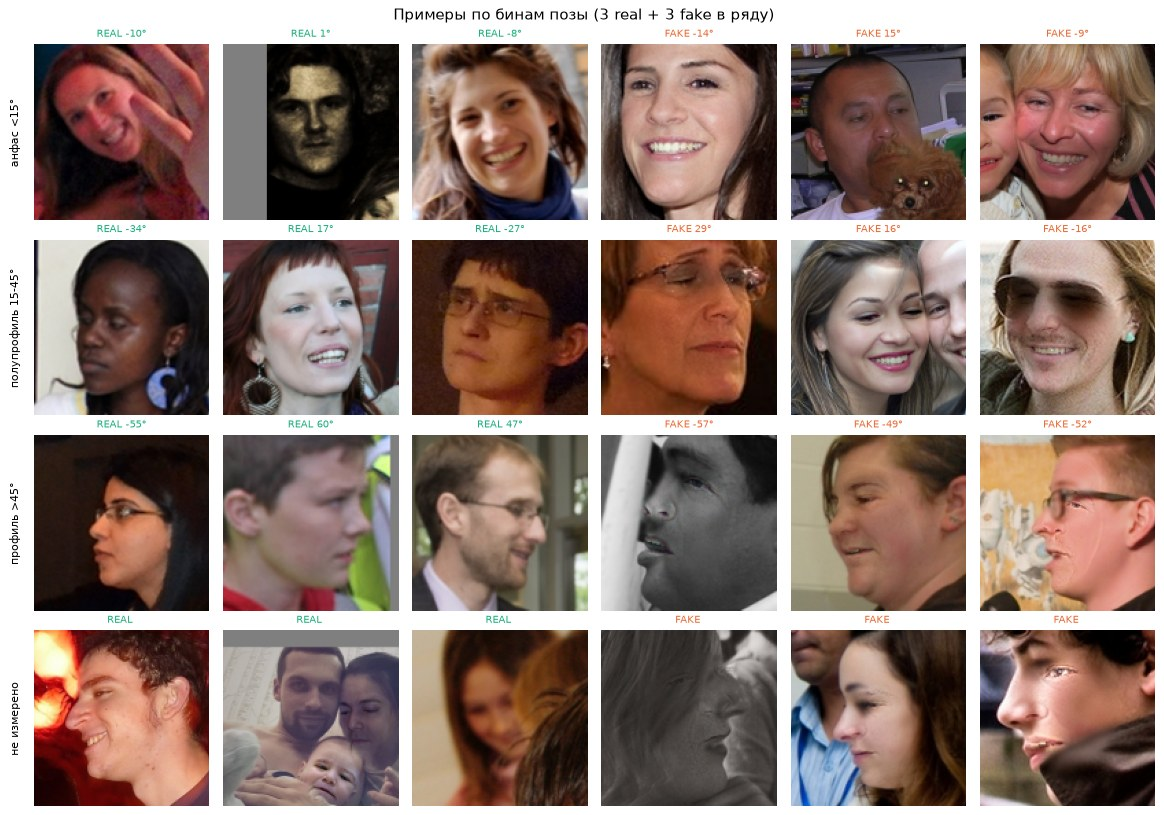

In [44]:
bins_names = ["анфас <15°", "полупрофиль 15-45°", "профиль >45°", "не измерено"]
fig, axes = plt.subplots(len(bins_names), 6, figsize=(13, 9.2))
for row_axes, b in zip(axes, bins_names):
    sel = [r for lab in ["real", "fake"] for _, r in df[(df["pose_bin"] == b) & (df["label"] == lab) & (df["face_side_px"] >= 64)].pipe(sample_rows, 3, random_state=SEED).iterrows()]
    for ax, r in zip(row_axes, sel):
        ax.imshow(crop_of(r, out=128)); ax.axis("off")
        ax.set_title(f"{r['label'].upper()} " + ("" if pd.isna(r["yaw"]) else f"{r['yaw']:.0f}°"), fontsize=8, color=PLOT_COLOR[r["label"]])
    row_axes[0].text(-10, 64, b, rotation=90, ha="right", va="center", fontsize=9)
fig.suptitle("Примеры по бинам позы (3 real + 3 fake в ряду)")
plt.tight_layout(); plt.show()

*Как читать. Слева: сочетания поворота влево-вправо и наклона вверх-вниз, темнее = больше лиц, пунктиры отмечают 15° и 45°. Справа: распределение поворота у real и fake. Первая таблица: доли групп позы (каждая строка = 100% лиц этого сплита и класса). Вторая: сколько лиц в группе и хватает ли их для выводов (200 на класс). Третья: AUC поворота.*

**Что видим.**

- **Что есть в данных:** анфас 60–75%, полупрофиль 23–36%, профиль всего 0,6–1,4%, «не измерено»
  0,5–3%. В Val и Test-Dev профилей меньше 200 на класс, проверить на них модель нельзя.
- **Различается ли у real и fake:** fake чаще в полупрофиль (в Train 36% против 23% у real), AUC
  0,56–0,59: слабая подсказка. На смешанных кадрах то же самое.
- Проверка на парах «одно лицо до и после подмены» (7.5): поворот после подмены почти не меняется.
  Значит, генератор не поворачивает голову, а **для подмены чаще выбирали повёрнутые лица**.

**Решение.** Качество модели всегда показываем отдельно для анфаса и полупрофиля. На профилях сервис
отвечает «недостаточно данных». При обучении выравниваем позу между классами вместе с размером лица.

## 7.3 Только ли анфас в данных?

**Нет, не только.** Анфас около двух третей лиц, полупрофиль около трети, но **профилей почти нет**
(около 1%), и часть настоящих профилей прибор вообще не измерил (6.1). Скорее всего, авторы при отборе
лиц для подмены отсеивали сильно повёрнутые. Значит, на профилях модель будет работать вслепую.

## 7.4 Освещение

**Зачем.** В тени и на засвеченной коже следы подделки видны хуже. И если подделки в среднем светлее или
темнее настоящих, свет станет лазейкой.

**Как.** Смотрим три вещи: насколько светлое лицо (0 = чёрное, 100 = белое), есть ли сильный боковой свет
(левая половина лица заметно светлее правой) и связан ли свет лица со светом фона. Свет на этих фото
никто не ставил, его можно только измерить. Поэтому главное, что мы можем сделать, это потом показывать
качество модели отдельно для тёмных, средних и светлых лиц.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for lab in ["real", "fake"]:
    v = df.loc[df["label"] == lab, "face_L_mean"]
    axes[0].hist(v, bins=np.linspace(0, 100, 60), density=True, histtype="step", lw=2, color=PLOT_COLOR[lab], label=f"{lab}: медиана {v.median():.1f}")
    w = df.loc[df["label"] == lab, "lr_asym"].clip(-40, 40)
    axes[1].hist(w, bins=np.linspace(-40, 40, 60), density=True, histtype="step", lw=2, color=PLOT_COLOR[lab], label=f"{lab}: |Δ| > 10 у {(w.abs() > 10).mean():.0%}")
axes[0].set_ylabel("плотность"); axes[1].set_ylabel("плотность")
axes[0].set_xlabel("светлота лица L* (0 = чёрный, 100 = белый)"); axes[0].legend(); axes[0].set_title("Светлота лица")
axes[1].set_xlabel("L* слева - L* справа"); axes[1].legend(); axes[1].set_title("Боковой свет")
hb = axes[2].hexbin(df["bg_L_mean"], df["face_L_mean"], gridsize=50, bins="log", cmap="Blues", extent=(0, 100, 0, 100))
hb.set_array(hb.get_array() / hb.get_array().sum()); hb.autoscale()
axes[2].plot([0, 100], [0, 100], color="k", lw=0.8, ls="--")
axes[2].set_xlabel("L* фона вокруг лица"); axes[2].set_ylabel("L* лица"); axes[2].set_title("Свет лица следует за светом сцены")
plt.colorbar(hb, ax=axes[2], label="доля лиц (лог)")
plt.tight_layout(); plt.show()

light = pd.concat([effect_table(df, c, by="split").assign(признак=c) for c in ["face_L_mean", "lr_asym", "bg_L_mean", "ita"]], ignore_index=True)
display(Markdown("**Смещение световых признаков: весь сплит**")); display(fmt_effects(light.set_index(["признак", "группа"])))
light_mx = pd.concat([effect_table(df[df["frame_type"] == "mixed"], c, by="split").assign(признак=c) for c in ["face_L_mean", "ita"]], ignore_index=True)
display(Markdown("**Только смешанные кадры** (свет и камера у real и fake общие)")); display(fmt_effects(light_mx.set_index(["признак", "группа"])))
print(f"ρ Спирмена ITA ~ L* лица: {spearmanr(df['ita'], df['face_L_mean'], nan_policy='omit')[0]:.2f} "
      f"(ITA почти полностью следует за светом снимка)")

**Смещение световых признаков: весь сплит**

**Только смешанные кадры** (свет и камера у real и fake общие)

ρ Спирмена ITA ~ L* лица: 0.84 (ITA почти полностью следует за светом снимка)


График обновится при запуске EDA на исходниках: прежние таблицы измерений не сохранились. Код использует нормированную плотность или долю наблюдений.

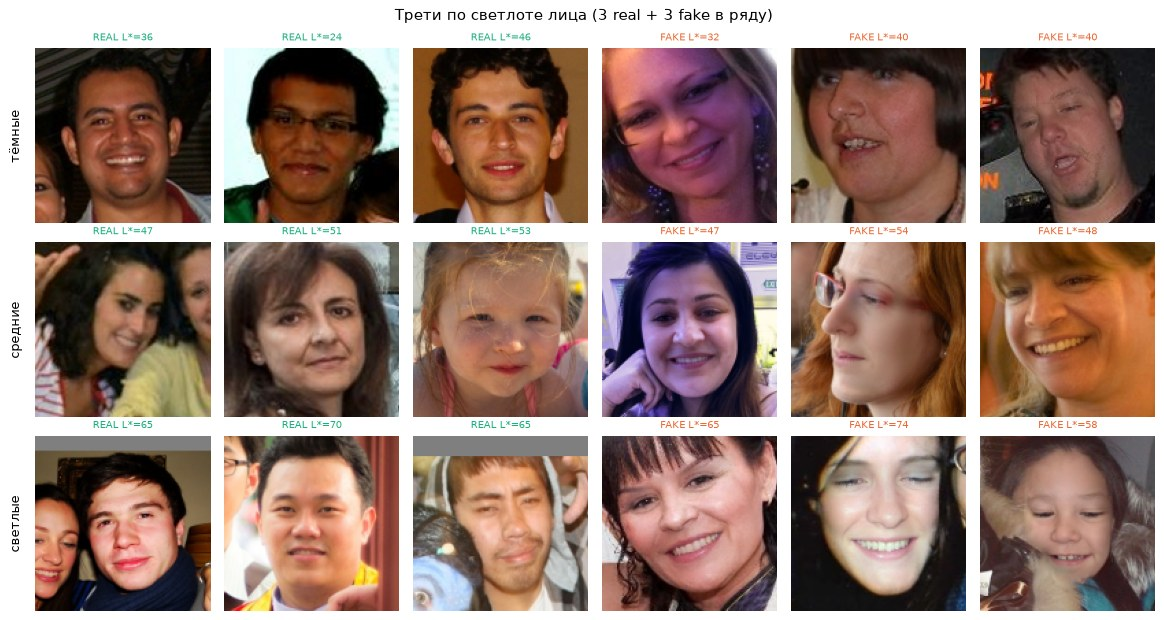

In [46]:
df["light_tercile"] = pd.qcut(df["face_L_mean"], 3, labels=["тёмные", "средние", "светлые"])
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for row_axes, t in zip(axes, ["тёмные", "средние", "светлые"]):
    sel = [r for lab in ["real", "fake"] for _, r in df[(df["light_tercile"] == t) & (df["label"] == lab) & (df["face_side_px"] >= 64)].pipe(sample_rows, 3, random_state=SEED).iterrows()]
    for ax, r in zip(row_axes, sel):
        ax.imshow(crop_of(r, out=128)); ax.axis("off")
        ax.set_title(f"{r['label'].upper()} L*={r['face_L_mean']:.0f}", fontsize=8, color=PLOT_COLOR[r["label"]])
    row_axes[0].text(-10, 64, t, rotation=90, ha="right", va="center", fontsize=10)
fig.suptitle("Трети по светлоте лица (3 real + 3 fake в ряду)")
plt.tight_layout(); plt.show()

*Как читать. Слева: светлота лица у real и fake. В центре: боковой свет (0 = равномерный, в подписи доля лиц с сильным боковым светом). Справа: светлота лица против светлоты фона, пунктир = «одинаково светлые». Таблицы: AUC световых признаков, отдельно по всем лицам и по смешанным фото.*

**Что видим.**

- **Что есть в данных:** есть всё, от очень тёмных до засвеченных лиц (светлота от 16 до 81 из 100,
  середина 52). Сильный боковой свет у 17–18% лиц. Свет лица повторяет свет сцены вокруг.
- **Различается ли у real и fake:** fake чуть светлее (52,6 против 50,3 в Train), AUC 0,55–0,56, на
  границе «не страшно / слабая подсказка». Боковой свет и свет фона не различаются (0,51–0,53).
- На парах (7.5) подмена лицо не осветляет (fake светлее только в 40% пар). Значит, это снова
  **отбор**: для подмены брали чуть более светлые лица.
- Шкала светлоты кожи ITA почти полностью повторяет светлоту снимка (связь ρ = 0,84). Значит, она меряет
  в первую очередь освещение, а не цвет кожи.

**Решение.** Качество модели показываем отдельно для тёмных, средних и светлых лиц. Для вопросов
справедливости по цвету кожи ITA не годится, нужна ручная разметка выборки.

## 7.5 Все признаки сразу: какой сильнее всего подсказывает метку

**Зачем.** В 7.1–7.4 мы проверили четыре условия съёмки. Но лазейкой может оказаться и то, о
чём не спрашивали: число лиц на фото, положение лица в кадре, зернистость. Считаем тот же AUC для всех
признаков анкеты сразу и рисуем одной картой: чем оранжевее клетка, тем сильнее признак сам по себе
подсказывает метку.

(Здесь каждый признак проверяется по отдельности. Проверку «а если модель сложит все признаки вместе?»
делает шорткат-тест, он запланирован отдельным шагом.)

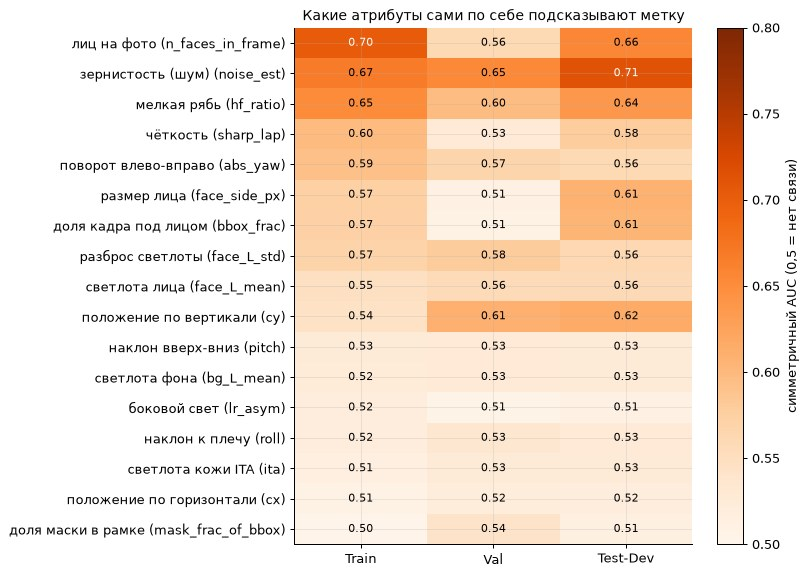

**Резкость, шум и высокие частоты внутри бинов размера лица (Train)**

In [47]:
radar_cols = ["face_side_px", "bbox_frac", "mask_frac_of_bbox", "cx", "cy", "n_faces_in_frame", "abs_yaw", "pitch", "roll",
              "face_L_mean", "face_L_std", "bg_L_mean", "lr_asym", "ita", "sharp_lap", "noise_est", "hf_ratio"]
radar = []
for c in radar_cols:
    for s in SPLITS:
        g = df[df["split"] == s][[c, "y_fake"]].dropna()
        a = auc_fake_gt_real(g[c].to_numpy(), g["y_fake"].to_numpy())
        radar.append({"признак": c, "сплит": s, "AUC sym": max(a, 1 - a)})
piv = pd.DataFrame(radar).pivot(index="признак", columns="сплит", values="AUC sym")[SPLITS].sort_values("Train", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(piv.values, cmap="Oranges", vmin=0.5, vmax=0.8, aspect="auto")
RU = {"face_side_px": "размер лица", "bbox_frac": "доля кадра под лицом", "mask_frac_of_bbox": "доля маски в рамке",
      "cx": "положение по горизонтали", "cy": "положение по вертикали", "n_faces_in_frame": "лиц на фото",
      "abs_yaw": "поворот влево-вправо", "pitch": "наклон вверх-вниз", "roll": "наклон к плечу", "face_L_mean": "светлота лица",
      "face_L_std": "разброс светлоты", "bg_L_mean": "светлота фона", "lr_asym": "боковой свет", "ita": "светлота кожи ITA",
      "sharp_lap": "чёткость", "noise_est": "зернистость (шум)", "hf_ratio": "мелкая рябь"}
ax.set_xticks(range(len(SPLITS)), SPLITS); ax.set_yticks(range(len(piv)), [f"{RU[c]} ({c})" for c in piv.index])
for (i, j), v in np.ndenumerate(piv.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.7 else "black")
plt.colorbar(im, ax=ax, label="симметричный AUC (0,5 = нет связи)"); ax.set_title("Какие атрибуты сами по себе подсказывают метку")
plt.tight_layout(); plt.show()

inner = pd.concat([effect_table(df[df["split"] == "Train"], c, by="size_bin").assign(признак=c) for c in ["sharp_lap", "hf_ratio", "noise_est"]])
display(Markdown("**Резкость, шум и высокие частоты внутри бинов размера лица (Train)**"))
display(fmt_effects(inner.set_index(["признак", "группа"])))

### Отбор или след генератора? Проверка на парах «одно лицо до и после подмены»

**Зачем.** Различие real и fake в признаке может быть двух видов, и выводы из них противоположные:
- **отбор**: для подмены чаще брали определённые лица (крупные, повёрнутые, светлые), а сама подмена
  признак не меняет. Это **лазейка**, её надо убирать.
- **след генератора**: подмена сама меняет признак (например, делает кожу глаже). Это **полезный
  сигнал**, именно его модель и должна искать.

**Как различаем.** Берём пары из шага 2.3: одно и то же лицо, в одной копии фото настоящее, в другой
подменено. Если внутри пары признак не меняется, различие создано отбором. Если меняется, это след
генератора.

In [48]:
pairs_df = df[df["face_src_id"].isin(mixed_src)]
cols = ["abs_yaw", "pitch", "face_L_mean", "ita", "sharp_lap", "noise_est", "hf_ratio"]
pr_r = pairs_df[pairs_df["label"] == "real"].groupby("face_src_id")[cols].mean()
pr_f = pairs_df[pairs_df["label"] == "fake"].groupby("face_src_id")[cols].mean()
both_ = pr_r.index.intersection(pr_f.index)
d = pr_f.loc[both_] - pr_r.loc[both_]
check = pd.DataFrame({"медиана (fake - real) в паре": d.median(), "доля пар, где у fake больше": (d > 0).mean(),
                      "AUC sym по всему Train": [piv.loc[c, "Train"] if c in piv.index else np.nan for c in cols]})
print(f"Пар: {len(both_):,}")
check.style.format({"медиана (fake - real) в паре": "{:+.3f}", "доля пар, где у fake больше": "{:.1%}", "AUC sym по всему Train": "{:.3f}"})

Пар: 16,669


,медиана (fake - real) в паре,"доля пар, где у fake больше",AUC sym по всему Train
abs_yaw,-0.137,46.0%,0.592
pitch,-2.146,28.4%,0.525
face_L_mean,-0.408,40.0%,0.548
ita,-1.453,36.2%,0.514
sharp_lap,-24.609,34.4%,0.598
noise_est,+0.031,57.6%,0.669
hf_ratio,+0.001,67.0%,0.652


*Как читать. Карта: строки = признаки анкеты, столбцы = сплиты, число = AUC (насколько признак сам по себе подсказывает метку; оранжевее = сильнее). Таблица под ней: то же для чёткости, шума и ряби внутри групп размера лица. Таблица пар: медиана изменения признака после подмены и доля пар, где у подделки значение больше (около 50% = подмена признак не меняет).*

**Что видим.**

- **Сильнее всего метку подсказывают не черты лица, а окружение и текстура.**
  - Число лиц на фото: AUC 0,70 в Train (заметная подсказка), 0,66 в Test-Dev.
  - Зернистость (шум): 0,67 / 0,65 / 0,71, у лиц 64–128 px до 0,77.
  - Доля мелкой ряби (высоких частот): 0,65 / 0,60 / 0,64.
- Слабые подсказки (0,55–0,61): чёткость, поворот, размер лица, положение по вертикали.
- Не страшные (≤ 0,55): свет фона, боковой свет, наклон к плечу, ITA, положение по горизонтали.
- **Проверка на парах:** поворот и светлота после подмены почти не меняются, это отбор. А мелкая рябь
  у fake больше в 67% пар, зернистость в 58%, чёткость ниже в 66%: подмена меняет текстуру. Оговорка:
  эти три признака считались по кропу рамки разметки, а рамка у fake теснее (3.4). Точное сравнение
  по одному окну запланировано отдельным шагом (парный анализ).

**Что это значит.**
- **Число лиц на фото это лазейка:** «групповое фото = настоящее лицо». Её нужно убирать при обучении.
- **Зернистость и мелкая рябь, скорее всего, след генератора:** текстура нарисованного лица отличается от
  снятой камерой. Это полезный сигнал, но он характерен для одного генератора 2021 года и на других
  датасетах может не работать. Именно его ловит простая модель в шаге 8.

## 7.6 Вывод по разделу 7

| Вопрос | Что есть в данных | Различие real и fake | Что делаем |
| --- | --- | --- | --- |
| **Лицо и фон** | лицо 0,01–50% кадра; Train в основном мелкие лица (медиана 0,8% кадра), Val и Test-Dev крупные (2,8–4,9%) | fake «крупнее» в целом (AUC 0,57–0,61), но на одном фото разницы нет: дело в том, из каких фото брали лица, и в рамке разметки (парадокс Симпсона) | кропы по детектору; выравнивание размера и числа лиц на кадре; качество модели отдельно по размеру лица |
| **Угол** | анфас ~2/3, полупрофиль ~1/3, профили ≈ 1% | fake чаще в полупрофиль (AUC 0,56–0,59), это отбор лиц для подмены | качество отдельно для анфаса и полупрофиля; выравнивание позы |
| **Только анфас?** | нет, но профилей почти нет (около 1%), часть их не измерена; в Val и Test-Dev профилей меньше 200 на класс, **проверить модель на профилях нельзя** | нет | профили = «недостаточно данных» |
| **Освещение** | весь диапазон от тёмных до засвеченных; боковой свет у 17–18% | fake чуть светлее (AUC 0,55), это отбор | качество отдельно для тёмных, средних, светлых лиц; ITA не использовать как цвет кожи |

---
# 8. Первая модель (бейзлайн): насколько легко найти подделку и на что опирается модель

**Где мы сейчас.** Шаги 1–7 описывали данные: что в них лежит, где метки врут, чем real и fake
различаются помимо подделки. Остался вопрос, на который без модели не ответить: **видна ли подделка,
насколько легко её найти и на что при этом опирается модель**, на саму подделку или на побочные признаки
(в литературе это называют shortcut learning).

**Зачем модель в EDA.** Модель здесь служит измерительным прибором: она показывает, сколько сигнала
подделки есть в данных, а её качество становится точкой отсчёта (baseline), с которой сравниваются все
следующие модели проекта. (По требованиям чекпойнта для DL-трека: простая базовая модель, разбор её
внутренних слоёв, записанное качество и проверка аугментаций.)

Идём от простого к сложному: простая модель на спектре картинки (8.2), готовая нейросеть (8.3),
дообученная нейросеть (8.4). Потом смотрим, где она ошибается (8.5), проверяем, не опирается ли она на
побочные признаки (8.6–8.8), и подбираем аугментации (8.9).

### Как оцениваем модель

Модель для каждого лица выдаёт **балл от 0 до 1**: «насколько похоже на подделку». Оцениваем двумя числами.

- **AUC** (от 0,5 до 1): насколько хорошо баллы разделяют подделки и настоящие лица. Это вероятность,
  что случайная подделка получит балл выше случайного настоящего лица. 0,5 значит угадывает как
  монетка, 1 значит никогда не путает.
- **TPR@1%** (от 0 до 1), главная оценка проекта: строгий режим. Пример: у нас 1 000 настоящих лиц
  и 1 000 подделок. Ставим порог так, чтобы ложно обвинить **не больше 10 настоящих** (1%). TPR@1%
  показывает, какую долю из 1 000 подделок модель при этом поймает. Строгий режим нужен, потому что в
  жизни подделок мало, и при мягком пороге почти все тревоги были бы ложными.

Дополнительно в таблицах:
- **EER**: процент ошибок при «честном» пороге, где пропусков и ложных тревог поровну (меньше лучше).
- **Brier и ECE**: можно ли верить самому баллу как вероятности (меньше лучше).
- Интервал AUC: в каких пределах было бы число на других фото.

Группы, где меньше 200 лиц какого-то класса, не оцениваем («мало данных»).

### Как учим и проверяем (одинаково для всех моделей)

- **Учим только на Train.** Берём 10 000 настоящих и 10 000 поддельных лиц. На 85% модель учится, на
  15% («отложенная часть») выбираем настройки и момент, когда остановить обучение.
- **Проверяем на Val и Test-Dev**, которых модель не видела.
- Копии одного исходного фото (шаг 2) всегда лежат в одной части. Иначе модель видела бы на проверке
  то же лицо, что и при обучении.

In [49]:
B.ensure_baseline(df)

# Результаты моделей: лица, отобранные для обучения и проверки, сами кропы и баллы моделей для каждого лица
idx = pd.read_parquet(CACHE / "crops_index.parquet")
CROPS = {k: np.load(CACHE / f"crops_{k}.npy", mmap_mode="r") for k in ["det", "ann"]}
scores = pd.concat([pd.read_parquet(p) for p in sorted((RESULTS / "baseline").glob("scores_*.parquet"))], ignore_index=True)
scores["eval_crop"] = scores.reindex(columns=["eval_crop"])["eval_crop"].fillna(scores["model"].str[-3:])   # у fft/probe тип кропа в имени
EVAL = {"val": "Val", "test": "Test-Dev"}
NAMES = {"fft_lr_det": "FFT + логрегрессия", "fft_lr_ann": "FFT + логрегрессия (кроп по разметке)",
         "probe_layer3_det": "готовая сеть, 3-й этаж + формула", "ft_det_flip": "дообученная сеть",
         "ft_ann_flip": "дообученная сеть (кроп по разметке)"}
FMT = {"AUC": "{:.3f}", "TPR@1%": "{:.3f}", "EER": "{:.3f}", "Brier": "{:.3f}", "ECE": "{:.3f}"}

def get(model, seed=SEED, degrade="clean", crop="det"):
    # баллы модели для лиц val/test вместе с их атрибутами
    s = scores[(scores["model"] == model) & (scores["seed"] == seed) & (scores["degrade"] == degrade) & (scores["eval_crop"] == crop)]
    return idx.loc[s["row"].to_numpy()].assign(score=s["score"].to_numpy())

def summary(model, seed=SEED, degrade="clean", crop="det", ci=True, calib=False):
    rows = []
    for part, name in EVAL.items():
        g = get(model, seed, degrade, crop).query("part == @part")
        m = basic(g["y_fake"], g["score"])
        r = {"модель": NAMES.get(model, model), "набор": name, "AUC": m["auc"], "TPR@1%": m["tpr@1%"], "EER": m["eer"]}
        if ci:
            lo, hi = boot_ci(g["y_fake"], g["score"], g["source_id"]); r["интервал AUC"] = f"[{lo:.3f}; {hi:.3f}]"
        if calib:
            r["Brier"] = float(np.mean((g["score"] - g["y_fake"]) ** 2)); r["ECE"] = ece(g["y_fake"].to_numpy(), g["score"].to_numpy())
        rows.append(r)
    return pd.DataFrame(rows)
print(f"Лиц для модели: {len(idx):,}; запусков моделей в результатах: {scores[['model', 'seed']].drop_duplicates().shape[0]}")

Лиц для модели: 45,601; запусков моделей в результатах: 22


## 8.1 Какие лица берём и как их вырезаем

**Что знаем из шагов 1–7.** Есть плохие лица: с противоречивой разметкой (3.7), меньше 32 px (3.5), с
подменённым соседом в кропе (3.2). И главное: **рамка разметки у подделок теснее**, чем у того же лица в
настоящей копии (3.4). Если резать лица по этой рамке, подделки окажутся «приближены», и модель сможет
угадывать по кадрированию.

**Что делаем.**
- Берём только «чистые» лица (без перечисленных проблем).
- Вырезаем квадрат вокруг лица по рамке **детектора лиц** YuNet (программа сама находит лицо, одинаково
  для real и fake), а не по рамке разметки.
- Для контроля храним и второй вариант, по рамке разметки, чтобы в 8.6 проверить, не опирается ли
  модель на кадрирование.

Квадрат в 1,3 раза больше лица, на вход сети 224×224 px. Кропы не пересжимаем, чтобы не добавить своих
артефактов сжатия.

In [50]:
counts = idx.groupby(["part", "label"]).size().unstack()[["real", "fake"]]
counts["доля real"] = counts["real"] / counts.sum(axis=1)
counts.index = counts.index.map({"fit": "Train: учим (85%)", "holdout": "Train: отложено (15%)", "val": "Val: проверка", "test": "Test-Dev: проверка"})
display(counts.style.format({"real": "{:,}", "fake": "{:,}", "доля real": "{:.0%}"}))
assert idx.groupby("source_id")["part"].nunique().max() == 1, "исходное фото попало в две части"
print("Копии одного исходного фото ни разу не попали в разные части.")

label,real,fake,доля real
part,,,
Train: учим (85%),"8,514","8,514",50%
Train: отложено (15%),"1,486","1,486",50%
Test-Dev: проверка,"4,951","7,047",41%
Val: проверка,"3,741","9,862",28%


Копии одного исходного фото ни разу не попали в разные части.


**Проверяем, что у детектора нет перекоса рамки.** Берём пары из шага 2.3: одно и то же лицо, в одной
копии фото настоящее, в другой подменённое. У такого лица размер и положение одинаковые, поэтому и
рамки должны совпадать. Сравниваем: во сколько раз рамка подделки меньше (1 = одинаковые) и в какой доле
пар она меньше (50% = случайно).

In [51]:
from notebook_src.of_crops import match_detector
pairs8 = df[df["face_src_id"].isin(df.groupby("face_src_id")["label"].nunique().pipe(lambda s: s[s == 2].index))]
pairs8 = pairs8[~pairs8["ann_conflict"] & (pairs8["face_side_px"] >= 32)]
det_all = pd.concat([pd.read_parquet(CACHE / f"yunet_frames_{s}.parquet").assign(split=s) for s in SPLITS])
pairs8 = pairs8.join(match_detector(pairs8, det_all))
pairs8 = pairs8[pairs8["det_idx"] >= 0]
pr8 = pairs8.groupby(["face_src_id", "label"]).first().unstack("label")
pr8 = pr8[pr8["face_id"].notna().all(axis=1)]

def ratio_stats(x, y, w, h):
    area = (w["fake"] * h["fake"]) / (w["real"] * h["real"])
    dcy = ((y["fake"] + h["fake"] / 2) - (y["real"] + h["real"] / 2)) / np.sqrt(w["real"] * h["real"])
    return area.median(), (area < 1).mean(), dcy.median()
box_check = {"рамка разметки": ratio_stats(pr8["x"], pr8["y"], pr8["w"], pr8["h"]),
             "рамка детектора": ratio_stats(pr8["det_x"], pr8["det_y"], pr8["det_w"], pr8["det_h"])}
display(pd.DataFrame(box_check, index=["площадь рамки fake / real (медиана)", "доля пар, где рамка fake меньше",
                                       "сдвиг центра fake вниз (доля стороны)"]).T.style.format("{:.3f}"))
print(f"Пар: {len(pr8):,}")

,площадь рамки fake / real (медиана),"доля пар, где рамка fake меньше",сдвиг центра fake вниз (доля стороны)
рамка разметки,0.833,0.958,0.024
рамка детектора,0.999,0.507,-0.004


Пар: 16,388


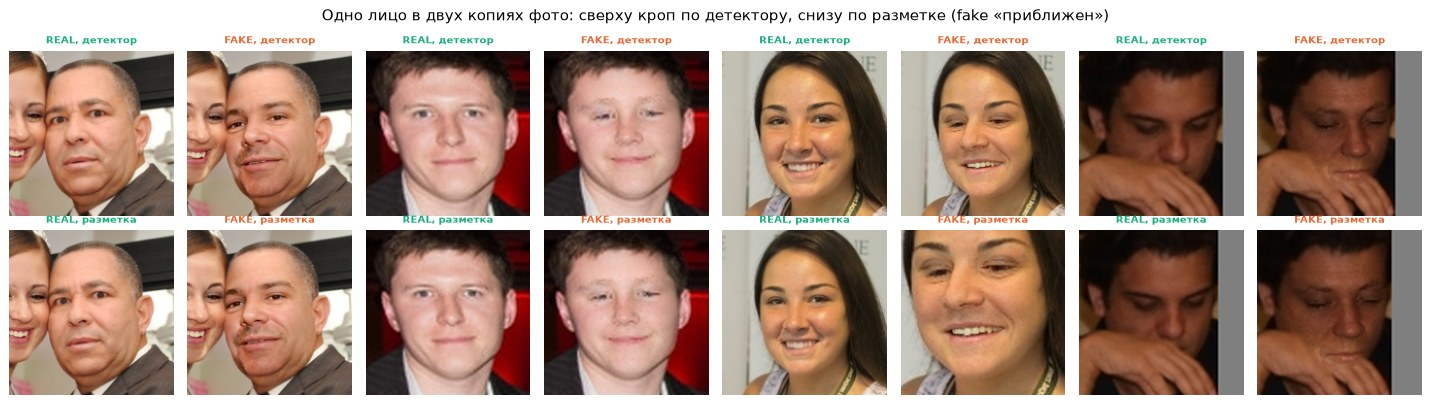

In [52]:
# Одно и то же лицо (настоящая и поддельная копия): кроп по детектору и по разметке
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for k, src in enumerate(pr8.pipe(sample_rows, 4, random_state=SEED).index):
    for j, lab in enumerate(["real", "fake"]):
        r = pairs8[(pairs8["face_src_id"] == src) & (pairs8["label"] == lab)].iloc[0]
        img = frame_img(r["split"], r["image_id"])
        for i, (kind, box) in enumerate([("детектор", r[["det_x", "det_y", "det_w", "det_h"]]), ("разметка", r[["x", "y", "w", "h"]])]):
            ax = axes[i, 2 * k + j]
            ax.imshow(crop_face(img, *box.astype(float), scale=1.3, out=160)); ax.axis("off")
            ax.set_title(f"{lab.upper()}, {kind}", fontsize=8, color=PLOT_COLOR[lab], fontweight="bold")
fig.suptitle("Одно лицо в двух копиях фото: сверху кроп по детектору, снизу по разметке (fake «приближен»)")
plt.tight_layout(); plt.show()

*Как читать. Таблица: для двух видов рамки во сколько раз рамка подделки меньше рамки того же настоящего лица (1 = одинаковые), в какой доле пар она меньше (50% = как случайно) и насколько сдвинут её центр. Картинки: одно лицо в двух копиях фото, сверху кроп по детектору, снизу по разметке.*

**Что видим.** На 16 388 парах рамка **разметки** у подделки меньше в 96% пар (площадь 0,83 от настоящей)
и сдвинута вниз. Рамка **детектора** одинакова у обеих копий: площадь 0,999, «меньше» ровно в половине
пар, как при случайности. На картинках при кропе по разметке подделка заметно приближена (третья пара).

**Решение.** Основной кроп по детектору. Кроп по разметке оставляем только для проверки в 8.6.

## 8.2 Самая простая модель: выдаёт ли подделку «мелкая рябь»?

**Что знаем.** В шаге 7.5 сильнее всего метку подсказывали зернистость и доля мелкой ряби в кропе, а на
парах подмена эту рябь меняла. Значит, генератор, похоже, оставляет свой «почерк» в мелких деталях.
**Проверяем:** сколько подделок можно поймать, глядя **только** на это.

**Модель.** Признаки: радиальный профиль спектра Фурье серого кропа (сколько энергии на каждой частоте,
от крупных пятен к самой мелкой ряби, 64 числа). Классификатор: логистическая регрессия. Это стандартный
простой детектор изображений GAN (Durall et al., 2020).

*Как читать график. Слева направо: от крупных пятен к самой мелкой ряби. По вертикали: сколько такого
«слоя» в картинке (числа сдвинуты так, чтобы сравнивать форму, а не общую яркость). В таблице AUC и
TPR@1% для Val и Test-Dev.*

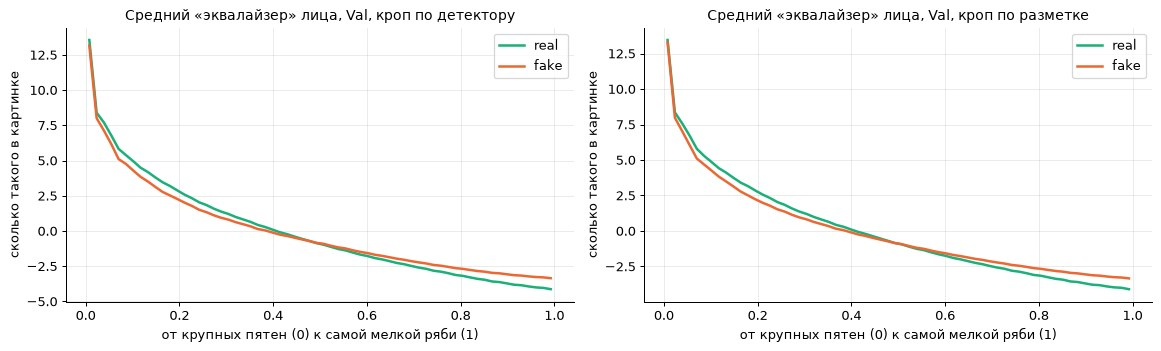

модель,набор,AUC,TPR@1%,EER,интервал AUC
FFT + логрегрессия,Val,0.836,0.026,0.236,[0.825; 0.846]
FFT + логрегрессия,Test-Dev,0.854,0.043,0.221,[0.845; 0.862]
FFT + логрегрессия (кроп по разметке),Val,0.832,0.057,0.241,[0.822; 0.842]
FFT + логрегрессия (кроп по разметке),Test-Dev,0.833,0.074,0.244,[0.823; 0.841]


In [53]:
F = {k: np.load(CACHE / f"fft_{k}_clean.npy") for k in ["det", "ann"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
freq = (np.arange(64) + 0.5) / 64
for ax, kind in zip(axes, ["det", "ann"]):
    m = idx["part"].eq("val").to_numpy()
    for lab in ["real", "fake"]:
        ax.plot(freq, F[kind][m & idx["label"].eq(lab).to_numpy()].mean(0), color=PLOT_COLOR[lab], lw=2, label=lab)
    ax.set_xlabel("от крупных пятен (0) к самой мелкой ряби (1)"); ax.set_ylabel("сколько такого в картинке")
    ax.set_title(f"Средний «эквалайзер» лица, Val, кроп по {'детектору' if kind == 'det' else 'разметке'}"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.concat([summary("fft_lr_det"), summary("fft_lr_ann", crop="ann")]).style.format(FMT).hide(axis="index"))

**Что видим.** У подделок меньше крупных и средних «слоёв» и **больше самой мелкой ряби** (правая треть
графика). Это совпадает с шагом 7.5. Простая формула по 64 числам даёт **AUC 0,84 на Val и 0,85 на
Test-Dev**. Но в строгом режиме **TPR@1% всего 0,03–0,04**: из 100 подделок ловим 3–4.

**Что это значит.** Почерк генератора в мелкой ряби есть, и его видно даже самым простым способом. Но он
слабый: у многих настоящих фото ряби тоже много (шум камеры, резкость), поэтому без ложных тревог
подделку так не поймать. Кроп по разметке простой модели не помогает (0,83): ей важна текстура, а не
кадрирование. **Вывод:** нужен инструмент, который видит не только общую «рябь», но и где она на лице.

## 8.3 Нейросеть: почему ResNet-18 и на каком этапе обработки видна подделка

**Связь с 8.2.** Спектр описывает картинку целиком: «сколько мелкой ряби во всём кропе». Но рябь дают и шум
камеры, и резкость, поэтому простая модель путается. А подделка сидит в конкретных местах: внутри маски
лица, на шве вклейки (шаги 3.3, 4.2, 4.3). Нужна модель, которая смотрит на картинку по участкам и
учитывает, **где** какая текстура. Так устроены свёрточные нейросети.

**Почему ResNet-18.** Задание чекпойнта просит для бейзлайна модель попроще. Кандидаты:

| Модель | Плюсы | Почему не она для бейзлайна |
| --- | --- | --- |
| **ResNet-18** (11 млн параметров) | простая и стандартная; есть веса, обученные на ImageNet; 4 чётких этапа обработки, их удобно разбирать по отдельности; учится за минуты на ноутбуке | выбрана |
| ResNet-50, Xception (23–26 млн) | точнее; Xception стандарт статей о дипфейках (FaceForensics++) | вдвое больше и дольше учить; в OpenForensics оставляли только подделки, которые Xception не распознал (1.2), поэтому сравнение с ним нечестное |
| EfficientNet-B0 (5 млн) | мало параметров, хорошая точность | устроена сложнее (много мелких блоков), её этапы труднее разбирать |
| CLIP, ViT (трансформеры) | сильные готовые признаки, по статьям лучше переносятся на новые генераторы | сложнее и тяжелее; это следующий шаг проекта, а не бейзлайн |

**Как устроена ResNet-18.** Сеть уже обучена узнавать предметы на 1,2 млн обычных фото (ImageNet);
подделок она не видела. Картинка проходит 4 этапа («этажа»). Каждый этаж применяет к картинке набор
фильтров, и **каждый фильтр выдаёт карту**: сетку чисел, где каждая клетка говорит, насколько в этом
месте нашлось то, что ищет фильтр.

| Этаж | Фильтров (карт) | Размер карты | Одна клетка карты = участок входа | Что ищут фильтры |
| --- | --- | --- | --- | --- |
| 1 | 64 | 56×56 | 4×4 px | края, точки, зерно |
| 2 | 128 | 28×28 | 8×8 px | текстуры: поры, волосы, ткань |
| 3 | 256 | 14×14 | 16×16 px | детали: уголок глаза, край губ, кожа щеки |
| 4 | 512 | 7×7 | 32×32 px | крупные части и «что это за предмет» |

Чем выше этаж, тем **грубее сетка** (карта 7×7 делит лицо всего на 49 квадратов), но тем **сложнее то,
что ищет каждый фильтр**: клетка 4-го этажа учитывает большой кусок лица вокруг себя. Это не
противоречие: сеть постепенно меняет «где именно» на «что именно». После 4-го этажа каждую из 512 карт
усредняют в одно число, и лицо превращается в 512 чисел (его «описание»), по которым считается ответ.

Ниже на одном лице: сверху сетка каждого этажа поверх фото (одна клетка = одна клетка карты), под ней
две самые контрастные карты этажа.

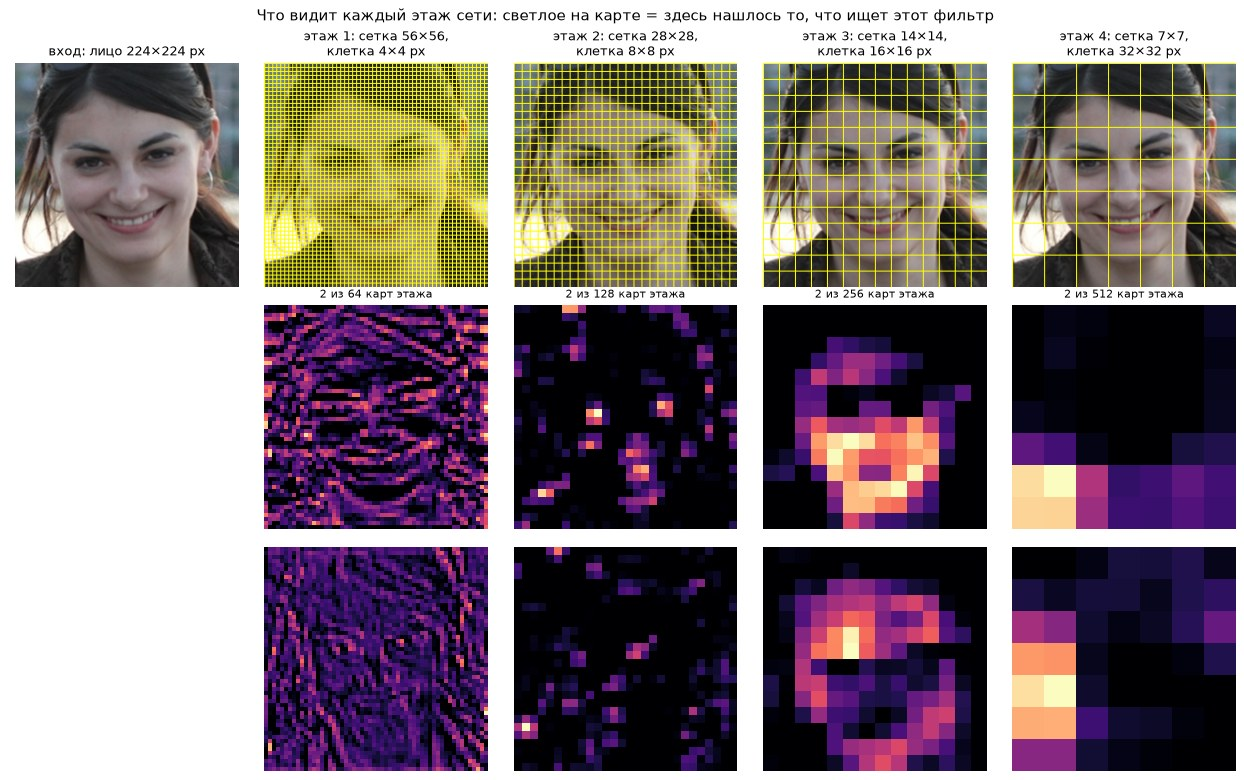

In [54]:
# Что видит каждый этаж готовой сети: сетка этажа поверх лица и две его карты
net = B.resnet().eval()
i_show = idx.index[(idx["part"] == "val") & (idx["label"] == "real")][0]                                    # настоящее лицо из Val: анфас, ровный свет
view = B.make_view(CROPS["det"][i_show])
with torch.no_grad():
    h = net.maxpool(net.relu(net.bn1(net.conv1(B.to_tensor([view])))))
    maps = []
    for layer in [net.layer1, net.layer2, net.layer3, net.layer4]:
        h = layer(h); maps.append(h[0].numpy())
fig, axes = plt.subplots(3, 5, figsize=(14, 8.8))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].imshow(view); axes[0, 0].set_title("вход: лицо 224×224 px", fontsize=10)
for j, m in enumerate(maps):
    n = m.shape[1]
    step = 224 // n
    grid = view.copy()
    grid[::step, :] = (255, 255, 0); grid[:, ::step] = (255, 255, 0)         # линии сетки этажа
    axes[0, j + 1].imshow(grid)
    axes[0, j + 1].set_title(f"этаж {j + 1}: сетка {n}×{n},\nклетка {step}×{step} px", fontsize=10)
    for k, c in enumerate(np.argsort(m.std(axis=(1, 2)))[::-1][:2]):        # две самые контрастные карты
        axes[k + 1, j + 1].imshow(m[c], cmap="magma")
        if k == 0:
            axes[k + 1, j + 1].set_title(f"2 из {m.shape[0]} карт этажа", fontsize=9)
fig.suptitle("Что видит каждый этаж сети: светлое на карте = здесь нашлось то, что ищет этот фильтр")
plt.tight_layout(); plt.show()

*Как читать. Верхний ряд: сетка этажа поверх лица, одна жёлтая клетка = одна клетка карты. Ниже: две
карты этого этажа той же сеткой; светлое = здесь фильтр нашёл то, что ищет.*

**Что видно.** На 1-м этаже карты ещё повторяют фото: контуры глаз, бровей, губ, прядей волос. На 2-м
светятся отдельные мелкие точки: блики, уголки глаз, серьга. На 3-м светятся целые участки: щёки, область
рта, обвод лица. На 4-м всего 49 клеток и светятся крупные зоны (волосы и плечо внизу слева): мелких
деталей уже не видно, зато каждая клетка учитывает большой участок вокруг себя.

**Как проверяем, на каком этаже видна подделка.** Сеть не меняем. Берём то, что выдаёт каждый этаж, и
на этом учим ту же простую формулу (логрегрессию), что в 8.2. Где формула угадывает лучше, на том этаже
подделка и «видна». Такой приём называют **линейным зондом**: мы «прощупываем» каждый этаж. Это и есть
требуемое заданием объяснение того, что происходит внутри сети.

Что из этого следует: если лучше всего первый этаж, подделку выдаёт простая текстура. Если четвёртый,
подделку выдаёт «смысл» (например, странная форма лица).

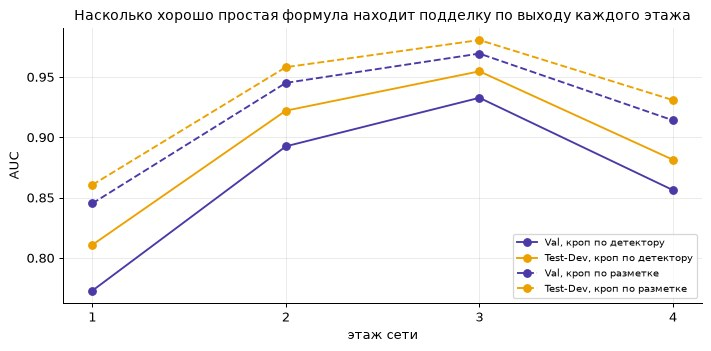

In [55]:
probe = []
for kind in ["det", "ann"]:
    for k, layer in enumerate(["layer1", "layer2", "layer3", "layer4"]):
        t = summary(f"probe_{layer}_{kind}", crop=kind, ci=False)
        probe.append(t.assign(этаж=k + 1, кроп="по детектору" if kind == "det" else "по разметке"))
probe = pd.concat(probe)
fig, ax = plt.subplots(figsize=(8, 4))
for kind, ls in [("по детектору", "-"), ("по разметке", "--")]:
    for name in ["Val", "Test-Dev"]:
        t = probe[(probe["кроп"] == kind) & (probe["набор"] == name)]
        ax.plot(t["этаж"], t["AUC"], ls, marker="o", color=SPLIT_COLOR[name], label=f"{name}, кроп {kind}")
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("этаж сети"); ax.set_ylabel("AUC")
ax.set_title("Насколько хорошо простая формула находит подделку по выходу каждого этажа"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(probe.pivot_table(index=["кроп", "этаж"], columns="набор", values=["AUC", "TPR@1%"]).style.format("{:.3f}"))

*Как читать. По горизонтали этаж сети, по вертикали AUC простой формулы на выходе этого этажа. Сплошные
линии: кроп по детектору, пунктир: кроп по разметке. Таблица: те же AUC и TPR@1%.*

**Что видим.** Лучше всего подделку видно на **3-м этаже** (AUC 0,93 на Val, 0,96 на Test-Dev). Хуже на
1-м (0,77 / 0,81) и, неожиданно, на последнем, 4-м (0,86 / 0,88). Уже это лучше простой модели из 8.2
(0,84), но в строгом режиме ловит только 34–39 подделок из 100. На кропах по разметке все этажи дают
больше, а TPR@1% на 3-м этаже почти вдвое выше (0,59 против 0,34 на Val).

**Что это значит.**
- Подделку выдают **детали среднего масштаба**. Клетка 3-го этажа (16×16 px) учитывает участок размером
  с глаз или щёку и различает, как выглядит кожа и мелкие черты в этом месте. Клетка 1-го этажа видит
  крошечный кусочек (край, точку): по нему не понять, естественна ли кожа. 4-й этаж готовой сети обучен
  отвечать «что это за предмет», и для него и настоящее, и поддельное лицо просто «лицо».
- Значит, чтобы сеть подстроилась под подделки, нужно доучить хотя бы её последний этаж (8.4).
- **На кропах по разметке все этажи угадывают лучше, и это подозрительно.** Лица те же, подделки те же,
  отличается только кадрирование: при кропе по разметке подделка «приближена» (8.1). Значит, часть
  прироста даёт не след подделки, а то, как лицо вписано в кадр. Проверяем это в 8.6.

## 8.4 Доучиваем нейросеть: линейка качества (baseline)

**Что делаем.** Берём ту же сеть и даём ей поучиться на наших лицах:
- этажи 1–3 не трогаем, они и так хорошо видят текстуры (8.3);
- 4-й этаж и последний шаг (одно число «насколько подделка») подстраиваем.

Сеть 6 раз просматривает 17 тыс. обучающих лиц. После каждого прохода
проверяем её на отложенной части Train и оставляем лучший момент. При обучении картинки только случайно
отражаем зеркально, остальные искажения проверяем в 8.9. Обучаем дважды, с разной случайностью (seed),
чтобы видеть, насколько результат случаен.

*Как читать графики обучения. Слева ошибка на обучающих лицах: должна падать. Справа качество на
отложенной части Train: должно расти и выйти на плато. Если бы справа оно начало падать, модель
«зазубривала» бы обучающие фото.*

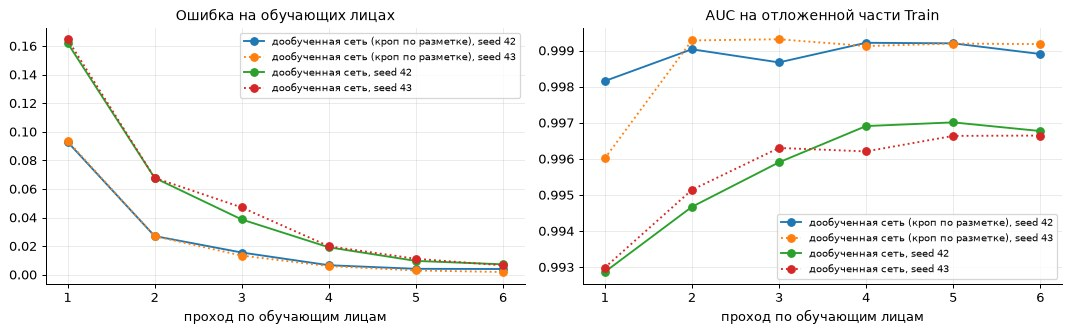

In [56]:
logs = pd.concat([pd.read_parquet(p) for p in sorted((RESULTS / "baseline").glob("log_ft_*.parquet"))])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (m, s), g in logs[logs["model"].isin(["ft_det_flip", "ft_ann_flip"])].groupby(["model", "seed"]):
    for ax, col in zip(axes, ["train_loss", "holdout_auc"]):
        ax.plot(g["epoch"], g[col], marker="o", ls="-" if s == SEED else ":", label=f"{NAMES[m]}, seed {s}")
axes[0].set_title("Ошибка на обучающих лицах"); axes[1].set_title("AUC на отложенной части Train")
for ax in axes:
    ax.set_xlabel("проход по обучающим лицам"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Что видно на графиках обучения.**
- У основной модели (кроп по детектору, зелёная и красная линии) ошибка ровно падает, а качество на
  отложенной части растёт до 4–5 прохода и выходит на плато около 0,997. Модель не зазубривает обучающие
  фото, 6 проходов достаточно.
- Два запуска с разной случайностью почти совпадают: результат устойчивый.
- Модель на кропах по разметке (синяя и оранжевая) **учится подозрительно быстро**: после первого прохода
  её ошибка почти вдвое ниже (0,09 против 0,16), а качество сразу 0,996–0,998. Так бывает, когда у модели
  есть лёгкая подсказка; здесь это кадрирование. Проверяем в 8.6.

модель,набор,AUC,TPR@1%,EER,интервал AUC,Brier,ECE,seed
дообученная сеть,Val,0.995,0.903,0.035,[0.994; 0.996],0.025,0.018,42
дообученная сеть,Test-Dev,0.998,0.957,0.022,[0.997; 0.998],0.017,0.011,42
дообученная сеть,Val,0.995,0.913,0.032,[0.994; 0.996],0.022,0.012,43
дообученная сеть,Test-Dev,0.998,0.961,0.020,[0.997; 0.998],0.017,0.010,43


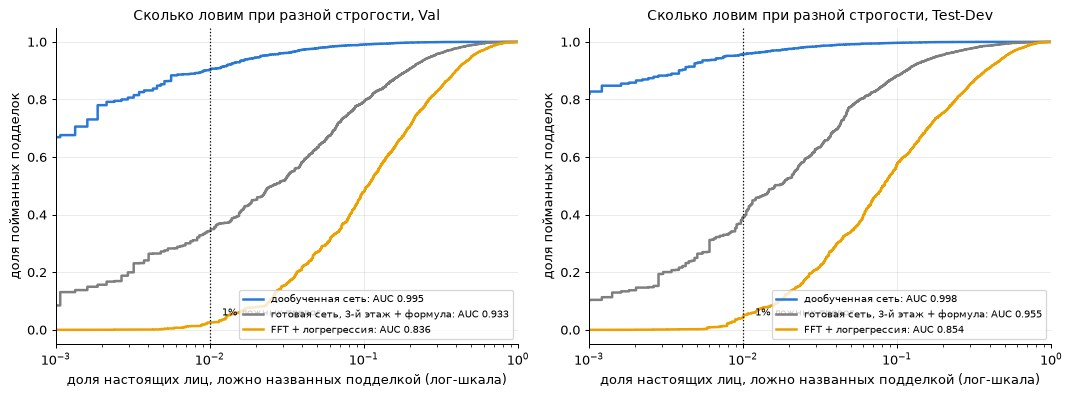

In [57]:
main = pd.concat([summary("ft_det_flip", seed=s, calib=True).assign(seed=s) for s in [42, 43]])
display(main.style.format(FMT).hide(axis="index"))

from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (part, name) in zip(axes, EVAL.items()):
    for model, color in [("ft_det_flip", "#2a78d6"), ("probe_layer3_det", "#7f7f7f"), ("fft_lr_det", "#eda100")]:
        g = get(model).query("part == @part")
        fpr, tpr, _ = roc_curve(g["y_fake"], g["score"])
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{NAMES[model]}: AUC {basic(g['y_fake'], g['score'])['auc']:.3f}")
    ax.axvline(0.01, color="k", ls=":", lw=1); ax.text(0.012, 0.05, "1% ложных тревог", fontsize=8)
    ax.set_xscale("log"); ax.set_xlim(1e-3, 1)
    ax.set_xlabel("доля настоящих лиц, ложно названных подделкой (лог-шкала)"); ax.set_ylabel("доля пойманных подделок")
    ax.set_title(f"Сколько ловим при разной строгости, {name}"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

*Как читать. Таблица: качество на Val и Test-Dev для двух запусков. На графиках по горизонтали: сколько настоящих лиц мы готовы ложно обвинить. По
вертикали: сколько подделок при этом поймаем. Пунктир отмечает строгий режим 1%: чем выше линия на
пунктире, тем лучше.*

**Что видим.** Доученная сеть даёт **AUC 0,995 на Val и 0,998 на Test-Dev**, а в строгом режиме ловит
**90–91 подделку из 100 на Val и 96 на Test-Dev**. Два запуска с разной случайностью отличаются не больше
чем на 0,01. Баллу можно верить как вероятности (ECE 0,01–0,02). Качество на отложенной части растёт до
4–5 прохода, потом плато: модель не зазубривает. На графике видно, как далеко она ушла от простой
формулы (жёлтая) и готовой сети без дообучения (серая).

**Что это значит.** **Внутри OpenForensics задача для нейросети почти решена.** Это совпадает со
статьями (~98–99%) и с шагом 1.2: все подделки сделаны одним генератором 2021 года, и модель выучила его
почерк. Поэтому 0,995 описывает качество на подделках именно этого генератора. Это число становится
точкой отсчёта (baseline) проекта, а следующая задача: проверить модель на подделках других генераторов
(140k, DF40), которых она не видела.

## 8.5 На каких лицах модель ошибается чаще

**Что знаем.** Шаги 3.5 и 7 показали, что в данных мало профилей, есть очень тёмные и очень светлые
лица, а размер лиц сильно разный, и в Val лица крупнее, чем в Train. Общее качество может прятать
провалы на отдельных группах лиц.

**Что делаем.** Считаем то же качество отдельно для групп по размеру лица, повороту головы и светлоте.
Так видно, где модели можно верить, а где сервис должен честно ответить «недостаточно данных».

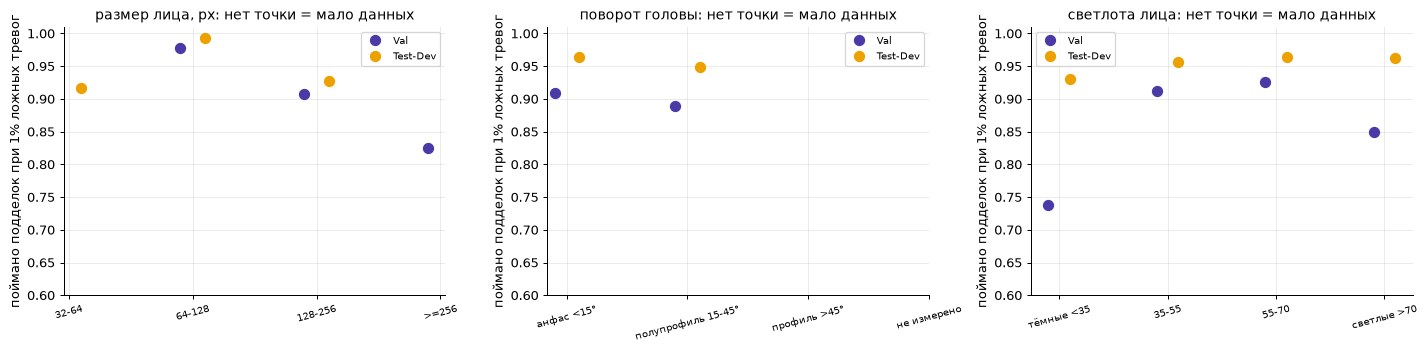

In [58]:
ev = get("ft_det_flip")
ev["светлота"] = pd.cut(ev["face_L_mean"], [0, 35, 55, 70, 101], labels=["тёмные <35", "35-55", "55-70", "светлые >70"])
tabs = []
for col, name in [("size_bin", "размер лица, px"), ("pose_bin", "поворот головы"), ("светлота", "светлота лица")]:
    for part, sname in EVAL.items():
        tabs.append(report(ev[ev["part"] == part], by=col).assign(признак=name, набор=sname))
bins8 = pd.concat(tabs).rename(columns={"auc": "AUC", "tpr@1%": "TPR@1%"})
ORDER = {"размер лица, px": ["32-64", "64-128", "128-256", ">=256"],
         "поворот головы": ["анфас <15°", "полупрофиль 15-45°", "профиль >45°", "не измерено"],
         "светлота лица": ["тёмные <35", "35-55", "55-70", "светлые >70"]}
bins8["группа"] = bins8["группа"].astype(str)
rows_order = [(f, g) for f, gs in ORDER.items() for g in gs]
quality = bins8.pivot_table(index=["признак", "группа"], columns="набор", values=["AUC", "TPR@1%"], observed=True, dropna=False)
sizes = bins8.pivot_table(index=["признак", "группа"], columns="набор", values=["n_real", "n_fake"], observed=True)
tab_bins = pd.concat([quality, sizes], axis=1).reindex(rows_order)
display(tab_bins.style.format("{:.3f}", subset=quality.columns, na_rep="мало данных").format("{:,.0f}", subset=sizes.columns))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, groups) in zip(axes, ORDER.items()):
    t = bins8[bins8["признак"] == name]
    for sname, off in [("Val", -0.1), ("Test-Dev", 0.1)]:
        tt = t[(t["набор"] == sname) & t["TPR@1%"].notna()]
        x = np.array([groups.index(g) for g in tt["группа"]]) + off
        ax.plot(x, tt["TPR@1%"], "o", ms=8, color=SPLIT_COLOR[sname], label=sname)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups, rotation=15, fontsize=8); ax.set_ylim(0.6, 1.01)
    ax.set_title(f"{name}: нет точки = мало данных"); ax.set_ylabel("поймано подделок при 1% ложных тревог"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Как читать. Таблица: AUC и TPR@1% по группам лиц, рядом сколько лиц real и fake в группе. График: доля пойманных подделок при 1% ложных тревог; точки нет, если в группе меньше 200 лиц какого-то класса.*

**Что видим.**
- **Размер лица.** Лучше всего на лицах 64–128 px: ловит 98–99 подделок из 100. На крупных хуже: 128–256 px
  91–93, от 256 px (Val) **83**. На мелких 32–64 px (Test-Dev) 92.
- **Поворот.** Анфас и полупрофиль почти одинаковы (91 и 89 из 100 на Val). Профилей и лиц без позы
  меньше 200 на класс, оценить нельзя.
- **Светлота.** Хуже всего на **тёмных** лицах: на Val **74** из 100 против 91–93 на средних, на светлых
  85. На Test-Dev разница меньше (93 против 96).

**Что это значит.**
- Неожиданно, но крупные лица труднее мелких. Возможная причина: крупное лицо сжимают до 224 px, и мелкие
  следы генератора сглаживаются. Это гипотеза, проверим в шаге о частотах.
- В тенях и на засвеченной коже следов подделки не видно (как на примерах в 4.4).

**Решение.** Качество модели в проекте всегда показываем по группам размера и светлоты. На профилях
сервис отвечает «недостаточно данных».

## 8.6 Не опирается ли модель на побочные признаки (shortcut learning)? Проверка 1: кадрирование

**Что знаем.** В 8.1 видели, что при кропе по разметке подделка «приближена», а в 8.3 на таких кропах
сеть работала заметно лучше. Подозрение: модель угадывает метку по тому, **как кадрировано лицо**, а не
по подделке.

**Как проверяем.**
1. Учим одну модель на кропах по разметке, другую на кропах по детектору, и **каждую проверяем на обоих
   вариантах кропа**. Если модель «по разметке» на кропах по детектору заметно теряет, её успех держался
   на кадрировании.
2. Ещё проще: берём для каждого лица **одно число**, «насколько крупно лицо в кропе по разметке», где
   нет ни одного пикселя подделки, и смотрим, угадывает ли оно метку (AUC).

In [59]:
cross = []
for model in ["ft_ann_flip", "ft_det_flip"]:
    for crop in ["ann", "det"]:
        for s in [42, 43]:
            for part, name in EVAL.items():
                g = get(model, seed=s, crop=crop).query("part == @part")
                cross.append({"учили на кропах": "по разметке" if "ann" in model else "по детектору",
                              "проверяем на кропах": "по разметке" if crop == "ann" else "по детектору",
                              "набор": name, "seed": s, "AUC": basic(g["y_fake"], g["score"])["auc"]})
cross = pd.DataFrame(cross)
display(cross.pivot_table(index=["учили на кропах", "проверяем на кропах"], columns="набор", values="AUC").style.format("{:.3f}"))

from sklearn.metrics import roc_auc_score
idx["framing"] = np.sqrt(idx["det_w"] * idx["det_h"]) / (1.3 * np.maximum(idx["w"], idx["h"]))   # насколько крупно лицо в кропе по разметке
framing_auc = {EVAL.get(p, p): roc_auc_score(g["y_fake"], g["framing"]) for p, g in idx.groupby("part")}
print("AUC одного числа «насколько крупно лицо в кропе по разметке»:", {k: round(v, 3) for k, v in framing_auc.items()})

AUC одного числа «насколько крупно лицо в кропе по разметке»: {'fit': 0.848, 'holdout': 0.849, 'Test-Dev': 0.83, 'Val': 0.817}


*Как читать. Таблица: строки = на каких кропах модель учили и на каких проверяем, число = AUC (среднее двух запусков). Строка под таблицей: AUC одного числа «насколько крупно лицо в кропе по разметке».*

**Что видим.**
- Модель, обученная **по детектору**, одинаково хороша на обоих вариантах кропа (Val 0,995 и 0,995).
- Модель, обученная **по разметке**, на своих кропах лучше всех (0,998), но на кропах по детектору
  теряет (0,983 на Val, 0,990 на Test-Dev). На графике обучения в 8.4 она и учится подозрительно быстро.
- Одно число «насколько крупно лицо в кропе по разметке», без единого пикселя подделки, угадывает метку
  с **AUC 0,82–0,85**. По шкале шага 7 это сильная лазейка.

**Что это значит.** Кадрирование по разметке это настоящая лазейка, и сеть ею пользуется.

**Решение (подтверждено).** Кропы режем только по детектору лиц, и это правило стоит закрепить для всей
команды. Случайный масштаб кропа при обучении (8.9) дополнительно мешает модели привязаться к
кадрированию.

## 8.7 Проверка 2: куда смотрит модель (Grad-CAM)

**Зачем.** Модель может давать 99%, глядя не на лицо, а на фон, край кропа или соседнего человека
(лазейки из шага 3). Нужно увидеть, **какие места картинки** толкают её к ответу.

**Что такое Grad-CAM.** Самый распространённый способ (2017 год) нарисовать поверх картинки тепловую
карту: красное = это место сильнее всего повлияло на ответ модели. Карту строят по 4-му этажу сети (сетка
7×7), поэтому она грубая: видно «лицо или фон», но не «левый глаз или правый».

**Как проверяем числом, а не только глазами.** Для 600 лиц из Val считаем, какая доля «тепла» лежит на
самом лице (внутри маски из разметки), и сравниваем с тем, сколько места лицо занимает в кропе. Если
модель смотрит куда попало, доли совпадут (отношение 1). Если на лицо, тепла на нём будет больше
(отношение больше 1).

In [60]:
def load_ft(name, seed=SEED):
    m = B.resnet(pretrained=False); m.fc = torch.nn.Linear(512, 1)
    m.load_state_dict(torch.load(CACHE / f"ft_{name}_{seed}.pt")); return m.to(B.device()).eval()

def gradcam(model, x, y):
    # тепловая карта для правильного ответа: для fake берём балл модели, для real балл со знаком минус
    store = {}
    def hook(m, i, o):
        store["a"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.layer4.register_forward_hook(hook)
    out = model(x).squeeze(1)
    model.zero_grad(); (out * torch.where(y > 0.5, 1.0, -1.0)).sum().backward(); h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)                    # вес каждой карты 4-го этажа
    cam = torch.relu((w * store["a"]).sum(1, keepdim=True))           # взвешенная сумма карт, только «за ответ»
    cam = torch.nn.functional.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False).squeeze(1)
    return (cam / (cam.flatten(1).max(1)[0][:, None, None] + 1e-8)).detach().cpu().numpy()

# Маски лиц в координатах кропа (кроп x1,3 по рамке детектора или разметки, 224 px)
seg_of = faces.set_index(["split", "face_id"])["segmentation"]
cam_set = pd.concat([idx[(idx["part"] == "val") & (idx["label"] == lab) & (idx["face_side_px"] >= 64)].pipe(sample_rows, 300, random_state=SEED) for lab in ["real", "fake"]])
def mask_view(r, kind):
    m = polygon_mask(seg_of[(r["split"], r["face_id"])], int(r["height"]), int(r["width"])) * 255
    box = (r["det_x"], r["det_y"], r["det_w"], r["det_h"]) if kind == "det" else (r["x"], r["y"], r["w"], r["h"])
    return crop_face(m, *box, scale=1.3, out=224) > 127

cams, masks = {}, {}
for model_name, kind in [("det_flip", "det"), ("ann_flip", "ann")]:
    model = load_ft(model_name)
    xs = torch.stack([B.to_tensor([B.make_view(CROPS[kind][i])])[0] for i in cam_set.index])
    ys = torch.tensor(cam_set["y_fake"].to_numpy(), dtype=torch.float32)
    cams[model_name] = np.concatenate([gradcam(model, xs[s:s + 50].to(B.device()), ys[s:s + 50].to(B.device())) for s in range(0, len(xs), 50)])
    masks[model_name] = np.stack([mask_view(r, kind) for _, r in cam_set.iterrows()])

border = np.zeros((224, 224), bool); border[:24] = border[-24:] = True; border[:, :24] = border[:, -24:] = True
cam_rows = []
for name in cams:
    c, m = cams[name], masks[name]
    tot = c.sum((1, 2))
    empty = tot == 0                       # ни одно место не тянет к правильному ответу (обычно ошибка модели)
    share = np.where(empty, np.nan, (c * m).sum((1, 2)) / np.maximum(tot, 1e-8))
    edge = np.where(empty, np.nan, (c * border).sum((1, 2)) / np.maximum(tot, 1e-8))
    area = m.mean((1, 2))
    for lab in ["real", "fake"]:
        sel = (cam_set["label"] == lab).to_numpy()
        cam_rows.append({"модель": "кроп по детектору" if name == "det_flip" else "кроп по разметке", "класс": lab,
                         "доля тепла на лице": np.nanmean(share[sel]), "доля места под лицом": area[sel].mean(),
                         "во сколько раз тепло собрано на лице": np.nanmean(share[sel] / area[sel]),
                         "доля тепла у краёв кропа": np.nanmean(edge[sel]), "пустых карт": int(empty[sel].sum())})
display(pd.DataFrame(cam_rows).style.format(precision=2).hide(axis="index"))

модель,класс,доля тепла на лице,доля места под лицом,во сколько раз тепло собрано на лице,доля тепла у краёв кропа,пустых карт
кроп по детектору,real,0.66,0.38,1.77,0.14,0
кроп по детектору,fake,0.68,0.30,2.32,0.08,0
кроп по разметке,real,0.60,0.34,1.77,0.15,0
кроп по разметке,fake,0.75,0.37,2.07,0.09,1


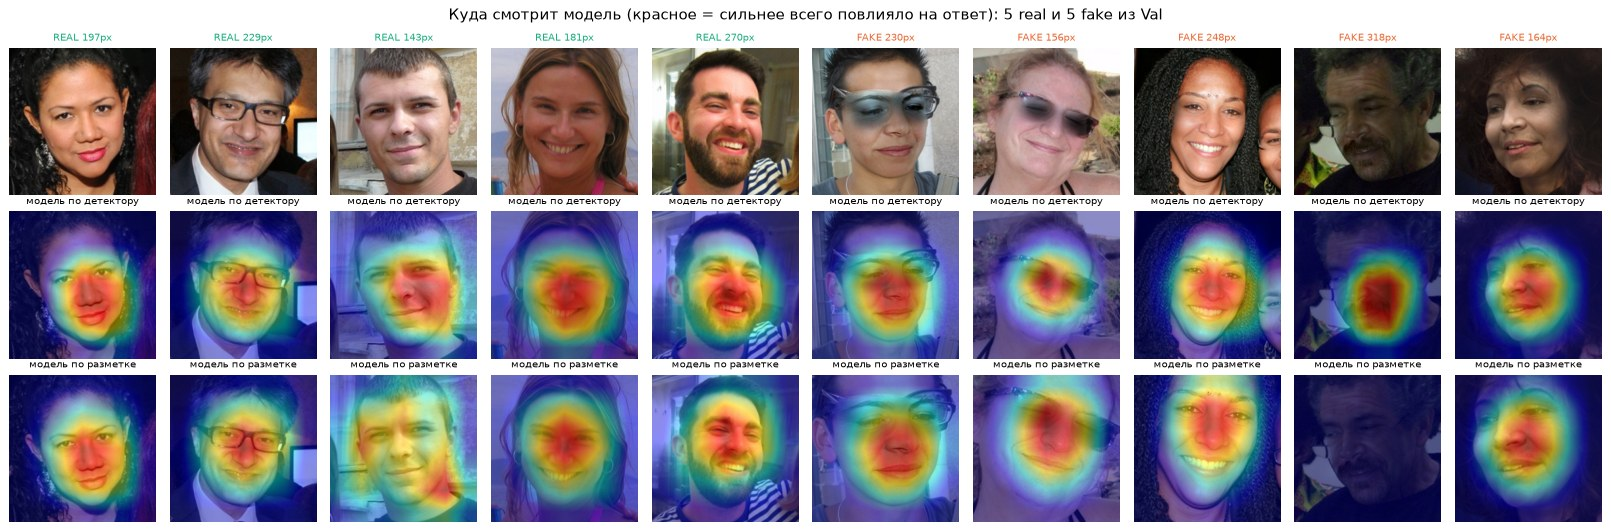

In [61]:
def overlay(img, cam):
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[:, :, ::-1]
    return (0.55 * img + 0.45 * heat).astype(np.uint8)

show_rows = pd.concat([cam_set[cam_set["label"] == lab].head(5) for lab in ["real", "fake"]])
fig, axes = plt.subplots(3, 10, figsize=(18, 6))
pos = {i: k for k, i in enumerate(cam_set.index)}
for j, (i, r) in enumerate(show_rows.iterrows()):
    img_d, img_a = B.make_view(CROPS["det"][i]), B.make_view(CROPS["ann"][i])
    for row, im, title in [(0, img_d, f"{r['label'].upper()} {r['face_side_px']:.0f}px"),
                           (1, overlay(img_d, cams["det_flip"][pos[i]]), "модель по детектору"),
                           (2, overlay(img_a, cams["ann_flip"][pos[i]]), "модель по разметке")]:
        axes[row, j].imshow(im); axes[row, j].axis("off")
        axes[row, j].set_title(title, fontsize=8, color=PLOT_COLOR[r["label"]] if row == 0 else "black")
fig.suptitle("Куда смотрит модель (красное = сильнее всего повлияло на ответ): 5 real и 5 fake из Val")
plt.tight_layout(); plt.show()

*Как читать. Таблица (600 лиц Val): какая доля «тепла» лежит на лице, сколько места лицо занимает в кропе, их отношение (1 = смотрит куда попало, больше 1 = на лицо), доля тепла у краёв кропа. Картинки: сверху лицо, ниже тепловые карты двух моделей; красное = сильнее повлияло на ответ.*

**Что видим.** У основной модели (кроп по детектору) **около 2/3 «тепла» лежит на самом лице**, хотя
лицо занимает только 30–38% кропа: тепло собрано на лице в 1,8 раза (real) и 2,3 раза (fake) сильнее,
чем если бы модель смотрела куда попало. У краёв кропа 8% тепла у fake и 14% у real. На картинках
красная зона почти всегда в центре лица (нос, щёки, рот), а не на фоне и не на соседях.

**Что это значит.** Модель смотрит на лицо, лазейки «фон» и «сосед» она не использует. Одна оговорка:
у настоящих лиц тепла у краёв больше, то есть «это настоящее» модель отчасти решает по окружению лица.
Это стоит помнить при проверке на других датасетах, где окружение другое (у 140k студийные портреты).

## 8.8 Проверка 3: как модель группирует лица (UMAP)

**Зачем.** Grad-CAM (8.7) смотрит на одну картинку. Нужно проверить **весь набор сразу**: по какому
признаку модель считает лица похожими, по подделке или по побочным признакам из шага 7 (размер лица,
число людей на фото, сплит).

**Как это устроено, по шагам.**
1. **Описание лица.** После 4-го этажа сети каждое лицо превращается в 512 чисел (8.3). Это и есть то, как
   модель «видит» лицо.
2. **Похожие описания.** Если модель считает два лица похожими, их 512 чисел близки.
3. **Карта.** 512 чисел на бумаге не нарисовать. Метод UMAP (уменьшение размерности) рисует каждое лицо
   точкой на плоскости так, чтобы похожие для модели лица оказались рядом, а непохожие далеко. Оси карты
   ничего не значат, важно только, кто с кем рядом и какие группы («облака») получились.
4. **Раскраска.** Одну и ту же карту красим четырьмя способами: по метке (real / fake), по сплиту, по
   размеру лица, по числу людей на фото. Если по метке точки разошлись на отдельные облака, а по остальным
   признакам цвета перемешаны, модель группирует лица по подделке.
5. **Проверка числом.** Глаз на такой карте может обмануться, поэтому считаем простое число: для каждого
   лица берём 10 самых похожих (по описанию модели) и смотрим, какая доля из них той же метки (того же
   размера, того же сплита). Сравниваем с долей, которая получилась бы при случайных соседях.

Сравниваем две сети: готовую (ImageNet, без дообучения, верхний ряд) и доученную (нижний ряд). 8 000
случайных лиц из Val и Test-Dev.

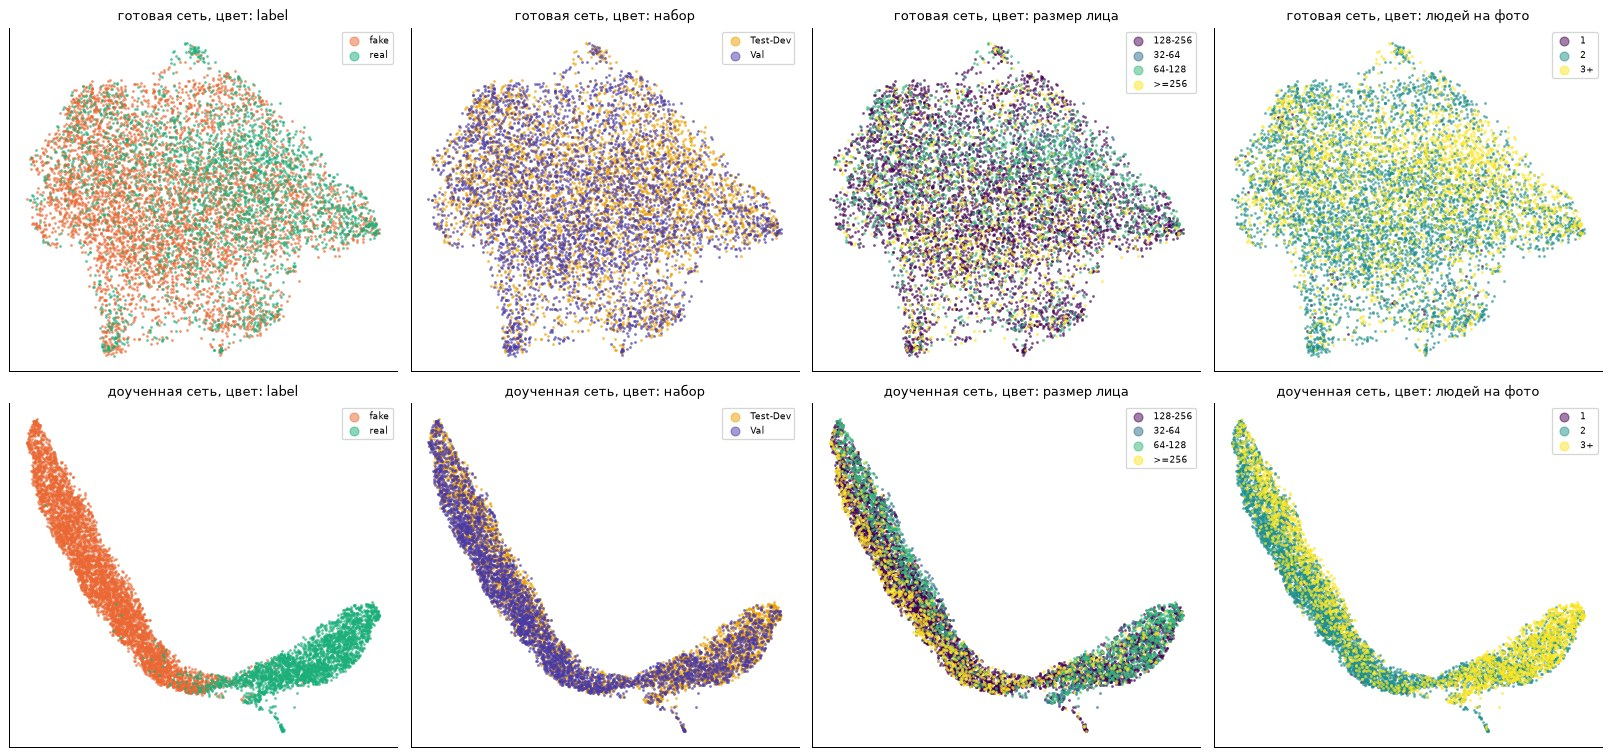

In [62]:
warnings.filterwarnings("ignore", message=".*IProgress not found.*")      # служебные предупреждения umap и tqdm
warnings.filterwarnings("ignore", message=".*n_jobs value.*")
import umap
from sklearn.neighbors import NearestNeighbors
ev_rows = idx.index[idx["part"].isin(["val", "test"])]
emb_ft = np.load(CACHE / "emb_ft_det_flip_42.npy").astype(np.float32)          # строки = ev_rows по порядку
emb_in = np.load(CACHE / "probe_det.npy")[ev_rows, 448:].astype(np.float32)     # 4-й этаж готовой сети
sub = np.random.default_rng(SEED).choice(len(ev_rows), min(8000, len(ev_rows)), replace=False)
meta = idx.loc[ev_rows[sub]].copy()
meta["людей на фото"] = pd.cut(meta["n_faces_in_frame"], [0, 1, 2, 99], labels=["1", "2", "3+"])
meta["набор"] = meta["part"].map(EVAL)
meta["размер лица"] = meta["size_bin"].astype(str)
colorings = [("label", PLOT_COLOR), ("набор", SPLIT_COLOR), ("размер лица", None), ("людей на фото", None)]

def same_neighbours(X, labels, k=10):
    # доля из k ближайших соседей с той же меткой; и та же доля при случайных соседях
    Xs = (X - X.mean(0)) / (X.std(0) + 1e-6)
    ind = NearestNeighbors(n_neighbors=k + 1).fit(Xs).kneighbors(Xs, return_distance=False)[:, 1:]
    lab = pd.factorize(labels)[0]
    p = np.bincount(lab) / len(lab)
    return (lab[ind] == lab[:, None]).mean(), p @ p

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
pur = []
for row, (name, X) in enumerate([("готовая сеть", emb_in[sub]), ("доученная сеть", emb_ft[sub])]):
    xy = umap.UMAP(n_neighbors=30, min_dist=0.2, random_state=SEED).fit_transform((X - X.mean(0)) / (X.std(0) + 1e-6))
    for ax, (col, pal) in zip(axes[row], colorings):
        vals = meta[col].astype(str)
        cats = sorted(vals.unique())
        cmap = plt.get_cmap("viridis", len(cats))
        for k, c in enumerate(cats):
            m = (vals == c).to_numpy()
            ax.scatter(xy[m, 0], xy[m, 1], s=2, alpha=0.5, color=(pal or {}).get(c, cmap(k)), label=c)
        ax.set_title(f"{name}, цвет: {col}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        ax.legend(markerscale=5, fontsize=7, loc="best")
        same, chance = same_neighbours(X, vals.to_numpy())
        pur.append({"сеть": name, "признак": col, "соседи того же значения": same, "при случайных соседях": chance})
plt.tight_layout(); plt.show()
display(pd.DataFrame(pur).pivot_table(index="признак", columns="сеть", values=["соседи того же значения", "при случайных соседях"], sort=False).style.format("{:.2f}"))

*Как читать. Каждая точка = лицо; рядом стоят лица, которые модель считает похожими. Таблица: доля из 10
ближайших соседей с тем же значением признака и та же доля при случайных соседях; чем больше разница,
тем сильнее модель группирует лица по этому признаку.*

**Что видим.**
- **Готовая сеть (верхний ряд):** одно размытое облако, real и fake перемешаны. Из 10 соседей той же
  метки 67%, при случайных соседях было бы 55%: подделку сеть почти не отличает.
- **Доученная сеть (нижний ряд):** точки выстроились в дугу. Один её конец почти целиком из подделок,
  другой из настоящих лиц, а в середине лица, в которых модель сомневается. Той же метки **97%** соседей.
- **По сплиту и размеру лица** цвета перемешаны вдоль всей дуги: доля соседей того же сплита и размера
  почти не изменилась после дообучения (0,55 и 0,55 против 0,55 и 0,53) и близка к случайной.
- **По числу людей на фото** на «настоящем» конце дуги больше жёлтых точек (3 и больше человек). Это
  состав данных: настоящие лица в основном из групповых фото (1.5). Сама модель на число людей не
  смотрит сильнее, чем готовая сеть: доля соседей с тем же числом людей почти та же (0,66 против 0,64).

**Что это значит.** Дообучение научило сеть группировать лица **по подделке**, а не по размеру лица,
числу людей или сплиту. Окончательно вопрос о побочных признаках закрывает шорткат-тест (запланирован
отдельным шагом).

## 8.9 Аугментации: какие искажения картинки помогают при обучении

**Что знаем.** В OpenForensics все фото почти без сжатия (JPEG 100, приложение A1). В жизни фото почти
всегда сжаты мессенджерами и соцсетями, а лица бывают мелкими и размытыми. Модель, которая видела только
«чистые» фото, на сжатых может растеряться.

**Что такое аугментация.** При обучении мы специально и случайно портим картинки: отражаем, сжимаем,
размываем, меняем цвет. Так модель учится не цепляться за случайные мелочи и готовится к реальным фото.
**Особенность нашей задачи:** аугментация может стереть сам след подделки. Например, размытие стирает
мелкую рябь, которую ищет модель (8.2). Поэтому каждую проверяем.

| Искажение | Ожидание | Почему |
| --- | --- | --- |
| Зеркальное отражение | подходит | след подделки от отражения не меняется |
| Сжатие JPEG (качество 30–95, у половины картинок) | подходит, важно | так сжимают мессенджеры и соцсети |
| Случайный масштаб кропа (1,2–1,6 от лица) и сдвиг | подходит | мешает угадывать по кадрированию (8.6) |
| Размытие или уменьшение (у 30% картинок) | подходит в меру | похоже на мелкие лица и плохие камеры, но сильное стирает рябь |
| Сильное изменение цвета и яркости | осторожно | несовпадение цвета вклейки и шеи может быть настоящим следом подделки |
| Смешивание двух картинок (Mixup, CutMix) | не подходит | следы двух лиц смешаются, метка потеряет смысл; не проверяем |

**Как проверяем.** Учим одну и ту же сеть с нарастающим набором искажений (каждый вариант дважды) и
проверяем на трёх версиях Val и Test-Dev: обычные кропы; кропы, сжатые JPEG с качеством 50 (как после
мессенджера); кропы, уменьшенные вдвое и растянутые обратно (как мелкое лицо).

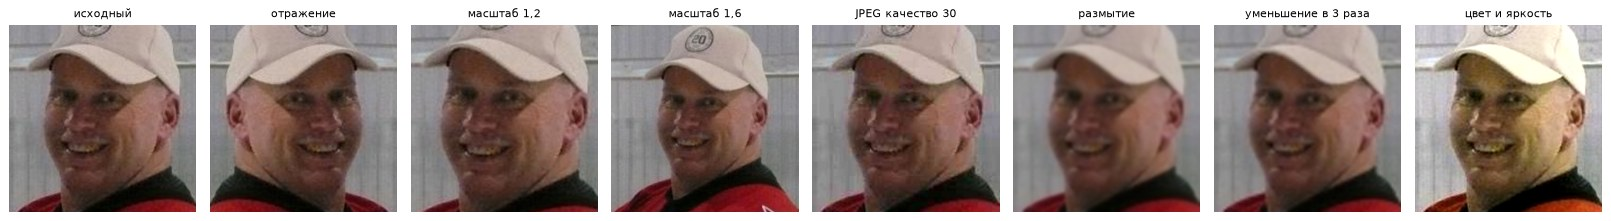

In [63]:
# Как выглядят искажения на одном лице
i0 = idx[(idx["part"] == "fit") & (idx["face_side_px"] > 120)].pipe(sample_rows, 1, random_state=SEED + 5).index[0]
img0 = np.ascontiguousarray(CROPS["det"][i0])
views = [("исходный", B.make_view(img0)),
         ("отражение", B.make_view(img0)[:, ::-1]),
         ("масштаб 1,2", B.resize(np.ascontiguousarray(img0[32:224, 32:224]), 224)),
         ("масштаб 1,6", B.resize(img0, 224)),
         ("JPEG качество 30", B.resize(B.jpeg(np.ascontiguousarray(img0[24:232, 24:232]), 30), 224)),
         ("размытие", B.resize(cv2.GaussianBlur(np.ascontiguousarray(img0[24:232, 24:232]), (0, 0), 1.5), 224)),
         ("уменьшение в 3 раза", B.resize(B.resize(np.ascontiguousarray(img0[24:232, 24:232]), 73), 224)),
         ("цвет и яркость", B.color_jitter(B.make_view(img0), np.random.default_rng(SEED)))]
fig, axes = plt.subplots(1, len(views), figsize=(18, 2.8))
for ax, (t, v) in zip(axes, views):
    ax.imshow(v); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [64]:
AUG = [("det_none", "1. без искажений"), ("det_flip", "2. отражение"), ("det_jpeg_scale", "3. + JPEG + масштаб"),
       ("det_full", "4. + размытие"), ("det_color", "5. + цвет")]
TEST = {"clean": "обычные", "jpeg50": "сжатые JPEG 50", "down50": "уменьшенные"}
aug = []
for cfg, name in AUG:
    for s in [42, 43]:
        for deg in TEST:
            for part, sname in EVAL.items():
                g = get(f"ft_{cfg}", seed=s, degrade=deg).query("part == @part")
                m = basic(g["y_fake"], g["score"])
                aug.append({"искажения при обучении": name, "seed": s, "тест": TEST[deg], "набор": sname, "AUC": m["auc"], "TPR@1%": m["tpr@1%"]})
for deg in TEST:
    for part, sname in EVAL.items():
        g = get("fft_lr_det", degrade=deg).query("part == @part")
        m = basic(g["y_fake"], g["score"])
        aug.append({"искажения при обучении": "простая модель FFT (для сравнения)", "seed": SEED, "тест": TEST[deg], "набор": sname, "AUC": m["auc"], "TPR@1%": m["tpr@1%"]})
aug = pd.DataFrame(aug)
order = [n for _, n in AUG] + ["простая модель FFT (для сравнения)"]
cols = [(n, t) for n in ["Val", "Test-Dev"] for t in TEST.values()]
tab_tpr = aug.pivot_table(index="искажения при обучении", columns=["набор", "тест"], values="TPR@1%", aggfunc="mean").reindex(order)[cols]
display(tab_tpr.style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=0.0, vmax=1.0)
        .set_caption("Сколько подделок ловим при 1% ложных тревог (среднее двух запусков)"))
tab_auc = aug.pivot_table(index="искажения при обучении", columns=["набор", "тест"], values="AUC", aggfunc="mean").reindex(order)[cols]
display(tab_auc.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=1.0).set_caption("AUC (среднее двух запусков)"))
spread = aug[aug["искажения при обучении"] != order[-1]].groupby(["искажения при обучении", "набор", "тест"])["AUC"].agg(lambda v: v.max() - v.min())
print(f"Разница AUC между двумя запусками одного варианта: обычно {spread.median():.3f}, максимум {spread.max():.3f}")

Разница AUC между двумя запусками одного варианта: обычно 0.000, максимум 0.004


*Как читать. Первая таблица: сколько подделок из 100 ловим при 1% ложных тревог; строки = набор искажений при обучении (каждый следующий добавляет к предыдущему), столбцы = обычные, сжатые и уменьшенные кропы Val и Test-Dev; зелёное = лучше. Вторая таблица: то же для AUC.*

**Что видим.**
- **На обычных кропах все варианты одинаковы** (AUC 0,994–0,998, ловим 89–96 из 100): внутри
  OpenForensics искажения качество не добавляют и не отнимают.
- **На сжатых и уменьшенных кропах разница большая.**
  - Без искажений (и с одним отражением) после сжатия JPEG 50 ловим только **60–65 из 100**, после
    уменьшения 68–73.
  - Сжатие и масштаб при обучении поднимают это до 82–86 на сжатых.
  - Размытие добавляет устойчивость к уменьшению: 89–91 вместо 81–84.
- **Изменение цвета** не помогло и не навредило (разница в пределах случайности, 0,004 AUC).
- **Простая модель FFT** на сжатых и уменьшенных кропах почти перестаёт работать: AUC падает с 0,84–0,85
  до 0,78–0,81, а в строгом режиме ловит 1–3 из 100. Сжатие стирает именно ту рябь, на которую она смотрит.

**Что это значит.** Модель без искажений привыкла к «чистым» фото и после обычного сжатия теряет треть
пойманных подделок. Сжатие, масштаб и лёгкое размытие при обучении подходят: на обычных фото качество
то же, а на испорченных намного выше.

**Решение.** Базовый набор искажений для проекта: отражение + сжатие JPEG (качество 30–95) + масштаб
кропа 1,2–1,6 + лёгкое размытие или уменьшение. Изменение цвета пользы не дало, поэтому в базовый набор
не берём. Его можно оставить как отдельный эксперимент.

## 8.10 Итог раздела 8: записанное качество (baseline) и что из него следует

| Что проверяли | Результат | Что делаем |
| --- | --- | --- |
| Простая модель (FFT + формула) | AUC 0,84–0,85, в строгом режиме 3–4 из 100 | почерк генератора в мелкой ряби есть, но слабый; это нижняя граница |
| Готовая сеть по этажам | лучше всего виден на 3-м этаже (AUC 0,93–0,96) | доучивать хотя бы последний этаж |
| Доученная сеть | AUC 0,995 / 0,998, в строгом режиме 90 / 96 из 100 | **это линейка качества**; внутри датасета задача почти решена |
| Кроп по разметке | лазейка кадрирования, AUC 0,82–0,85; модель ею пользуется | кропы только по детектору, правило для команды |
| Куда смотрит (Grad-CAM) | 2/3 внимания на лице, в 1,8–2,3 раза больше, чем при взгляде куда попало | модель смотрит на лицо, а не на фон и соседей |
| Как раскладывает (UMAP) | по метке 97% соседей, по размеру и числу людей почти случайно | лазеек в «описаниях» лиц не видно |
| Группы лиц | хуже на крупных (от 256 px) и тёмных лицах: 74–83 из 100 на Val | качество всегда по группам; профили = «недостаточно данных» |
| Искажения при обучении | после сжатия ловим 84–86 из 100 вместо 61–65, на обычных без потерь | базовый набор: отражение + JPEG + масштаб + размытие |

> **Опасный момент.** Все числа получены **внутри OpenForensics**: в обучении и в проверке подделки одного
> генератора и фото из одного источника. AUC 0,995 не значит, что модель найдёт подделки других
> генераторов. Предварительный опыт на простых моделях давал перенос между датасетами 0,39–0,57,
> то есть почти монетку. Поэтому следующий шаг проекта: проверить модель на других датасетах, а эта
> таблица служит точкой отсчёта для сравнения.

Ниже итоговая таблица качества (везде кроп по детектору, проверка на обычных кропах).

In [65]:
FULL_NAME = {"det_flip": "дообученная сеть, отражение", "det_full": "дообученная сеть, отражение + JPEG + масштаб + размытие"}
final = pd.concat([summary("fft_lr_det", calib=True), summary("probe_layer3_det", calib=True),
                   summary("ft_det_flip", calib=True).assign(модель=FULL_NAME["det_flip"]),
                   summary("ft_det_full", calib=True).assign(модель=FULL_NAME["det_full"])])
final = final.set_index(["модель", "набор"])
final.to_csv(RESULTS / "baseline" / "baseline_metrics.csv")
display(final.style.format(FMT))

---
# Итог

### Самое важное

**Данным можно доверять.** Файлы целы, все кадры одного формата (1024 px, JPEG 100, без EXIF), поэтому
формат файла не подсказывает метку. Одних и тех же фото в Train, Val и Test-Dev нет; та же сцена или тот
же человек в разных частях встречается редко (0,06–0,12% кадров).

**Real и fake различаются не только подделкой.** Подделки чаще взяты из фото на двоих, а настоящие лица
из групповых фото; подделки чаще в полупрофиль и чуть светлее. Это не след генератора, а то, **какие
лица выбирали для подмены**: у одного и того же лица до и после подмены эти признаки не меняются.
Сильнее всего метку подсказывает число лиц на фото (AUC 0,70).

**Подделка внутри этого датасета видна хорошо.** Простая модель на спектре картинки даёт AUC 0,84, но
при 1% ложных тревог ловит лишь 3–4 подделки из 100. Доученная ResNet-18 даёт AUC 0,995 и ловит 90–96
подделок из 100. Она смотрит на само лицо, а не на фон и соседей, и группирует лица по подделке, а не по
размеру или числу людей на фото.

**Где модель слабее.** На крупных (от 256 px) и тёмных лицах она ловит 74–83 подделки из 100 вместо
91–99. Профилей в данных около 1%, в Val и Test-Dev меньше 200 на класс: **проверить модель на профилях
нельзя**.

**Главное ограничение.** Все подделки OpenForensics сделаны одним генератором 2021 года, поэтому высокое
качество описывает именно его. Следующая задача проекта: проверить модель на подделках других
генераторов.

### Что мы узнали нового и интересного

1. **Датасет «двойной».** Почти каждое исходное фото использовано дважды: в одной копии лицо оставили
   настоящим, в другой подменили. Получилось 16,7 тыс. готовых пар «до и после подмены» с одинаковым
   фоном и светом. По ним видно, что меняет генератор (черты лица, вплоть до возраста, и текстуру кожи),
   а что нет (позу, свет, причёску).
2. **Разметка сама подсказывает ответ.** Авторы обводили подделку теснее, чем то же лицо в настоящей
   копии. Одно число «насколько крупно лицо в кропе по разметке» угадывает метку с AUC 0,82–0,85, и
   нейросеть этим пользуется. Без пар «до и после» этого не было бы видно.
3. **«Подделки крупнее» оказалось иллюзией.** В целом fake крупнее, но на одном и том же фото разницы нет
   (парадокс Симпсона): дело в том, из каких фото брали лица для подмены.
4. **Подделку выдаёт текстура среднего масштаба.** Готовая нейросеть лучше всего видит подделку на
   3-м этапе обработки (участки размером с глаз или щёку), а не на последнем. И при одинаковом размере лица
   у подделок выше зернистость.
5. **Крупные лица труднее мелких.** Это неожиданно: на лицах 64–128 px модель ловит 98–99 подделок из
   100, а на лицах от 256 px только 83.
6. **Сжатие отнимает треть пойманных подделок.** После обычного сжатия, как в мессенджере, модель без
   аугментаций ловит 61–65 подделок из 100 вместо 90–96, а простая модель на спектре почти перестаёт
   работать. Сжатие, масштаб кропа и лёгкое размытие при обучении поднимают это до 84–86, на обычных
   фото без потерь.
7. **Разметка в целом чистая.** Рамок на «не-лицах» почти нет: из 159 тыс. крупных рамок детекторы не
   нашли лицо в 49, и почти все они оказались настоящими лицами в трудных условиях.

### Опасные моменты (ловушки в данных)

> 1. **Рамка разметки у подделок теснее.** Если резать кропы по разметке, модель учится на кадрировании.
>    → Кропы режем только по детектору лиц.
> 2. **Число лиц на фото подсказывает метку:** групповое фото почти всегда означает настоящее лицо.
>    → Выравниваем число лиц и размер между классами при обучении.
> 3. **Копии одного фото лежат внутри Train** (у 70% кадров). При случайном делении одно и то же лицо
>    попадёт и в обучение, и в проверку. → Делим Train только по исходному фото.
> 4. **В кроп настоящего лица попадает подменённый сосед** (21% real в Val): метка «real» на картинке с
>    подделкой. → Такие лица убираем из обучения, качество считаем с ними и без.
> 5. **Лица меньше 32 px:** подделки на них не видно, а классы различаются «чёткостью пятна». → Исключаем.
> 6. **Противоречивая разметка** (73 случая, когда одно лицо размечено и real, и fake) и неразмеченные
>    лица (в 22,5% кадров Train). → Противоречия исключаем, работаем только с размеченными лицами.
> 7. **Профилей почти нет**, а их пропуски в данных не случайны. → На профилях сервис отвечает
>    «недостаточно данных».
> 8. **Модель без аугментаций не готова к сжатым фото.** → Обучаем с отражением, сжатием JPEG, масштабом
>    кропа и лёгким размытием.

### Как используем результаты в проекте

| Что узнали | Как используем |
| --- | --- |
| Копии одного фото внутри сплитов | делим Train только по исходному фото (`source_id`) |
| Рамка разметки у подделок теснее | кропы только по детектору лиц; правило для всей команды |
| Плохие лица: < 32 px, противоречивая разметка, подменённый сосед в кропе | исключаем из обучения; качество считаем с ними и без |
| Число лиц на фото и размер подсказывают метку | выравниваем их между классами при обучении |
| Модель слабее на крупных и тёмных лицах, профили не проверить | качество всегда показываем по группам размера, позы и света; на профилях сервис отвечает «недостаточно данных» |
| Без аугментаций модель теряет треть подделок на сжатых фото | обучаем с отражением, сжатием JPEG, масштабом кропа и лёгким размытием |
| Baseline: FFT + логрегрессия AUC 0,84; ResNet-18 AUC 0,995 | точка отсчёта для всех моделей проекта |

### Что подтвердилось из предварительных замеров

| Предварительный замер | Итог на полном датасете |
| --- | --- |
| Train 150 866 лиц (56% real), Val 15 345 (31%), Test-Dev 49 718 (42%) | подтвердилось |
| 74% кадров Train смешанные | подтвердилось |
| Медиана стороны лица Train 73 / 85 px, Val 191 / 192, Test-Dev 128 / 156 | подтвердилось |
| AUC размера лица Train 0,573, Val 0,512 | подтвердилось (интервал Train [0,570; 0,577]) |
| Внутри смешанных кадров fake меньше real (0,87) | число подтвердилось, **но объяснение другое**: это артефакт рамки разметки |
| Загрязнение кропа ×1,3: Train real 3,8%, Val real 21% | подтвердилось |
| Анфас 60–72%, полупрофиль 24–38%, профиль 1–2% | почти: анфас 60–75%, полупрофиль 23–36%, профиль 0,6–1,4% |
| OpenForensics самый лёгкий датасет для простой модели (FFT + LR AUC 0,84) | подтвердилось: 0,84 / 0,85 |

---
# Приложение. Технические проверки

Проверки, результат которых короткий («всё в порядке» или одно число), но которые обязательно нужно
сделать перед анализом. Их выводы использованы в разделе 1.4.

## A1. Файлы кадров: читаемость, размеры, EXIF, JPEG

- **Читаемость**: каждый файл полностью декодируется (`im.load()` читает все пиксели).
- **EXIF Orientation**: поле метаданных «поверни картинку при показе». Разные библиотеки учитывают его
  по-разному, и если разметчик видел фото повёрнутым, рамки окажутся не на лицах.
- **Качество JPEG** оцениваем по таблицам квантования: перебираем качество 1…100 и ищем, с какой
  стандартной таблицей libjpeg совпадает таблица файла. Для нестандартных таблиц оценка неточна,
  поэтому храним флаг «совпала точно».

In [66]:
by = frames.groupby("split")
a1 = pd.DataFrame({
    "файлов": by.size(), "читается": by["exists"].mean(),
    "размер = JSON": by.apply(lambda g: ((g["w_file"] == g["width"]) & (g["h_file"] == g["height"])).mean()),
    "RGB": by["mode"].apply(lambda s: (s == "RGB").mean()),
    "MD5-копий": by["md5"].apply(lambda s: s.duplicated().sum()),
    "без EXIF": by["n_exif_tags"].apply(lambda s: (s == 0).mean()),
    "Orientation != 1": by["exif_orient"].apply(lambda s: (s != 1).sum()),
    "JPEG q (мин..макс)": by["jpeg_q"].apply(lambda s: f"{s.min():.0f}..{s.max():.0f}"),
    "таблица стандартная": by["jpeg_std_table"].mean(),
    "длинная сторона = 1024": by.apply(lambda g: (g[["width", "height"]].max(axis=1) == 1024).mean()),
    "макс. сторона, px": by.apply(lambda g: g[["width", "height"]].max(axis=1).max()),
}).loc[SPLITS]
a1.style.format({c: "{:.1%}" for c in ["читается", "размер = JSON", "RGB", "без EXIF", "таблица стандартная", "длинная сторона = 1024"]})

,файлов,читается,размер = JSON,RGB,MD5-копий,без EXIF,Orientation != 1,JPEG q (мин..макс),таблица стандартная,длинная сторона = 1024,"макс. сторона, px"
split,,,,,,,,,,,
Train,44097,100.0%,100.0%,100.0%,0,100.0%,0,100..100,100.0%,99.3%,6016
Val,7308,100.0%,100.0%,100.0%,0,100.0%,0,100..100,100.0%,99.1%,1024
Test-Dev,18895,100.0%,100.0%,100.0%,0,100.0%,0,100..100,100.0%,99.0%,7360


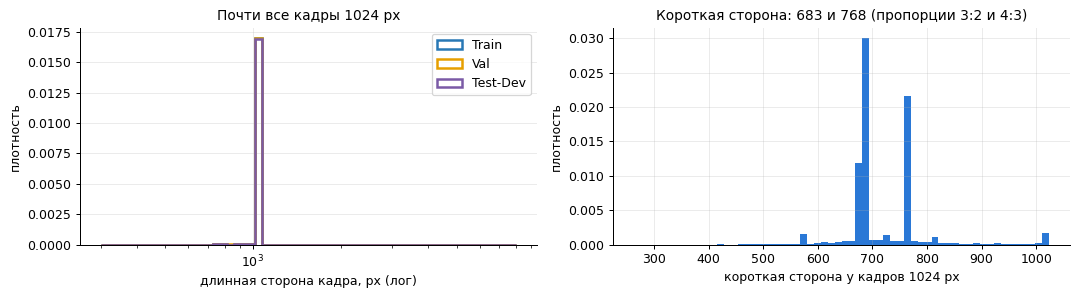

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
long_side = frames[["width", "height"]].max(axis=1)
for s in SPLITS:
    axes[0].hist(long_side[frames["split"] == s], bins=np.logspace(np.log10(300), np.log10(8000), 60), histtype="step", lw=2, density=True, color=SPLIT_COLOR[s], label=s)
axes[0].set_ylabel("плотность"); axes[0].set_xscale("log"); axes[0].set_xlabel("длинная сторона кадра, px (лог)"); axes[0].legend(); axes[0].set_title("Почти все кадры 1024 px")
short = frames[["width", "height"]].min(axis=1)
axes[1].hist(short[long_side == 1024], bins=60, density=True, color="#2a78d6"); axes[1].set_xlabel("короткая сторона у кадров 1024 px")
axes[1].set_ylabel("плотность")
axes[1].set_title("Короткая сторона: 683 и 768 (пропорции 3:2 и 4:3)")
plt.tight_layout(); plt.show()

**Итог A1.** Все 70 300 файлов читаются, размеры совпадают с JSON, все RGB. EXIF нет ни у одного файла,
поворотов нет. Все кадры сохранены JPEG качества 100 со стандартными таблицами. 99,0–99,3% кадров
уменьшены до 1024 px по длинной стороне. Значит, ни формат файла, ни размер кадра, ни метаданные не
могут отличать real от fake. Побайтовых копий (MD5) нет, но это не исключает дублей по содержимому
(шаг 2).

## A2. Геометрия разметки

In [68]:
g = faces
poly_area = np.array([polygon_area(s) for s in g["segmentation"]])
def poly_out(seg, x, y, w, h):
    p = np.concatenate([np.array(s, float).reshape(-1, 2) for s in seg])
    return max(0.0, np.maximum(x - p[:, 0], p[:, 0] - (x + w)).max(), np.maximum(y - p[:, 1], p[:, 1] - (y + h)).max())
out_px = np.array([poly_out(*r) for r in g[["segmentation", "x", "y", "w", "h"]].itertuples(index=False)])
a2 = pd.Series({
    "рамка выходит за кадр": int(((g["x"] < 0) | (g["y"] < 0) | (g["x"] + g["w"] > g["width"]) | (g["y"] + g["h"] > g["height"])).sum()),
    "ширина или высота рамки <= 0": int(((g["w"] <= 0) | (g["h"] <= 0)).sum()),
    "полигон выходит за рамку > 2 px": int((out_px > 2).sum()),
    "вырожденный полигон (площадь 0)": int((poly_area == 0).sum()),
    "маска из нескольких полигонов (лицо частично закрыто)": int((g["segmentation"].apply(len) > 1).sum()),
}, name="лиц").to_frame()
display(a2)

# area в JSON: геометрическая площадь полигона или число пикселей маски? Проверяем на 3 000 лицах
def mask_pixels_local(seg, x, y, w, h, pad=4):
    shifted = [(np.array(p, float).reshape(-1, 2) - [int(x) - pad, int(y) - pad]).ravel().tolist() for p in seg]
    return int(polygon_mask(shifted, int(h) + 2 * pad + 2, int(w) + 2 * pad + 2).sum())
smp = g.pipe(sample_rows, 3000, random_state=SEED)
ratio = pd.DataFrame({"side": smp["face_side_px"],
                      "area / пиксели маски": smp["area"] / [max(mask_pixels_local(*r), 1) for r in smp[["segmentation", "x", "y", "w", "h"]].itertuples(index=False)],
                      "area / площадь полигона": smp["area"] / np.maximum(poly_area[smp.index], 1)})
ratio.groupby(pd.cut(ratio["side"], [0, 32, 64, 128, 1e9]), observed=True)[["area / пиксели маски", "area / площадь полигона"]].median()

,лиц
рамка выходит за кадр,0
ширина или высота рамки <= 0,0
полигон выходит за рамку > 2 px,0
вырожденный полигон (площадь 0),14
маска из нескольких полигонов (лицо частично закрыто),22918


,area / пиксели маски,area / площадь полигона
side,,
"(0.0, 32.0]",1.009,1.209
"(32.0, 64.0]",0.990,1.032
"(64.0, 128.0]",0.994,1.016
"(128.0, 1000000000.0]",0.998,1.009


**Итог A2.** Рамок за кадром, нулевых рамок и полигонов, вылезающих за рамку, нет. Поле `area` равно
**числу пикселей маски** (отношение 0,99–1,01), а не геометрической площади полигона (у лиц < 32 px
разница до 20% из-за граничных пикселей), поэтому долю маски считаем по `area`. 14 полигонов
вырожденные. Многополигонные маски означают частично закрытые лица, это нормально.

## A3. Сверка со статьёй и кадры без разметки

статья                         JSON                       JSON - статья               
         кадров     лиц   real   fake кадров     лиц   real   fake        кадров  лиц real fake
Train     44122  151364  85392  65972  44097  150866  85006  65860           -25 -498 -386 -112
Val        7308   15352   4786  10566   7308   15345   4782  10563             0   -7   -4   -3
Test-Dev  18895   49750  21071  28670  18895   49718  21048  28670             0  -32  -23    0

Файлов на диске без записи в JSON: {'Train': 288, 'Val': 0, 'Test-Dev': 0}


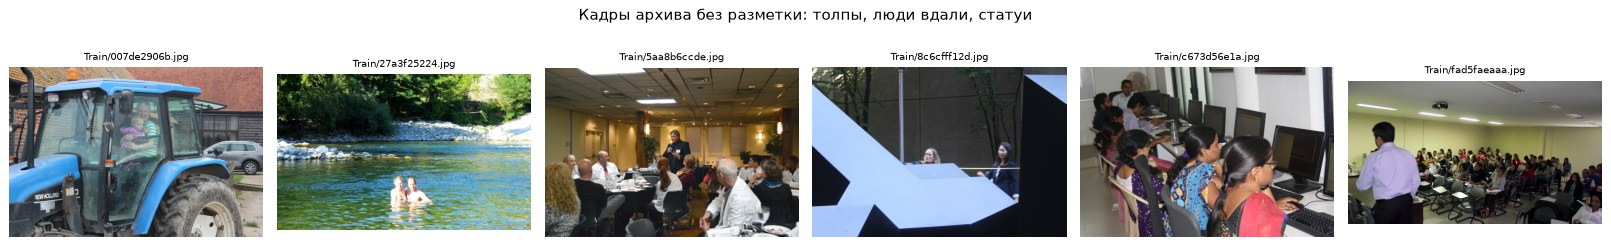

In [69]:
paper = pd.DataFrame({"кадров": [44122, 7308, 18895], "лиц": [151364, 15352, 49750], "real": [85392, 4786, 21071],
                      "fake": [65972, 10566, 28670]}, index=["Train", "Val", "Test-Dev"]).loc[SPLITS]
ours = pd.DataFrame({"кадров": frames.groupby("split").size(), "лиц": faces.groupby("split").size(),
                     "real": faces[faces["label"] == "real"].groupby("split").size(),
                     "fake": faces[faces["label"] == "fake"].groupby("split").size()}).loc[SPLITS]
display(pd.concat({"статья": paper, "JSON": ours, "JSON - статья": ours - paper}, axis=1))
orph = {s: sorted({p.name for p in (IMAGES / s).glob("*.jpg")} - {Path(f).name for f in frames.loc[frames["split"] == s, "file_name"]}) for s in SPLITS}
print("Файлов на диске без записи в JSON:", {s: len(v) for s, v in orph.items()})
extra = [(s, f) for s in SPLITS for f in orph[s]]
if extra:
    fig, axes = plt.subplots(1, 6, figsize=(18, 3))
    for ax, (s, f) in zip(axes, [extra[k] for k in np.linspace(0, len(extra) - 1, 6).astype(int)]):
        ax.imshow(read_rgb(IMAGES / s / f)); ax.axis("off"); ax.set_title(f"{s}/{f}", fontsize=8)
    fig.suptitle("Кадры архива без разметки: толпы, люди вдали, статуи")
    plt.tight_layout(); plt.show()

**Итог A3.** В JSON на 25 кадров и 498 лиц Train меньше, чем в таблице статьи (в основном real), в
Val и Test-Dev разница 7 и 32 лица; в самой статье для Test-Dev real + fake не сходится с итогом.
Номера кадров и лиц в JSON идут подряд, то есть записи не вырезали из готового файла. В архиве Train
лежат 288 кадров без разметки: сцены без «пригодных» лиц. Используем JSON, эти кадры исключаем.

## A4. Ключи разметки

In [70]:
keys = set(zip(frames["split"], frames["image_id"]))
pd.Series({
    "ключ кадра (split, image_id) уникален": not frames.duplicated(["split", "image_id"]).any(),
    "ключ лица (split, face_id) уникален": not faces.duplicated(["split", "face_id"]).any(),
    "каждое лицо ссылается на существующий кадр": set(zip(faces["split"], faces["image_id"])) <= keys,
    "у каждого кадра есть лицо": set(zip(faces["split"], faces["image_id"])) == keys,
    "метки только 0 и 1": faces["category_id"].isin([0, 1]).all(),
    "имена файлов уникальны": not frames["file_name"].duplicated().any(),
}, name="выполнено").to_frame()

,выполнено
"ключ кадра (split, image_id) уникален",True
"ключ лица (split, face_id) уникален",True
каждое лицо ссылается на существующий кадр,True
у каждого кадра есть лицо,True
метки только 0 и 1,True
имена файлов уникальны,True


## A5. Как dHash видит кадр

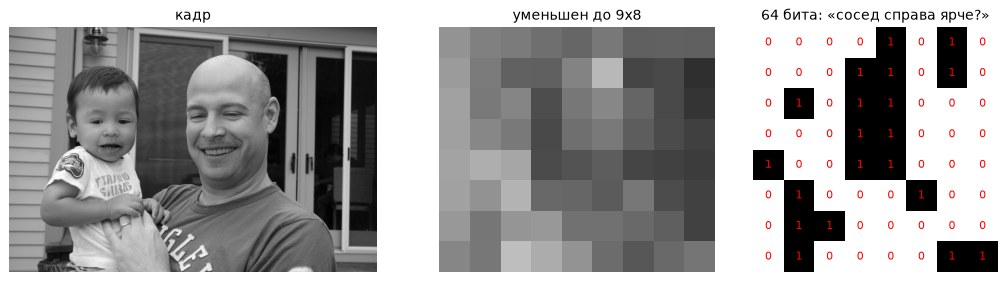

dHash = 0a1a581898446043


In [71]:
g0 = cv2.cvtColor(frame_img("Val", val_example_id), cv2.COLOR_RGB2GRAY)
small = cv2.resize(g0, (9, 8), interpolation=cv2.INTER_AREA)
bits = (small[:, 1:].astype(int) > small[:, :-1].astype(int)).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1.6, 1, 1]})
axes[0].imshow(g0, cmap="gray"); axes[0].set_title("кадр")
axes[1].imshow(small, cmap="gray", vmin=0, vmax=255); axes[1].set_title("уменьшен до 9x8")
axes[2].imshow(bits, cmap="Greys", vmin=0, vmax=1); axes[2].set_title("64 бита: «сосед справа ярче?»")
for (r, c), v in np.ndenumerate(bits):
    axes[2].text(c, r, v, ha="center", va="center", color="red", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()
print(f"dHash = {dhash(g0):016x}")